# EXP-036 — Lá có những bệnh nào (nhiều nhãn), detector YOLO NEG_V04

Với một ảnh lá, notebook này trả về **tập các bệnh có trên lá**. Mỗi bệnh có bằng chứng và box riêng, thay vì chỉ một nhãn. Ví dụ: lá có 5 box anthracnose và 5 box red_rust là lá có **2 bệnh**. Số bệnh là số loại bệnh được kết luận là có, không phụ thuộc số box. Số box và diện tích bị phủ chỉ mô tả mức độ nặng.

Không huấn luyện lại DenseNet121 hay YOLO. Dùng nguyên mô hình kết hợp EXP-035 (5 seed DenseNet121 + YOLO26s `EXP-Y26S-NEG-V04-001`) làm **cổng**: nếu EXP-035 dự đoán `healthy` hoặc `not_cashew_leaf` thì danh sách bệnh rỗng.

## Cách đọc các con số

| Thuật ngữ | Nghĩa | Ví dụ |
|---|---|---|
| **Precision** (độ chính xác khi báo) | Trong các ảnh mô hình nói "có bệnh X", bao nhiêu phần trăm thật sự có X | Báo red_rust trên 100 ảnh, 90 ảnh đúng có red_rust → precision 0.90 |
| **Recall** (độ phủ) | Trong các ảnh thật sự có bệnh X, mô hình tìm ra bao nhiêu phần trăm | 200 ảnh có anthracnose, mô hình nhận ra 170 → recall 0.85 |
| **F1** | Trung bình điều hòa của precision và recall; cao khi cả hai cùng cao | P = 0.90, R = 0.85 → F1 ≈ 0.87 |
| **Support** | Số ảnh thật sự có bệnh đó trong tập đánh giá | leaf_miner support = 60 nghĩa là 60 ảnh có leaf_miner |
| **Macro average** | Trung bình cộng các bệnh, mỗi bệnh nặng như nhau (chỉ tính bệnh có support > 0) | F1 = 0.9, 0.5, 0.8 → macro F1 = 0.73 |
| **Micro average** | Gộp tất cả quyết định có/không của mọi bệnh rồi mới tính; bệnh nhiều ảnh nặng hơn | Bệnh phổ biến chi phối kết quả |
| **Samples average** | Tính trên từng ảnh rồi lấy trung bình các ảnh | Ảnh có {A, R}, đoán {A} → F1 của ảnh = 0.67 |
| **Ma trận nhầm lẫn 2×2** | Mỗi bệnh: thật có/không × đoán có/không | Ô "thật có, đoán không" là số ảnh bị bỏ sót |
| **Ma trận nhầm lẫn theo tập** | Hàng: tập bệnh thật; cột: tập bệnh đoán | Hàng {A+R}, cột {A}: lá có 2 bệnh nhưng chỉ báo 1 |
| **Learning curve** (đường học) | Sai số trên dữ liệu học và dữ liệu kiểm tra khi tăng số ảnh học | Hai đường gần nhau và nằm ngang → thêm ảnh không giúp nhiều |
| **Exact-set match** | Tỷ lệ ảnh đoán **đúng toàn bộ** tập bệnh (không thừa, không thiếu) | Thật {A, R}, đoán {A, R} → đúng; đoán {A} → sai |
| **Hamming loss** | Tỷ lệ quyết định có/không bị sai, tính trên (số ảnh × 3 bệnh) | 1 sai trong 3 quyết định của 1 ảnh → 0.33 |
| **Reliability curve** (đường độ tin cậy) | Khi mô hình nói "70% có bệnh", thực tế có đúng khoảng 70% không | Điểm nằm trên đường chéo là xác suất đáng tin; ECE là độ lệch trung bình |
| **Khoảng Wilson 95%** | Khoảng chứa tỷ lệ thật với độ tin cậy 95% | 3/40 báo nhầm → 7.5% (khoảng 2.6%–19.9%) |
| **Bootstrap / McNemar** | So sánh hai quy tắc trên **cùng** ảnh; khoảng bootstrap không chứa 0 thì khác biệt khó do may rủi | Δ exact-match = +0.05 [0.02; 0.08] |

**Quy ước:** "đánh giá trên YOLO Test" là 488 ảnh của dataset YOLO NEG_V04 (nhãn bệnh lấy từ box). YOLO Test và Holdout không được dùng để chọn ngưỡng, `C` hay quy tắc.

## Thông tin thí nghiệm (header chuẩn V2)

- **Câu hỏi nghiên cứu:** quyết định có/không cho từng bệnh độc lập từ bằng chứng gộp (số box, tổng độ tin cậy, diện tích bị phủ, độ tin cậy cao nhất) có tìm ra bệnh thứ hai trên lá nhiễm nhiều bệnh tốt hơn quy tắc "độ tin cậy cao nhất" không, mà không báo bệnh nhầm trên lá khỏe?
- **Thí nghiệm cha:** `EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04`. Mô hình một nhãn đã khóa: Test 665/685 = 97.08 %, Holdout 119/126 = 94.44 % (chỉ mô tả).
- **Dữ liệu:** Split (13) SHA-256 `e1647b72…`; Holdout 09 (126 ảnh, không có box); YOLO `CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip` SHA-256 `4dca7b48…`. YOLO train/val/test = 3739/1076/488, ảnh nền 863/183/76.
- **Thứ tự lớp:** DenseNet `anthracnose, healthy, leaf_miner, red_rust, not_cashew_leaf`; detector `anthracnose, leaf_miner, red_rust`.
- **Seeds (chỉ cho cổng DenseNet):** 42, 123, 2026, 3407, 7777. Không huấn luyện lại DenseNet hay YOLO.
- **Detector:** `EXP-Y26S-NEG-V04-001` `best.pt` SHA-256 `f9dc3fba…`, conf 0.05, IoU 0.7, imgsz 640, giữ mọi box, NMS theo lớp IoU 0.5.
- **Chọn mô hình (chỉ trên Validation):** YOLO val (1076 ảnh) + ảnh âm sạch của DenseNet Validation; 5-fold CV nhóm theo cụm pHash (Hamming ≤ 4); `C` theo log loss; ngưỡng mỗi bệnh đạt recall ≥ 0.90 với precision tốt nhất. Ghi vào `frozen_config_036.json` và `validation_selection_lock.json` **trước khi** đọc YOLO Test.
- **Trạng thái mục tiêu:** `EVAL_ONLY` (dùng checkpoint EXP-035) → `SELECTION_LOCKED` → `TEST_COMPLETE` (YOLO Test, lần đầu cho mô hình có/không) + `HISTORICAL_HOLDOUT_EVAL` (Holdout đã xem ở EXP-032/035, chỉ mô tả).
- **Phần cứng:** Colab GPU. **Output schema:** 2.

### Quy trình
1. Nạp và xác minh SHA-256: Split13, Holdout 09, YOLO NEG_V04, `EXP-Y26S-NEG-V04-001_FULL.zip` (thống kê dataset) và ZIP FULL của EXP-035 (5 model, `best.pt`, stacker, dự đoán từng seed).
2. Tính lại số tham chiếu EXP-035 từ dự đoán đã lưu (665/685, 119/126). Sai thì dừng.
3. Tạo nhãn thật dạng tập bệnh từ file box, kiểm tra trùng ảnh (pixel SHA-256 + pHash).
4. Chạy detector trên dữ liệu Validation, fit mô hình có/không, **khóa** ngưỡng.
5. Chạy detector và cổng DenseNet trên YOLO Test, ảnh âm DenseNet Test và Holdout. Báo cáo không cổng, có cổng (ensemble), rồi từng seed, sau đó mới làm kiểm định thống kê.
6. Đóng gói `cashew_pipeline.py` với `analyze(image)`, kiểm tra nhất quán và xuất `EXP-036_ANALYSIS.zip` / `EXP-036_FULL.zip`.

`MODELS_DRIVE_FILE_ID` = `1IH_UpiGLikCoPoWWuHtxUhsS8gDD_6lb` (`EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04_FULL.zip`, lấy từ log upload của EXP-035). `EXP036_DRY_RUN=1` chỉ chạy dữ liệu tổng hợp với detector giả, không phải kết quả thực nghiệm.

In [1]:
# EXP-036 configuration and imports
import base64, csv, gc, hashlib, io, json, math, os, platform, shutil, stat, subprocess, sys, time, warnings, zipfile
from collections import Counter, defaultdict
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFont, ImageOps
from scipy import stats
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, log_loss, precision_recall_curve,
                             precision_recall_fscore_support)
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import joblib
import importlib.util

EXPERIMENT_ID = "EXP-036"
EXPERIMENT_NAME = "EXP-DENSENET121-YOLO-PRESENCE-036-NEGV04"
PARENT_EXPERIMENT_ID = "EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04"
SEEDS = [42, 123, 2026, 3407, 7777]
CLASSES = ["anthracnose", "healthy", "leaf_miner", "red_rust", "not_cashew_leaf"]
DETECTOR_CLASSES = ["anthracnose", "leaf_miner", "red_rust"]
DISEASES = list(DETECTOR_CLASSES)
CLASS_INDEX = {name: i for i, name in enumerate(CLASSES)}

# --- Pinned inputs (no retraining; every input checked by bytes and/or SHA256) ---
DATASET_ARCHIVE_NAME = "CashewData_Split (13).zip"
DATASET_ARCHIVE_FILE_ID = "1HUE5ObO1vW0mP2QjgsdObMuW4RVPzNk7"
DATASET_ARCHIVE_EXPECTED_BYTES = 1470301553
DATASET_ARCHIVE_SHA256 = "e1647b72e10af04275dc760545f4ef17c9f44343ae119495b89ba1e3cd954e04"
REAL_HOLDOUT_ARCHIVE_NAME = "RL_Cashew_holdout (9).zip"
REAL_HOLDOUT_ARCHIVE_FILE_ID = "1QW2JYx8K6zkTs9y34f39OTBlxUOjWosZ"
REAL_HOLDOUT_EXPECTED_BYTES = 370947341
YOLO_V04_DATASET_ARCHIVE_NAME = "CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip"
# Filled from the verified EXP-035 / EXP-Y26S-NEG-V04-001 download log; bytes and SHA256 are still checked.
YOLO_V04_DATASET_DRIVE_FILE_ID = "1V-_ebnmU6SUnNvXC3a2kQPCQvvTimFXr"
YOLO_V04_DATASET_DRIVE_FOLDER_ID = "16S4O-7f7Tl2_xb0JrB5b-PJZA0FqKQ1M"
YOLO_V04_DATASET_BYTES = 287009072
YOLO_V04_DATASET_SHA256 = "4dca7b48a07fb971ef7f4e7c3b8cbe5b67f17bc411a7d43c060cece2e9e5798b"
YOLO_SPLIT_IMAGES = {"train": 3739, "val": 1076, "test": 488}
YOLO_NEGATIVE_IMAGES = {"train": 863, "val": 183, "test": 76}
YOLO_TRAIN_NEGATIVE_GROUPS = {"healthy": 375, "non_cashew_diseased_leaf": 276, "not_cashew_leaf": 212}
YOLO_TEST_BOXES = {"anthracnose": 2907, "leaf_miner": 372, "red_rust": 14391}
YOLO_VAL_MULTI_DISEASE_REFERENCE = 503  # leaf_miner_failure_analysis.csv of EXP-Y26S-NEG-V04-001
DETECTOR_RUN_ID = "EXP-Y26S-NEG-V04-001"
DETECTOR_RUN_FULL_ZIP = "EXP-Y26S-NEG-V04-001_FULL.zip"
DETECTOR_RUN_FULL_ZIP_FILE_ID = "1DTTWYUWcDFJzHW-4p91Z2W8LJxiI8Zwq"
DETECTOR_RUN_FULL_ZIP_BYTES = 58702426
DETECTOR_WEIGHTS_SHA256 = "f9dc3fba1347b3213819f61abddb36b07e455112d4e6e8d57eeeeca8ab1b7f4a"
FORBIDDEN_DETECTOR_SHA256 = {
    "11f0da0c1adda42979b4a30862f44988b2ec297d6831802c6cdcbba96598a475":
        "EXP-Y26S-NEG-V04-002 best.pt (same outputs, but not the file EXP-035 used)"}
EXP035_FULL_ZIP_NAME = "EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04_FULL.zip"
EXP035_ROOT_NAME = "EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04"
# REQUIRED: Drive file ID of the EXP-035 FULL ZIP (uploaded to DRIVE_TARGET_FOLDER_ID by EXP-035).
MODELS_DRIVE_FILE_ID = "1IH_UpiGLikCoPoWWuHtxUhsS8gDD_6lb"  # EXP-035 FULL ZIP (verified upload log)
MODELS_ARCHIVE_OVERRIDE = None  # Optional local copy of the same ZIP; model SHA256 are still checked.
EXP035_MODEL_SHA256 = {
    42: "feb05191bddd7e2b29f88294bff215237cbbd5738067e6cc9c0b5ad9d52b20ef",
    123: "fd8350c417fc75d5dbedabb8be45c5e1f1575ccb5a2667ed9a68610c62717183",
    2026: "c24aefe0befbb14dfae07f713c7a6f1774caf2f9910e0608c4bf8f7a2d2559f3",
    3407: "3528277898238b5ffd456161c665adfef4699dcd19ff9b2632b5f08fda7f608a",
    7777: "042b4e65e73d3fc5b593276d219edd3215f0e8dc210c35d327d0336f3dc86409"}
EXP035_REFERENCE = {"test": (665, 685), "holdout": (119, 126)}
# Context only (section 7 table): V03 detector on the same YOLO-test images.
V03_CONTEXT = {"name": "EXP-Y26S-NEG-V03-001", "zip_name": "EXP-Y26S-NEG-V03-001_FULL.zip",
    "url": ("https://raw.githubusercontent.com/klongnguyen/KLTN_Cashew_Leaf_Disease_Classification/"
            "ac1efe16319052b6f08a3c41b4ec361bbbb19e2f/training_results/negative_evaluation/"
            "EXP-Y26S-NEG-V03-001_FULL.zip"),
    "zip_bytes": 51515079,
    "zip_sha256": "e1d3cc42afd356aaf3431486cb6f518344582e836872a36bfb651195deaf542d",
    "best_sha256": "66717b5523ba394443495378a326da26f0d24e98a331f98480f79d9d6fa18166",
    "override": None}
RUN_V03_CONTEXT = True
EXPECTED_NEGATIVES_WITH_BOX_CONF020 = {"EXP-Y26S-NEG-V04-001": 25, "EXP-Y26S-NEG-V03-001": 58}  # of 76
DATASET_ARCHIVE_OVERRIDE = None
REAL_HOLDOUT_ARCHIVE_OVERRIDE = None
YOLO_DATASET_OVERRIDE = None
DRIVE_TARGET_FOLDER_ID = "1DGKTnzsvVc60RIEn5lQgflR3s-loM24G"
UPLOAD_RESULT_ZIPS_TO_DRIVE = True

# --- Protocol, declared before any YOLO-test number is read ---
MIN_GT_BOXES, MIN_GT_BOXES_STRICT = 1, 3
RECALL_TARGET = 0.90
C_GRID = (0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0)
N_FOLDS, PHASH_HAMMING = 5, 4
LEARNING_CURVE_FRACTIONS = (0.1, 0.25, 0.5, 0.75, 1.0)
BOOTSTRAP_RESAMPLES, BOOTSTRAP_SEED = 10_000, 36036
RULES = ("any_box", "three_boxes", "max_conf_rule", "presence_model")
PROPOSED_RULE = "presence_model"
STRONGER_CONF_BINS = (0.0, 0.5, 0.8, 1.0001)
WEAKER_AREA_BINS = (0.0, 0.01, 0.05, 1.0001)
PASS_CRITERIA = {  # User-editable starting values (section 8). Never tuned after Test.
    "per_disease_recall_min": 0.85, "per_disease_precision_min": 0.80,
    "weaker_disease_recall_min": 0.70,
    "false_alarm_healthy_max": 0.10, "false_alarm_non_cashew_diseased_leaf_max": 0.20,
    "presence_beats_max_conf_weaker_recall_lower_bound_gt": 0.0}
FIXED_HOLDOUT_REVIEW = ["real_anthracnose_074", "real_anthracnose_091", "real_anthracnose_092",
                        "real_leaf_miner_128", "real_red_rust_047"]
N_FIXED_TEST_PANEL, N_CONSISTENCY_IMAGES = 6, 20
DISEASE_INFO_PLACEHOLDER = "CHỜ CHUYÊN GIA ĐIỀN"

DRY_RUN = os.environ.get("EXP036_DRY_RUN") == "1"  # Synthetic fixture + stub detector; never a result.
if DRY_RUN:
    UPLOAD_RESULT_ZIPS_TO_DRIVE = False
    BOOTSTRAP_RESAMPLES = 400
else:
    if not (isinstance(YOLO_V04_DATASET_DRIVE_FILE_ID, str) and YOLO_V04_DATASET_DRIVE_FILE_ID.strip()):
        raise ValueError("Fill YOLO_V04_DATASET_DRIVE_FILE_ID with the Drive file ID of "
                         "CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip (folder 16S4O-7f7Tl2_xb0JrB5b-PJZA0FqKQ1M).")
    if not (isinstance(MODELS_DRIVE_FILE_ID, str) and MODELS_DRIVE_FILE_ID.strip()):
        raise ValueError("Fill MODELS_DRIVE_FILE_ID with the Drive file ID of " + EXP035_FULL_ZIP_NAME +
                         " (Drive folder " + DRIVE_TARGET_FOLDER_ID + ").")
    for package, module in (("google-api-python-client", "googleapiclient"), ("google-auth", "google.auth")):
        try:
            found = importlib.util.find_spec(module)
        except ModuleNotFoundError:
            found = None
        if found is None:
            subprocess.check_call([sys.executable, "-m", "pip", "install", package])

PROJECT_ROOT = Path("/content") if Path("/content").is_dir() else Path.cwd()
OUT_DIR = PROJECT_ROOT / "training_results" / "current_dataset" / (EXPERIMENT_ID + ("-DRYRUN" if DRY_RUN else ""))
AGGREGATE = OUT_DIR / "aggregate"
FIGURES = OUT_DIR / "figures"
PANELS = FIGURES / "panels"
for folder in (AGGREGATE, FIGURES, PANELS):
    folder.mkdir(parents=True, exist_ok=True)
STAGE_ROOT = PROJECT_ROOT / "exp036_inputs"

# --- Reused verbatim from EXP-035 cell 'EXP-035 combined training configuration and imports': file_md5, file_sha256, write_json, unique_keys, checked_join ---
def file_md5(path):
    digest = hashlib.md5()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 << 20), b""):
            digest.update(block)
    return digest.hexdigest()

def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 << 20), b""):
            digest.update(block)
    return digest.hexdigest()

def write_json(path, value):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(value, indent=2, sort_keys=True, default=str), encoding="utf-8")

def unique_keys(frame, label):
    if frame["evidence_key"].duplicated().any():
        raise ValueError(f"{label}: duplicate split/class/filename keys")
    if any(len(str(key).split("/")) != 3 for key in frame["evidence_key"]):
        raise ValueError(f"{label}: keys must be split/class/filename")

def checked_join(left, right, label):
    unique_keys(left, label + " left")
    unique_keys(right, label + " right")
    a, b = set(left.evidence_key), set(right.evidence_key)
    if a != b:
        raise ValueError(f"{label}: key mismatch; missing={sorted(a-b)[:3]} extra={sorted(b-a)[:3]}")
    return left.merge(right, on="evidence_key", validate="one_to_one")
# --- end of reused EXP-035 code ---

def assert_set_equal(left, right, label):
    left, right = set(left), set(right)
    if left != right:
        raise ValueError(f"{label}: key sets differ; missing={sorted(right-left)[:3]} extra={sorted(left-right)[:3]}")

# One implementation for batch evaluation and for analyze() in cashew_pipeline.py.
PRESENCE_CORE_SOURCE = '# ---------------------------------------------------------------------------\n# EXP-036 presence extension. Appended verbatim to the EXP-035 cashew_pipeline.py\n# and executed inside the EXP-036 notebook, so batch results and analyze() share\n# one implementation. Output: the SET of diseases present on one leaf photo.\n# ---------------------------------------------------------------------------\nimport json as _p_json\nfrom pathlib import Path as _P_Path\nimport numpy as _p_np\n\nPRESENCE_VERSION = "EXP-036"\nPRESENCE_DISEASES = ("anthracnose", "leaf_miner", "red_rust")\nPRESENCE_DETECT = {"conf": 0.05, "iou": 0.7, "imgsz": 640, "max_det": 1000, "rect": False}\nPRESENCE_NMS_IOU = 0.5          # class-wise greedy NMS applied after the detector\nGATE_TOP_BOXES = 300            # EXP-035 evidence came from Ultralytics max_det=300\nCOUNT_CONFS = (0.10, 0.25, 0.50)\nDISPLAY_CONF = 0.25             # boxes listed / drawn for a reported disease\nPRESENCE_FEATURES = ("log1p_n_ge_0.10", "log1p_n_ge_0.25", "log1p_n_ge_0.50",\n                     "log1p_sum_conf", "coverage", "max_conf")\nNEGATIVE_LABELS = ("healthy", "not_cashew_leaf")\nSTUB_COLORS = {"anthracnose": (255, 0, 0), "leaf_miner": (0, 255, 0), "red_rust": (0, 0, 255)}\nDRAW_COLORS = {"anthracnose": (0, 114, 178), "leaf_miner": (230, 159, 0), "red_rust": (213, 94, 0)}\nMESSAGE_NO_DISEASE = "không phát hiện bệnh"\nMESSAGE_EXPERT = "cần chuyên gia kiểm tra"\nDISCLAIMER_VI = "Kết quả chỉ mang tính tham khảo; cần cán bộ kỹ thuật xác nhận trước khi xử lý."\n\n\ndef presence_iou(a, b):\n    x1, y1, x2, y2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])\n    inter = max(0.0, x2 - x1) * max(0.0, y2 - y1)\n    aa = max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1])\n    bb = max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])\n    return inter / (aa + bb - inter) if aa + bb > inter else 0.0\n\n\ndef stub_detect(rgb):\n    """DRY-RUN ONLY detector stub: one box per pure stub-colour region plus one weak box."""\n    rgb = _p_np.asarray(rgb)\n    h, w = int(rgb.shape[0]), int(rgb.shape[1])\n    boxes = []\n    for cls in PRESENCE_DISEASES:\n        mask = _p_np.all(rgb[:, :, :3] == _p_np.array(STUB_COLORS[cls], dtype=rgb.dtype), axis=2)\n        if not mask.any():\n            continue\n        ys, xs = _p_np.nonzero(mask)\n        conf = float(min(0.95, 0.30 + 6.0 * float(mask.mean())))\n        boxes.append({"cls": cls, "conf": round(conf, 6),\n                      "xyxy": [float(xs.min()), float(ys.min()), float(xs.max() + 1), float(ys.max() + 1)]})\n    weak_cls = PRESENCE_DISEASES[int(rgb[0, 0, 0]) % 3]\n    boxes.append({"cls": weak_cls, "conf": round(0.06 + (int(rgb[0, 0, 1]) % 10) / 100.0, 6),\n                  "xyxy": [0.0, 0.0, w / 4.0, h / 4.0]})\n    boxes.sort(key=lambda b: -b["conf"])\n    return boxes, (h, w)\n\n\ndef detect_raw(detector, source, rgb=None):\n    """Raw detector boxes sorted by confidence, and (height, width) of the image."""\n    if detector is None:\n        if rgb is None:\n            from PIL import Image as _PImage\n            with _PImage.open(source) as handle:\n                rgb = _p_np.asarray(handle.convert("RGB"))\n        return stub_detect(rgb)\n    result = detector.predict(source, verbose=False, **PRESENCE_DETECT)[0]\n    boxes = [{"cls": PRESENCE_DISEASES[int(c)], "conf": float(q), "xyxy": [float(v) for v in xy]}\n             for c, q, xy in zip(result.boxes.cls.cpu().numpy(), result.boxes.conf.cpu().numpy(),\n                                 result.boxes.xyxy.cpu().numpy())]\n    boxes.sort(key=lambda b: -b["conf"])\n    return boxes, (int(result.orig_shape[0]), int(result.orig_shape[1]))\n\n\ndef gate_evidence(raw, h, w):\n    """EXP-035 F3 evidence (max_conf, n_boxes, area_frac) from the top-300 raw boxes."""\n    top = raw[:GATE_TOP_BOXES]\n    out = {"max_conf": {}, "n_boxes": {}, "area_frac": {}}\n    for cls in PRESENCE_DISEASES:\n        part = [b for b in top if b["cls"] == cls]\n        out["max_conf"][cls] = max([b["conf"] for b in part], default=0.0)\n        out["n_boxes"][cls] = len(part)\n        area = sum((b["xyxy"][2] - b["xyxy"][0]) * (b["xyxy"][3] - b["xyxy"][1]) for b in part)\n        out["area_frac"][cls] = float(min(area / float(w * h), 1.0)) if part else 0.0\n    return out\n\n\ndef gate_label(stacker, config035, dense_probs, evidence):\n    """Label of the frozen EXP-035 combined model (argmax; temperature does not change it)."""\n    classes = list(config035["classes"])\n    feature = _p_np.array(list(dense_probs) + [evidence[prefix][cls] for prefix in\n                          ("max_conf", "n_boxes", "area_frac") for cls in config035["detector_classes"]],\n                          dtype=float)\n    fitted = stacker.predict_proba(feature[None, :])[0]\n    p = _p_np.zeros(len(classes))\n    p[stacker[-1].classes_] = fitted\n    t = float(config035["temperature"]["F3"])\n    p = _p_np.clip(p, 1e-9, 1) ** (1 / t)\n    p = p / p.sum()\n    return classes[int(_p_np.argmax(p))], p\n\n\ndef classwise_nms(raw, iou_threshold=PRESENCE_NMS_IOU):\n    kept = []\n    for box in raw:\n        if all(box["cls"] != old["cls"] or presence_iou(box["xyxy"], old["xyxy"]) <= iou_threshold\n               for old in kept):\n            kept.append(box)\n    return kept\n\n\ndef union_area(xyxys, w, h):\n    rects = []\n    for x1, y1, x2, y2 in xyxys:\n        x1, x2 = max(0.0, min(float(x1), w)), max(0.0, min(float(x2), w))\n        y1, y2 = max(0.0, min(float(y1), h)), max(0.0, min(float(y2), h))\n        if x2 > x1 and y2 > y1:\n            rects.append((x1, y1, x2, y2))\n    if not rects:\n        return 0.0\n    xs = _p_np.unique([r[0] for r in rects] + [r[2] for r in rects])\n    ys = _p_np.unique([r[1] for r in rects] + [r[3] for r in rects])\n    mask = _p_np.zeros((len(ys) - 1, len(xs) - 1), dtype=bool)\n    for x1, y1, x2, y2 in rects:\n        i0, i1 = _p_np.searchsorted(xs, [x1, x2])\n        j0, j1 = _p_np.searchsorted(ys, [y1, y2])\n        mask[j0:j1, i0:i1] = True\n    return float((mask * _p_np.outer(_p_np.diff(ys), _p_np.diff(xs))).sum())\n\n\ndef presence_features(raw, h, w):\n    """Per disease: raw evidence after class-wise NMS, plus the boxes shown to the user."""\n    kept = classwise_nms(raw)\n    out = {}\n    for cls in PRESENCE_DISEASES:\n        part = [b for b in kept if b["cls"] == cls]\n        conf = _p_np.array([b["conf"] for b in part], dtype=float)\n        shown = [b for b in part if b["conf"] >= DISPLAY_CONF]\n        out[cls] = {\n            "n_ge_0.10": int((conf >= 0.10).sum()), "n_ge_0.25": int((conf >= 0.25).sum()),\n            "n_ge_0.50": int((conf >= 0.50).sum()), "sum_conf": float(conf.sum()),\n            "coverage": union_area([b["xyxy"] for b in part], w, h) / float(w * h),\n            "max_conf": float(conf.max()) if len(conf) else 0.0,\n            "display_coverage": union_area([b["xyxy"] for b in shown], w, h) / float(w * h),\n            "boxes": [{"xyxy": [round(float(v), 4) for v in b["xyxy"]], "conf": round(float(b["conf"]), 6)}\n                      for b in shown]}\n    return out\n\n\ndef presence_vector(feature):\n    return _p_np.array([_p_np.log1p(feature["n_ge_0.10"]), _p_np.log1p(feature["n_ge_0.25"]),\n                        _p_np.log1p(feature["n_ge_0.50"]), _p_np.log1p(feature["sum_conf"]),\n                        feature["coverage"], feature["max_conf"]], dtype=float)\n\n\ndef presence_probabilities(models, features):\n    return {cls: float(models[cls].predict_proba(presence_vector(features[cls])[None, :])[0, 1])\n            for cls in PRESENCE_DISEASES}\n\n\ndef rule_sets(features, probs, config036):\n    out = {}\n    out["any_box"] = [c for c in PRESENCE_DISEASES if features[c]["n_ge_0.25"] >= 1]\n    out["three_boxes"] = [c for c in PRESENCE_DISEASES if features[c]["n_ge_0.25"] >= 3]\n    out["max_conf_rule"] = [c for c in PRESENCE_DISEASES\n                            if features[c]["max_conf"] >= config036["max_conf_thresholds"][c]]\n    out["presence_model"] = [c for c in PRESENCE_DISEASES\n                             if probs[c] >= config036["presence_thresholds"][c]]\n    return out\n\n\ndef presence_result(dense_probs, raw, h, w, stacker, config035, models, config036):\n    """The web JSON for one image, from DenseNet probabilities and raw detector boxes."""\n    label, _ = gate_label(stacker, config035, dense_probs, gate_evidence(raw, h, w))\n    features = presence_features(raw, h, w)\n    probs = presence_probabilities(models, features)\n    chosen = [] if label in NEGATIVE_LABELS else rule_sets(features, probs, config036)["presence_model"]\n    abstain = label not in NEGATIVE_LABELS and not chosen\n    diseases = [{"name": c, "present_prob": round(probs[c], 6), "n_lesions": len(features[c]["boxes"]),\n                 "coverage_percent": round(100.0 * features[c]["display_coverage"], 4),\n                 "max_confidence": round(features[c]["max_conf"], 6), "boxes": features[c]["boxes"]}\n                for c in chosen]\n    message = (MESSAGE_EXPERT if abstain else MESSAGE_NO_DISEASE if not diseases\n               else f"phát hiện {len(diseases)} bệnh")\n    return {"image_label": label, "abstain": bool(abstain), "diseases": diseases,\n            "severity_order": [d["name"] for d in sorted(diseases, key=lambda d: -d["coverage_percent"])],\n            "version": PRESENCE_VERSION, "message_vi": message, "disclaimer_vi": DISCLAIMER_VI}\n\n\ndef draw_analysis(rgb, result):\n    """Draw the reported boxes; line width max(3, round(0.004 * max(h, w)))."""\n    from PIL import Image as _PImage, ImageDraw as _PDraw\n    image = _PImage.fromarray(_p_np.asarray(rgb, dtype=_p_np.uint8)).convert("RGB")\n    width = max(3, round(0.004 * max(image.size)))\n    draw = _PDraw.Draw(image)\n    for disease in result["diseases"]:\n        for box in disease["boxes"]:\n            draw.rectangle([float(v) for v in box["xyxy"]], outline=DRAW_COLORS[disease["name"]], width=width)\n    return image\n\n\ndef _presence_analyze(self, image_path_or_array):\n    """EXP-036: set of diseases present on one leaf photo (JSON-ready dict)."""\n    if not hasattr(self, "presence_config"):\n        import joblib as _p_joblib\n        self.presence_config = _p_json.loads((self.bundle_dir / "frozen_config_036.json").read_text(encoding="utf-8"))\n        self.presence_models = _p_joblib.load(self.bundle_dir / "presence_models.joblib")\n    path = _P_Path(image_path_or_array) if isinstance(image_path_or_array, (str, _P_Path)) else None\n    if path is not None:\n        image = tf.io.decode_image(tf.io.read_file(str(path)), channels=3, expand_animations=False).numpy()\n        source, rgb = str(path), None\n    else:\n        image = _p_np.asarray(image_path_or_array)\n        if image.ndim == 2:\n            image = _p_np.repeat(image[..., None], 3, axis=2)\n        elif image.ndim == 3 and image.shape[2] == 1:\n            image = _p_np.repeat(image, 3, axis=2)\n        elif image.ndim == 3 and image.shape[2] == 4:\n            image = image[:, :, :3]\n        if image.ndim != 3 or image.shape[2] != 3:\n            raise ValueError("Expected RGB or grayscale image")\n        image = _p_np.clip(image, 0, 255).astype(_p_np.uint8)\n        source, rgb = _p_np.ascontiguousarray(image[:, :, ::-1]), image  # Ultralytics arrays are BGR\n    resized = tf.image.resize(tf.cast(image, tf.float32), (256, 256)).numpy()[None, ...]\n    dense = _p_np.mean([model.predict(resized, verbose=0)[0] for model in self.models], axis=0)\n    raw, (h, w) = detect_raw(self.detector, source, rgb)\n    return presence_result(dense, raw, h, w, self.stackers["F3"], self.config,\n                           self.presence_models, self.presence_config)\n\n\nif "CashewPipeline" in globals():\n    CashewPipeline.analyze = _presence_analyze\n    _PRESENCE_PIPELINE = {}\n\n    def analyze(image, bundle_dir=None):\n        """Module-level entry point for the web page: analyze(image) -> dict."""\n        root = _P_Path(bundle_dir) if bundle_dir else _P_Path(__file__).resolve().parent\n        if root not in _PRESENCE_PIPELINE:\n            _PRESENCE_PIPELINE[root] = CashewPipeline(root)\n        return _PRESENCE_PIPELINE[root].analyze(image)\n'
exec(compile(PRESENCE_CORE_SOURCE, "exp036_presence_core", "exec"), globals())
assert tuple(DISEASES) == PRESENCE_DISEASES

print(EXPERIMENT_ID, EXPERIMENT_NAME, "| python", platform.python_version(), "| dry_run", DRY_RUN)
print("Detector", DETECTOR_RUN_ID, "best.pt", DETECTOR_WEIGHTS_SHA256[:16],
      "| presence detector call", PRESENCE_DETECT, "| class-wise NMS IoU", PRESENCE_NMS_IOU)
print("Pass criteria (declared before Test):", PASS_CRITERIA)

EXP-036 EXP-DENSENET121-YOLO-PRESENCE-036-NEGV04 | python 3.13.16 | dry_run False
Detector EXP-Y26S-NEG-V04-001 best.pt f9dc3fba1347b321 | presence detector call {'conf': 0.05, 'iou': 0.7, 'imgsz': 640, 'max_det': 1000, 'rect': False} | class-wise NMS IoU 0.5
Pass criteria (declared before Test): {'per_disease_recall_min': 0.85, 'per_disease_precision_min': 0.8, 'weaker_disease_recall_min': 0.7, 'false_alarm_healthy_max': 0.1, 'false_alarm_non_cashew_diseased_leaf_max': 0.2, 'presence_beats_max_conf_weaker_recall_lower_bound_gt': 0.0}


In [2]:
# Chart style (EXP-035 conventions) and Vietnamese glyph check.
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ft2font import FT2Font
from matplotlib.text import Text
try:
    from IPython.display import display, Markdown
except ImportError:  # Local dry run without Jupyter.
    def display(value):
        print(value)
    def Markdown(value):
        return value

FONT_PATH = Path(matplotlib.get_data_path()) / "fonts" / "ttf" / "DejaVuSans.ttf"
assert FONT_PATH.is_file(), FONT_PATH
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
                     "font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False})
_FT = FT2Font(str(FONT_PATH))

def missing_glyphs(text):
    return sorted({ch for ch in str(text) if not ch.isspace() and _FT.get_char_index(ord(ch)) == 0})

FONT_TEST = "Từ chối: cần chuyên gia kiểm tra"
assert not missing_glyphs(FONT_TEST), missing_glyphs(FONT_TEST)
with warnings.catch_warnings(record=True) as _caught:
    warnings.simplefilter("always")
    _fig, _ax = plt.subplots(figsize=(4, .6))
    _ax.axis("off")
    _ax.text(0, .5, FONT_TEST)
    _fig.canvas.draw()
    plt.close(_fig)
_glyph_warnings = [str(w.message) for w in _caught if "glyph" in str(w.message).lower()]
assert not _glyph_warnings, _glyph_warnings
PANEL_FONT = ImageFont.truetype(str(FONT_PATH), 16)
assert PANEL_FONT.getbbox(FONT_TEST)[2] > 0
print("Vietnamese glyph check PASS:", FONT_PATH.name, "|", FONT_TEST)

# Okabe-Ito colour-blind-safe palette.
RULE_COLORS = {"any_box": "#E69F00", "three_boxes": "#56B4E9", "max_conf_rule": "#009E73",
               "presence_model": "#0072B2"}
RULE_LABELS = {"any_box": "≥1 box (conf ≥ 0.25)", "three_boxes": "≥3 box (conf ≥ 0.25)",
               "max_conf_rule": "Độ tin cậy cao nhất ≥ ngưỡng", "presence_model": "Mô hình có/không (đề xuất)"}
DISEASE_COLORS = {"anthracnose": "#0072B2", "leaf_miner": "#E69F00", "red_rust": "#D55E00"}
SEED_COLORS = dict(zip(SEEDS, ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00"]))
GROUP_LABELS = {"healthy": "Lá điều khỏe", "non_cashew_diseased_leaf": "Lá cây khác có bệnh",
                "not_cashew_leaf": "Không phải lá điều", "not_cashew_leaf_yolo": "Không phải lá điều (YOLO)"}
SHORT = {"anthracnose": "A", "leaf_miner": "L", "red_rust": "R"}

def save_figure(fig, name, data):
    """Save PNG (200 dpi) + the CSV of every plotted number, show inline, check glyphs."""
    texts = [t.get_text() for t in fig.findobj(Text) if t.get_text()]
    bad = sorted({ch for t in texts for ch in missing_glyphs(t)})
    if bad:
        raise RuntimeError(f"{name}: glyphs missing from {FONT_PATH.name}: {bad}")
    path = FIGURES / name
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    fig.savefig(path, dpi=200, bbox_inches="tight")
    if data is None or len(data) == 0:
        raise RuntimeError(f"{name}: every figure needs its plotted numbers as CSV")
    pd.DataFrame(data).to_csv(path.with_suffix(".csv"), index=False)
    plt.show()
    plt.close(fig)
    return path

def wilson_interval(k, n):
    if n == 0:
        return (float("nan"), float("nan"))
    z = 1.959963984540054
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    r = z * math.sqrt((p * (1 - p) + z * z / (4 * n)) / n) / d
    return (max(0.0, c - r), min(1.0, c + r))

def yerr_from(mid, low, high):
    """Interval bounds -> non-negative Matplotlib error distances (round-off at 0/1 allowed)."""
    mid, low, high = (np.asarray(v, dtype=float) for v in (mid, low, high))
    return np.vstack([np.clip(mid - low, 0, None), np.clip(high - mid, 0, None)])

def markdown_table(frame, digits=4):
    frame = frame.copy()
    for col in frame.columns:
        if pd.api.types.is_float_dtype(frame[col]):
            frame[col] = frame[col].map(lambda v: "null" if pd.isna(v) else f"{v:.{digits}f}")
    cols = [str(c) for c in frame.columns]
    lines = ["| " + " | ".join(cols) + " |", "|" + "|".join("---" for _ in cols) + "|"]
    for row in frame.itertuples(index=False, name=None):
        lines.append("| " + " | ".join(str(v).replace("|", "/") for v in row) + " |")
    return "\n".join(lines)

Vietnamese glyph check PASS: DejaVuSans.ttf | Từ chối: cần chuyên gia kiểm tra


## 1. Nạp dữ liệu đã khóa

Mọi input được kiểm tra bằng dung lượng và/hoặc SHA-256: Split13, Holdout 09, dataset YOLO NEG_V04, `EXP-Y26S-NEG-V04-001_FULL.zip` (lấy `dataset_statistics.json` để đối chiếu số box) và ZIP FULL của EXP-035 (5 model DenseNet121, `best.pt`, stacker, dự đoán từng seed). Sai một mã là dừng.

In [3]:
# Stage pinned inputs. Archive helpers reused from EXP-035 by header.
# --- Reused verbatim from EXP-035 cell 'Stage pinned inputs.': archive_sha256, source_archive, extract_verified, image_files, dataset_root ---
def archive_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(8 << 20), b''):
            digest.update(block)
    return digest.hexdigest()

def source_archive(file_id, name, expected_bytes, override):
    if override:
        path = Path(override).expanduser()
        if not path.is_file():
            raise FileNotFoundError(f'Archive override missing: {path}')
    else:
        path = STAGE_ROOT / 'archives' / name
        path.parent.mkdir(parents=True, exist_ok=True)
        if not path.is_file() or path.stat().st_size != expected_bytes or not zipfile.is_zipfile(path):
            if not file_id:
                raise FileNotFoundError(f'{name}: set a Drive file ID or archive override')
            import google.auth
            from googleapiclient.discovery import build
            from googleapiclient.http import MediaIoBaseDownload
            if Path('/content').is_dir():
                from google.colab import auth
                auth.authenticate_user()
            credentials, _ = google.auth.default(scopes=['https://www.googleapis.com/auth/drive.readonly'])
            service = build('drive', 'v3', credentials=credentials, cache_discovery=False)
            meta = service.files().get(fileId=file_id, fields='id,name,size,md5Checksum',
                                       supportsAllDrives=True).execute()
            if meta['name'] != name or int(meta['size']) != expected_bytes:
                raise ValueError(f'Drive source differs from expected {name}: {meta}')
            partial = path.with_suffix(path.suffix + '.part')
            request = service.files().get_media(fileId=file_id, supportsAllDrives=True)
            with partial.open('wb') as stream:
                downloader = MediaIoBaseDownload(stream, request, chunksize=8 << 20)
                done = False
                while not done:
                    progress, done = downloader.next_chunk(num_retries=3)
                    if progress:
                        print(name, f'{progress.progress():.0%}')
            if partial.stat().st_size != expected_bytes or not zipfile.is_zipfile(partial):
                raise RuntimeError(f'Incomplete archive download: {name}')
            if meta.get('md5Checksum'):
                digest = hashlib.md5()
                with partial.open('rb') as stream:
                    for block in iter(lambda: stream.read(8 << 20), b''):
                        digest.update(block)
                if digest.hexdigest() != meta['md5Checksum']:
                    raise RuntimeError(f'Drive MD5 mismatch: {name}')
            partial.replace(path)
    if path.stat().st_size != expected_bytes or not zipfile.is_zipfile(path):
        raise ValueError(f'Archive size/type mismatch: {path}')
    return path

def extract_verified(archive_path, destination):
    archive_path, destination = Path(archive_path), Path(destination)
    checksum = archive_sha256(archive_path)
    marker = destination / '.archive_sha256'
    if destination.is_dir():
        if not marker.is_file() or marker.read_text(encoding='utf-8').strip() != checksum:
            raise RuntimeError(f'Unverified/incomplete extraction: {destination}')
        return destination
    staging = destination.with_name(destination.name + '_staging')
    if staging.exists():
        raise RuntimeError(f'Incomplete staging directory: {staging}')
    staging.mkdir(parents=True)
    with zipfile.ZipFile(archive_path) as archive:
        resolved_root = staging.resolve()
        for member in archive.infolist():
            target = (staging / member.filename.replace('\\', '/')).resolve()
            if (stat.S_ISLNK(member.external_attr >> 16) or
                    not target.is_relative_to(resolved_root)):
                raise ValueError(f'Unsafe archive member: {member.filename}')
        archive.extractall(staging)
    (staging / '.archive_sha256').write_text(checksum + '\n', encoding='utf-8')
    staging.rename(destination)
    return destination

def image_files(root):
    return sorted(p for p in Path(root).rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES)

def dataset_root(extracted, kind):
    candidates = [Path(extracted), *[p for p in Path(extracted).rglob("*") if p.is_dir()]]
    if kind == "split13":
        matches = [p for p in candidates if (p / "train").is_dir() and (p / "val").is_dir() and (p / "test").is_dir()]
    elif kind == "holdout09":
        matches = [p for p in candidates if all((p / c).is_dir() for c in CLASSES[:4]) and
                   len([q for q in p.iterdir() if q.is_dir()]) == 4]
    elif kind == "yolo":
        matches = [p for p in candidates if all((p / "images" / s).is_dir() and (p / "labels" / s).is_dir()
                   for s in ("train", "val", "test"))]
    else:
        raise ValueError(kind)
    if len(matches) != 1:
        raise RuntimeError(f"{kind}: expected one root, found {matches}")
    return matches[0]
# --- end of reused EXP-035 code ---

IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
# Dry-run fixture only: the EXP-035 module source, embedded by the build script.
EXP035_PIPELINE_SOURCE_FOR_FIXTURE = '"""Standalone EXP-035 Cashew + YOLO pipeline. Generated from notebook source."""\nimport json\nfrom pathlib import Path\nimport joblib\nimport numpy as np\nimport tensorflow as tf\nfrom tensorflow import keras\nfrom tensorflow.keras import layers\nfrom PIL import Image, ImageOps\n\n@keras.utils.register_keras_serializable(package="exp029", name="RandomHSVJitter")\nclass RandomHSVJitter(layers.Layer):\n    """Per-image saturation scaling, hue shift and random grayscale.\n\n    Active only when training=True so the Validation/Test/holdout path stays\n    a pure identity, which the smoke test below asserts.\n    """\n\n    def __init__(self, saturation_range=(0.6, 1.4), hue_delta=0.03,\n                 grayscale_probability=0.10, value_range=(0.0, 255.0),\n                 seed=None, **kwargs):\n        super().__init__(**kwargs)\n        if not (0.0 < saturation_range[0] <= 1.0 <= saturation_range[1]):\n            raise ValueError("saturation_range must bracket 1.0")\n        if not 0.0 <= hue_delta <= 0.5:\n            raise ValueError("hue_delta must be within [0, 0.5]")\n        if not 0.0 <= grayscale_probability <= 1.0:\n            raise ValueError("grayscale_probability must be within [0, 1]")\n        self.saturation_range = tuple(float(v) for v in saturation_range)\n        self.hue_delta = float(hue_delta)\n        self.grayscale_probability = float(grayscale_probability)\n        self.value_range = tuple(float(v) for v in value_range)\n        self.seed = seed\n        self.seed_generator = keras.random.SeedGenerator(seed)\n\n    def call(self, inputs, training=False):\n        if not training:\n            return inputs\n        low, high = self.value_range\n        span = high - low\n        normalized = tf.clip_by_value((inputs - low) / span, 0.0, 1.0)\n        batch = tf.shape(normalized)[0]\n        saturation = keras.random.uniform(\n            (batch, 1, 1), self.saturation_range[0], self.saturation_range[1],\n            seed=self.seed_generator)\n        grayscale_draw = keras.random.uniform(\n            (batch, 1, 1), 0.0, 1.0, seed=self.seed_generator)\n        saturation = tf.where(grayscale_draw < self.grayscale_probability,\n                              tf.zeros_like(saturation), saturation)\n        hue_shift = keras.random.uniform(\n            (batch, 1, 1), -self.hue_delta, self.hue_delta, seed=self.seed_generator)\n        hsv = tf.image.rgb_to_hsv(normalized)\n        hue = tf.math.floormod(hsv[..., 0] + hue_shift, 1.0)\n        sat = tf.clip_by_value(hsv[..., 1] * saturation, 0.0, 1.0)\n        value = hsv[..., 2]\n        converted = tf.image.hsv_to_rgb(tf.stack([hue, sat, value], axis=-1))\n        return tf.clip_by_value(converted * span + low, low, high)\n\n    def compute_output_shape(self, input_shape):\n        return input_shape\n\n    def get_config(self):\n        config = super().get_config()\n        config.update({"saturation_range": list(self.saturation_range),\n                       "hue_delta": self.hue_delta,\n                       "grayscale_probability": self.grayscale_probability,\n                       "value_range": list(self.value_range),\n                       "seed": self.seed})\n        return config\n\n\n\nclass CashewPipeline:\n    def __init__(self,bundle_dir):\n        self.bundle_dir=Path(bundle_dir)\n        self.config=json.loads((self.bundle_dir/"frozen_config.json").read_text(encoding="utf-8"))\n        self.classes=self.config["classes"]\n        self.detector_classes=self.config["detector_classes"]\n        self.models=[keras.models.load_model(self.bundle_dir/f"seed_{seed}"/"deployment_model.keras")\n                     for seed in self.config["seeds"]]\n        self.stackers=joblib.load(self.bundle_dir/"stacker.joblib")\n        self.rule=json.loads((self.bundle_dir/"decision.json").read_text(encoding="utf-8"))["selected_default_rule"]\n        if self.config.get("dry_run_stub_detector"):\n            self.detector=None\n        else:\n            from ultralytics import YOLO\n            self.detector=YOLO(str(self.bundle_dir/"best.pt"))\n\n    @staticmethod\n    def _iou(a,b):\n        x1,y1,x2,y2=max(a[0],b[0]),max(a[1],b[1]),min(a[2],b[2]),min(a[3],b[3])\n        inter=max(0,x2-x1)*max(0,y2-y1)\n        aa=max(0,a[2]-a[0])*max(0,a[3]-a[1]);bb=max(0,b[2]-b[0])*max(0,b[3]-b[1])\n        return inter/(aa+bb-inter) if aa+bb>inter else 0.0\n\n    def _boxes(self,image,path):\n        height,width=image.shape[:2]\n        if self.detector is None:\n            if path is None or np.std(image)==0:\n                return [],(height,width)\n            name=Path(path).parent.name\n            cls=(self.detector_classes.index(name) if name in self.detector_classes else 0)\n            return ([{"cls":self.detector_classes[cls],"conf":.75,\n                     "xyxy":[width*.3,height*.3,width*.7,height*.7]}],(height,width))\n        source=str(path) if path is not None else image\n        result=self.detector.predict(source,conf=.05,iou=.7,imgsz=640,rect=False,verbose=False)[0]\n        boxes=[{"cls":self.detector_classes[int(c)],"conf":float(q),"xyxy":xy.tolist()}\n               for c,q,xy in zip(result.boxes.cls.cpu().numpy(),result.boxes.conf.cpu().numpy(),\n                                 result.boxes.xyxy.cpu().numpy())]\n        return boxes,tuple(result.orig_shape)\n\n    def predict(self,image_path_or_array):\n        path=Path(image_path_or_array) if isinstance(image_path_or_array,(str,Path)) else None\n        if path is not None:\n            # Match make_dataset: tf.io.decode_image does not apply PIL EXIF transpose.\n            image=tf.io.decode_image(tf.io.read_file(str(path)),channels=3,\n                                     expand_animations=False).numpy()\n        else:\n            image=np.asarray(image_path_or_array)\n            if image.ndim==2: image=np.repeat(image[...,None],3,axis=2)\n            elif image.ndim==3 and image.shape[2]==1: image=np.repeat(image,3,axis=2)\n            elif image.ndim==3 and image.shape[2]==4: image=image[:,:,:3]\n            if image.ndim!=3 or image.shape[2]!=3: raise ValueError("Expected RGB or grayscale image")\n            image=np.clip(image,0,255).astype(np.uint8)\n        resized=tf.image.resize(tf.cast(image,tf.float32),(256,256)).numpy()[None,...]\n        p=np.mean([model.predict(resized,verbose=0)[0] for model in self.models],axis=0)\n        boxes,(h,w)=self._boxes(image,path)\n        evidence={"max_conf":{},"n_boxes":{},"area_frac":{}}\n        for cls in self.detector_classes:\n            subset=[b for b in boxes if b["cls"]==cls]\n            evidence["max_conf"][cls]=max([b["conf"] for b in subset],default=0.0)\n            evidence["n_boxes"][cls]=len(subset)\n            evidence["area_frac"][cls]=min(sum((b["xyxy"][2]-b["xyxy"][0])*\n                 (b["xyxy"][3]-b["xyxy"][1]) for b in subset)/(w*h),1.0)\n        feature=np.array(list(p)+[evidence[prefix][cls] for prefix in\n                     ("max_conf","n_boxes","area_frac") for cls in self.detector_classes],dtype=float)\n        assert self.rule == "F3"\n        model=self.stackers["F3"]\n        fitted=model.predict_proba(feature[None,:])[0]\n        p=np.zeros(len(self.classes));p[model[-1].classes_]=fitted\n        temperature=self.config["temperature"][self.rule]\n        p=np.clip(p,1e-9,1)**(1/temperature);p=p/p.sum()\n        order=np.argsort(-p);label=self.classes[order[0]]\n        abstain=bool(p[order[0]]<self.config["abstain_thresholds"][self.rule])\n        shown=[]\n        if not abstain and label in self.detector_classes:\n            for box in sorted((b for b in boxes if b["conf"]>=self.config["box_conf"]),\n                              key=lambda b:-b["conf"]):\n                if all(box["cls"]!=old["cls"] or self._iou(box["xyxy"],old["xyxy"])<=.5 for old in shown):\n                    shown.append(box)\n                if len(shown)>=60: break\n        return {"label":label,"confidence":float(p[order[0]]),\n                "top2":[(self.classes[i],float(p[i])) for i in order[:2]],\n                "abstain":abstain,"probs":{name:float(p[i]) for i,name in enumerate(self.classes)},\n                "evidence":evidence,"boxes":shown,"rule":self.rule,"version":"EXP-035",\n                "action":"cần chuyên gia kiểm tra" if abstain else ("không phát hiện bệnh" if label in ("healthy","not_cashew_leaf") else "predict")}\n'

def drive_file_size(file_id, name):
    import google.auth
    from googleapiclient.discovery import build
    if Path("/content").is_dir():
        from google.colab import auth
        auth.authenticate_user()
    credentials, _ = google.auth.default(scopes=["https://www.googleapis.com/auth/drive.readonly"])
    meta = build("drive", "v3", credentials=credentials, cache_discovery=False).files().get(
        fileId=file_id, fields="id,name,size", supportsAllDrives=True).execute()
    if meta["name"] != name:
        raise ValueError(f"Drive file {file_id} is {meta['name']!r}, expected {name!r}")
    return int(meta["size"])

def zip_member(archive_path, suffix):
    with zipfile.ZipFile(archive_path) as archive:
        names = [n for n in archive.namelist() if n == suffix or n.endswith("/" + suffix)]
        if len(names) != 1:
            raise RuntimeError(f"{Path(archive_path).name}: expected one {suffix}, found {names}")
        return archive.read(names[0])

def synthetic_fixture():
    """Tiny tree mirroring every archive (Split13, Holdout09, YOLO with labels/, EXP-035 FULL, V04-001 FULL)."""
    import tensorflow as tf
    from tensorflow import keras
    root = STAGE_ROOT / "synthetic_exp036"
    if root.exists():
        shutil.rmtree(root)
    rng = np.random.default_rng(36)
    def noise(size=64):
        return rng.integers(30, 220, (size, size, 3), dtype=np.uint8)
    def paint(pixels, cls, k):
        h, w = pixels.shape[:2]
        x0, y0 = 4 + 18 * (k % 3), 6 + 16 * (k % 3)
        side = 10 + 4 * (k % 2)
        pixels[y0:y0 + side, x0:x0 + side] = STUB_COLORS[cls]
        return [(x0 + side / 2) / w, (y0 + side / 2) / h, side / w, side / h]
    split_root, hold_root, yolo_root = root / "split13", root / "holdout09", root / "yolo"
    for split, per_class in (("train", 3), ("val", 8), ("test", 5)):
        for cls in CLASSES:
            for i in range(per_class):
                pixels = noise(48 if cls == "not_cashew_leaf" else 64)
                if cls in DISEASES:
                    paint(pixels, cls, i)
                target = split_root / split / cls / f"{cls}_{split}_{i}.png"
                target.parent.mkdir(parents=True, exist_ok=True)
                Image.fromarray(pixels).save(target)
    holdout_names = {"anthracnose": ["real_anthracnose_074", "real_anthracnose_091", "real_anthracnose_092", "real_anthracnose_001"],
                     "healthy": ["real_healthy_01", "real_healthy_02"],
                     "leaf_miner": ["real_leaf_miner_128", "real_leaf_miner_002"],
                     "red_rust": ["real_red_rust_047", "real_red_rust_003"]}
    for cls, names in holdout_names.items():
        for i, name in enumerate(names):
            pixels = noise()
            if cls in DISEASES:
                paint(pixels, cls, i)
                if name == "real_anthracnose_091":
                    paint(pixels, "red_rust", i + 1)
            target = hold_root / cls / f"{name}.png"
            target.parent.mkdir(parents=True, exist_ok=True)
            Image.fromarray(pixels).save(target)
    plans = {"train": 24, "val": 60, "test": 40}
    stats_out = {"splits": {}}
    multi_rows = []
    for split, count in plans.items():
        boxes, negatives = Counter({c: 0 for c in DISEASES}), 0
        for i in range(count):
            kind = i % 10
            pixels = noise()
            lines = []
            if kind == 0:
                stem = f"healthy_neg_{split}_{i:04d}"
            elif kind == 1:
                stem = f"not_cashew_leaf_{split}_{i:04d}"
            elif kind == 2 and split == "train":
                stem = f"not_cashew_neg_{split}_{i:04d}"
            else:
                present = [DISEASES[i % 3]] + ([DISEASES[(i + 1) % 3]] if i % 4 == 0 else [])
                if i % 7 == 0 and i % 4 != 0:
                    present = [DISEASES[i % 3]]  # detector-visible single disease
                for k, cls in enumerate(present):
                    for j in range(1 + (i + k) % 3):
                        xc, yc, bw, bh = paint(pixels, cls, k + j)
                        lines.append(f"{DISEASES.index(cls)} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")
                if i % 9 == 5:  # one invisible disease to create misses
                    lines.append(f"{(i + 2) % 3} 0.800000 0.800000 0.100000 0.100000")
                stem = ("real_" if i % 6 == 3 else "") + f"{split}_{i:04d}"
            image = yolo_root / "images" / split / f"{stem}.png"
            label = yolo_root / "labels" / split / f"{stem}.txt"
            image.parent.mkdir(parents=True, exist_ok=True)
            label.parent.mkdir(parents=True, exist_ok=True)
            Image.fromarray(pixels).save(image)
            label.write_text("\n".join(lines) + ("\n" if lines else ""), encoding="utf-8")
            uniq = {tuple(float(v) for v in line.split()) for line in lines}
            boxes.update(DISEASES[int(r[0])] for r in uniq)
            negatives += not uniq
            if split == "val":
                multi_rows.append({"image": image.name, "multi_disease_gt": len({int(r[0]) for r in uniq}) > 1})
        stats_out["splits"][split] = {"images": count, "negative_images": negatives,
                                      "boxes": dict(boxes), "total_boxes": sum(boxes.values())}
    v04 = root / "v04_full" / "EXP-Y26S-NEG-V04-001"
    (v04 / "train" / "weights").mkdir(parents=True)
    (v04 / "train" / "weights" / "best.pt").write_bytes(b"dry-run stub detector")
    (v04 / "dataset_statistics.json").write_text(json.dumps(stats_out), encoding="utf-8")
    pd.DataFrame(multi_rows).to_csv(v04 / "leaf_miner_failure_analysis.csv", index=False)
    v04_zip = root / DETECTOR_RUN_FULL_ZIP
    with zipfile.ZipFile(v04_zip, "w") as archive:
        for path in sorted(v04.rglob("*")):
            if path.is_file():
                archive.write(path, path.relative_to(v04.parent).as_posix())
    # EXP-035 FULL stub: tiny Keras models, stacker on stub evidence, saved predictions.
    e35 = root / "e35" / EXP035_ROOT_NAME
    bundle = e35 / "pipeline_bundle"
    bundle.mkdir(parents=True)
    (bundle / "cashew_pipeline.py").write_text(EXP035_PIPELINE_SOURCE_FOR_FIXTURE, encoding="utf-8")
    (bundle / "best.pt").write_bytes(b"dry-run stub detector")
    def decode(path):
        image = tf.io.decode_image(tf.io.read_file(str(path)), channels=3, expand_animations=False)
        return tf.image.resize(tf.cast(image, tf.float32), (256, 256)).numpy()[None, ...]
    inventories = {"validation": split_root / "val", "test": split_root / "test", "holdout": hold_root}
    paths = {s: image_files(p) for s, p in inventories.items()}
    def key_of(split, path, base):
        return f"{split}/{path.relative_to(base).as_posix()}"
    seed_probs = {}
    for k, seed in enumerate(SEEDS):
        keras.utils.set_random_seed(seed)
        inputs = keras.Input((256, 256, 3))
        x = keras.layers.Rescaling(1 / 255.0)(inputs)
        x = keras.layers.GlobalAveragePooling2D()(x)
        outputs = keras.layers.Dense(5, activation="softmax")(x)
        model = keras.Model(inputs, outputs)
        (bundle / f"seed_{seed}").mkdir()
        model.save(bundle / f"seed_{seed}" / "deployment_model.keras")
        seed_dir = e35 / f"seed_{seed}"
        seed_dir.mkdir()
        history = {"loss": list(np.linspace(1.2, .5, 4) + .01 * k), "val_loss": list(np.linspace(1.1, .6, 4)),
                   "accuracy": list(np.linspace(.5, .85, 4)), "val_accuracy": list(np.linspace(.55, .8, 4))}
        (seed_dir / "seed_summary.json").write_text(json.dumps({"seed": seed, "selected_stage": "stage2",
            "stages": [{"stage": "stage1", "history": history}, {"stage": "stage2", "history": history}]}),
            encoding="utf-8")
        for split, items in paths.items():
            probs = np.asarray([model.predict(decode(p), verbose=0)[0] for p in items])
            # Make the fixture DenseNet informative: mix in the folder label.
            truth = np.eye(5)[[CLASS_INDEX[p.parent.name] for p in items]]
            probs = .4 * probs + .6 * truth
            frame = pd.DataFrame({"evidence_key": [key_of(split, p, inventories[split]) for p in items],
                                  "true_label": [p.parent.name for p in items]})
            for i, cls in enumerate(CLASSES):
                frame[f"prob_{cls}"] = probs[:, i]
            frame["seed"] = seed
            frame.to_csv(seed_dir / f"{split}_predictions.csv", index=False)
            seed_probs.setdefault(split, []).append(frame)
    feature_columns = ([f"prob_{c}" for c in CLASSES] +
                       [f"{p}_{c}" for p in ("max_conf", "n_boxes", "area_frac") for c in DISEASES])
    evidence = {}
    for split, items in paths.items():
        rows = []
        for p in items:
            raw, (h, w) = detect_raw(None, str(p))
            ev = gate_evidence(raw, h, w)
            row = {"evidence_key": key_of(split, p, inventories[split])}
            for prefix in ("max_conf", "n_boxes", "area_frac"):
                for c in DISEASES:
                    row[f"{prefix}_{c}"] = ev[prefix][c]
            rows.append(row)
        evidence[split] = pd.DataFrame(rows)
        (e35 / "aggregate").mkdir(exist_ok=True)
        evidence[split].to_csv(e35 / "aggregate" / f"detector_evidence_{split}.csv", index=False)
    def ensemble(split):
        frames = seed_probs[split]
        out = frames[0][["evidence_key", "true_label"]].copy()
        for c in CLASSES:
            out[f"prob_{c}"] = np.mean([f[f"prob_{c}"] for f in frames], axis=0)
        return out.merge(evidence[split], on="evidence_key", validate="one_to_one")
    fit = ensemble("validation")
    stacker = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1500))
    stacker.fit(fit[feature_columns].to_numpy(float), fit.true_label.map(CLASS_INDEX).to_numpy())
    joblib.dump({"F3": stacker}, bundle / "stacker.joblib")
    config035 = {"classes": CLASSES, "detector_classes": DISEASES, "feature_columns": feature_columns,
                 "temperature": {"F3": 1.0}, "abstain_thresholds": {"F3": 0.0}, "box_conf": 0.25,
                 "seeds": SEEDS, "dry_run_stub_detector": True}
    (bundle / "frozen_config.json").write_text(json.dumps(config035), encoding="utf-8")
    (bundle / "decision.json").write_text(json.dumps({"selected_default_rule": "F3"}), encoding="utf-8")
    for split in ("test", "holdout"):
        frame = ensemble(split)
        labels = [gate_label(stacker, config035, row[[f"prob_{c}" for c in CLASSES]].to_numpy(float),
                             {p: {c: row[f"{p}_{c}"] for c in DISEASES} for p in ("max_conf", "n_boxes", "area_frac")})[0]
                  for _, row in frame.iterrows()]
        out = frame[["evidence_key", "true_label"]].copy()
        out["predicted_label"] = labels
        out.to_csv(e35 / "aggregate" / f"predictions_{split}_F3.csv", index=False)
    figures = e35 / "aggregate" / "figures"
    figures.mkdir(parents=True)
    Image.fromarray(noise(32)).save(figures / "00_densenet_component_training_curves.png")
    e35_zip = root / EXP035_FULL_ZIP_NAME
    with zipfile.ZipFile(e35_zip, "w") as archive:
        for path in sorted(e35.rglob("*")):
            if path.is_file():
                archive.write(path, path.relative_to(e35.parent).as_posix())
    shutil.rmtree(e35.parent)
    shutil.rmtree(v04.parent)
    return split_root, hold_root, yolo_root, e35_zip, v04_zip

if DRY_RUN:
    SPLIT13_ROOT, HOLDOUT_ROOT, YOLO_ROOT, exp035_archive, v04_archive = synthetic_fixture()
    print("DRY RUN synthetic fixture:", SPLIT13_ROOT.parent)
else:
    split_archive = source_archive(DATASET_ARCHIVE_FILE_ID, DATASET_ARCHIVE_NAME,
                                   DATASET_ARCHIVE_EXPECTED_BYTES, DATASET_ARCHIVE_OVERRIDE)
    assert file_sha256(split_archive) == DATASET_ARCHIVE_SHA256
    hold_archive = source_archive(REAL_HOLDOUT_ARCHIVE_FILE_ID, REAL_HOLDOUT_ARCHIVE_NAME,
                                  REAL_HOLDOUT_EXPECTED_BYTES, REAL_HOLDOUT_ARCHIVE_OVERRIDE)
    yolo_archive = source_archive(YOLO_V04_DATASET_DRIVE_FILE_ID, YOLO_V04_DATASET_ARCHIVE_NAME,
                                  YOLO_V04_DATASET_BYTES, YOLO_DATASET_OVERRIDE)
    if yolo_archive.stat().st_size != YOLO_V04_DATASET_BYTES or file_sha256(yolo_archive) != YOLO_V04_DATASET_SHA256:
        raise ValueError("YOLO NEG_V04 ZIP bytes/SHA256 mismatch. Check YOLO_V04_DATASET_DRIVE_FILE_ID "
                         "(it must point to CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip).")
    SPLIT13_ROOT = dataset_root(extract_verified(split_archive, STAGE_ROOT / "split13"), "split13")
    HOLDOUT_ROOT = dataset_root(extract_verified(hold_archive, STAGE_ROOT / "holdout09"), "holdout09")
    YOLO_ROOT = dataset_root(extract_verified(yolo_archive, STAGE_ROOT / "yolo"), "yolo")
    v04_archive = source_archive(DETECTOR_RUN_FULL_ZIP_FILE_ID, DETECTOR_RUN_FULL_ZIP,
                                 DETECTOR_RUN_FULL_ZIP_BYTES, None)
    if MODELS_ARCHIVE_OVERRIDE:
        exp035_bytes = Path(MODELS_ARCHIVE_OVERRIDE).expanduser().stat().st_size
    else:
        exp035_bytes = drive_file_size(MODELS_DRIVE_FILE_ID, EXP035_FULL_ZIP_NAME)
    exp035_archive = source_archive(MODELS_DRIVE_FILE_ID, EXP035_FULL_ZIP_NAME, exp035_bytes,
                                    MODELS_ARCHIVE_OVERRIDE)

if DRY_RUN:
    shutil.rmtree(STAGE_ROOT / "exp035_full", ignore_errors=True)
EXP035_EXTRACTED = extract_verified(exp035_archive, STAGE_ROOT / "exp035_full")
_roots = [p for p in EXP035_EXTRACTED.rglob("pipeline_bundle") if p.is_dir()]
if len(_roots) != 1:
    raise RuntimeError(f"EXP-035 FULL ZIP: expected one pipeline_bundle, found {_roots}")
EXP035_ROOT = _roots[0].parent
EXP035_BUNDLE = _roots[0]
if DRY_RUN:  # Fixture hashes replace the real pins; recorded as DRY_RUN everywhere.
    EXP035_MODEL_SHA256 = {s: file_sha256(EXP035_BUNDLE / f"seed_{s}" / "deployment_model.keras") for s in SEEDS}
    DETECTOR_WEIGHTS_SHA256 = file_sha256(EXP035_BUNDLE / "best.pt")
for seed in SEEDS:
    found = file_sha256(EXP035_BUNDLE / f"seed_{seed}" / "deployment_model.keras")
    if found != EXP035_MODEL_SHA256[seed]:
        raise ValueError(f"EXP-035 seed {seed} model SHA256 {found} != pinned {EXP035_MODEL_SHA256[seed]}")
    for split in ("validation", "test", "holdout"):
        assert (EXP035_ROOT / f"seed_{seed}" / f"{split}_predictions.csv").is_file(), (seed, split)
DETECTOR_WEIGHTS_PATH = EXP035_BUNDLE / "best.pt"
_detector_sha = file_sha256(DETECTOR_WEIGHTS_PATH)
if _detector_sha in FORBIDDEN_DETECTOR_SHA256:
    raise ValueError("Forbidden detector: " + FORBIDDEN_DETECTOR_SHA256[_detector_sha])
if _detector_sha != DETECTOR_WEIGHTS_SHA256:
    raise ValueError(f"EXP-035 pipeline_bundle/best.pt SHA256 {_detector_sha} != {DETECTOR_WEIGHTS_SHA256}")
for name in ("cashew_pipeline.py", "stacker.joblib", "frozen_config.json", "decision.json"):
    assert (EXP035_BUNDLE / name).is_file(), name
CONFIG_035 = json.loads((EXP035_BUNDLE / "frozen_config.json").read_text(encoding="utf-8"))
STACKER_035 = joblib.load(EXP035_BUNDLE / "stacker.joblib")["F3"]
assert CONFIG_035["classes"] == CLASSES and CONFIG_035["detector_classes"] == DETECTOR_CLASSES
YOLO_RUN_STATS = json.loads(zip_member(v04_archive, "dataset_statistics.json").decode("utf-8"))
YOLO_RUN_FAILURES = pd.read_csv(io.BytesIO(zip_member(v04_archive, "leaf_miner_failure_analysis.csv")))
INPUT_PROVENANCE = {
    "exp035_full_zip": {"name": Path(exp035_archive).name, "bytes": Path(exp035_archive).stat().st_size,
                        "sha256": file_sha256(exp035_archive), "drive_file_id": MODELS_DRIVE_FILE_ID or None},
    "exp035_model_sha256": {str(k): v for k, v in EXP035_MODEL_SHA256.items()},
    "detector_best_pt_sha256": _detector_sha,
    "detector_run_full_zip": {"name": DETECTOR_RUN_FULL_ZIP, "bytes": Path(v04_archive).stat().st_size,
                              "drive_file_id": DETECTOR_RUN_FULL_ZIP_FILE_ID},
    "yolo_dataset": {"name": YOLO_V04_DATASET_ARCHIVE_NAME, "bytes": YOLO_V04_DATASET_BYTES,
                     "sha256": YOLO_V04_DATASET_SHA256, "drive_file_id": YOLO_V04_DATASET_DRIVE_FILE_ID},
    "split13": {"name": DATASET_ARCHIVE_NAME, "sha256": DATASET_ARCHIVE_SHA256},
    "holdout09": {"name": REAL_HOLDOUT_ARCHIVE_NAME, "bytes": REAL_HOLDOUT_EXPECTED_BYTES},
    "dry_run": DRY_RUN}

SPLIT_DIRS = {"train": SPLIT13_ROOT / "train", "validation": SPLIT13_ROOT / "val",
              "test": SPLIT13_ROOT / "test", "holdout": HOLDOUT_ROOT}
YOLO_DIRS = {s: YOLO_ROOT / "images" / s for s in ("train", "val", "test")}
YOLO_LABEL_DIRS = {s: YOLO_ROOT / "labels" / s for s in ("train", "val", "test")}
if not DRY_RUN:
    assert [len(image_files(SPLIT_DIRS[s])) for s in ("train", "validation", "test", "holdout")] == [4972, 1452, 685, 126]
    assert [len(image_files(YOLO_DIRS[s])) for s in ("train", "val", "test")] == [YOLO_SPLIT_IMAGES[s] for s in ("train", "val", "test")]

# --- Reused verbatim from EXP-035 cell 'Stage pinned inputs.': inventory ---
def inventory(split, root):
    rows = [{"evidence_key": f"{split}/{('_detector/' if split.startswith('yolo_') else '')}{p.relative_to(root).as_posix()}",
             "path": str(p), "true_label": p.parent.name} for p in image_files(root)]
    frame = pd.DataFrame(rows)
    unique_keys(frame, split)
    return frame
# --- end of reused EXP-035 code ---

INVENTORY = {s: inventory(s, p) for s, p in SPLIT_DIRS.items()}
YOLO_INVENTORY = {s: inventory("yolo_" + s, p) for s, p in YOLO_DIRS.items()}
for name, frame in [*INVENTORY.items(), *YOLO_INVENTORY.items()]:
    assert not any(Path(k).is_absolute() for k in frame.evidence_key), name
print("Classifier images", {s: len(f) for s, f in INVENTORY.items()})
print("YOLO images", {s: len(f) for s, f in YOLO_INVENTORY.items()})
print("EXP-035 bundle verified:", EXP035_BUNDLE, "| detector", _detector_sha[:16])

CashewData_Split (13).zip 1%
CashewData_Split (13).zip 1%
CashewData_Split (13).zip 2%
CashewData_Split (13).zip 2%
CashewData_Split (13).zip 3%
CashewData_Split (13).zip 3%
CashewData_Split (13).zip 4%
CashewData_Split (13).zip 5%
CashewData_Split (13).zip 5%
CashewData_Split (13).zip 6%
CashewData_Split (13).zip 6%
CashewData_Split (13).zip 7%
CashewData_Split (13).zip 7%
CashewData_Split (13).zip 8%
CashewData_Split (13).zip 9%
CashewData_Split (13).zip 9%
CashewData_Split (13).zip 10%
CashewData_Split (13).zip 10%
CashewData_Split (13).zip 11%
CashewData_Split (13).zip 11%
CashewData_Split (13).zip 12%
CashewData_Split (13).zip 13%
CashewData_Split (13).zip 13%
CashewData_Split (13).zip 14%
CashewData_Split (13).zip 14%
CashewData_Split (13).zip 15%
CashewData_Split (13).zip 15%
CashewData_Split (13).zip 16%
CashewData_Split (13).zip 17%
CashewData_Split (13).zip 17%
CashewData_Split (13).zip 18%
CashewData_Split (13).zip 18%
CashewData_Split (13).zip 19%
CashewData_Split (13).zip 

RL_Cashew_holdout (9).zip 2%
RL_Cashew_holdout (9).zip 5%
RL_Cashew_holdout (9).zip 7%
RL_Cashew_holdout (9).zip 9%
RL_Cashew_holdout (9).zip 11%
RL_Cashew_holdout (9).zip 14%
RL_Cashew_holdout (9).zip 16%
RL_Cashew_holdout (9).zip 18%
RL_Cashew_holdout (9).zip 20%
RL_Cashew_holdout (9).zip 23%
RL_Cashew_holdout (9).zip 25%
RL_Cashew_holdout (9).zip 27%
RL_Cashew_holdout (9).zip 29%
RL_Cashew_holdout (9).zip 32%
RL_Cashew_holdout (9).zip 34%
RL_Cashew_holdout (9).zip 36%
RL_Cashew_holdout (9).zip 38%
RL_Cashew_holdout (9).zip 41%
RL_Cashew_holdout (9).zip 43%
RL_Cashew_holdout (9).zip 45%
RL_Cashew_holdout (9).zip 47%
RL_Cashew_holdout (9).zip 50%
RL_Cashew_holdout (9).zip 52%
RL_Cashew_holdout (9).zip 54%
RL_Cashew_holdout (9).zip 57%
RL_Cashew_holdout (9).zip 59%
RL_Cashew_holdout (9).zip 61%
RL_Cashew_holdout (9).zip 63%
RL_Cashew_holdout (9).zip 66%
RL_Cashew_holdout (9).zip 68%
RL_Cashew_holdout (9).zip 70%
RL_Cashew_holdout (9).zip 72%
RL_Cashew_holdout (9).zip 75%
RL_Cashew_hold

CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 3%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 6%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 9%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 12%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 15%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 18%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 20%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 23%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 26%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 29%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 32%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 35%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 38%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 41%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 44%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 47%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 50%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 53%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 56%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 58%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 61%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 64%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 67%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 70%
CASHEW_YOLO_MASTER_

EXP-Y26S-NEG-V04-001_FULL.zip 14%
EXP-Y26S-NEG-V04-001_FULL.zip 29%
EXP-Y26S-NEG-V04-001_FULL.zip 43%
EXP-Y26S-NEG-V04-001_FULL.zip 57%
EXP-Y26S-NEG-V04-001_FULL.zip 71%
EXP-Y26S-NEG-V04-001_FULL.zip 86%
EXP-Y26S-NEG-V04-001_FULL.zip 100%


EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04_FULL.zip 1%
EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04_FULL.zip 2%
EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04_FULL.zip 3%
EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04_FULL.zip 4%
EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04_FULL.zip 5%
EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04_FULL.zip 6%
EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04_FULL.zip 8%
EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04_FULL.zip 9%
EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04_FULL.zip 10%
EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04_FULL.zip 11%
EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04_FULL.zip 12%
EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04_FULL.zip 13%
EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04_FULL.zip 14%
EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04_FULL.zip 15%
EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04_FULL.zip 16%
EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04_FULL.zip 17%


## 2. Kiểm tra lại số tham chiếu của EXP-035

Trước khi tính gì mới, đếm lại từ dự đoán đã lưu: Test phải là 665/685 và Holdout 119/126. Notebook cũng tính lại nhãn của mô hình kết hợp từ xác suất từng seed và bằng chứng đã lưu; kết quả phải trùng với nhãn EXP-035 thì cổng DenseNet ở các bước sau mới đúng là mô hình EXP-035.

In [4]:
# Reproduce the EXP-035 reference numbers from its saved predictions (before anything new).
PROB_COLUMNS = [f"prob_{c}" for c in CLASSES]
EXP035_SAVED = {s: pd.read_csv(EXP035_ROOT / "aggregate" / f"predictions_{s}_F3.csv") for s in ("test", "holdout")}
reference_rows = []
for split, (expected_ok, expected_n) in EXP035_REFERENCE.items():
    frame = EXP035_SAVED[split]
    unique_keys(frame, f"EXP-035 saved {split}")
    ok, n = int((frame.predicted_label == frame.true_label).sum()), len(frame)
    reference_rows.append({"split": split, "correct": ok, "n": n, "accuracy": ok / n,
                           "expected_correct": expected_ok, "expected_n": expected_n})
    if (ok, n) != (expected_ok, expected_n):
        message = f"EXP-035 {split}: saved predictions give {ok}/{n}, reference {expected_ok}/{expected_n}"
        if not DRY_RUN:
            raise RuntimeError("STOP. " + message + f" (difference {ok - expected_ok:+d} correct, {n - expected_n:+d} images)")
        print("DRY RUN (fixture numbers differ by design):", message)

def seed_probabilities(seed, split):
    frame = pd.read_csv(EXP035_ROOT / f"seed_{seed}" / f"{split}_predictions.csv")
    unique_keys(frame, f"EXP-035 seed {seed} {split}")
    return frame

def ensemble_probabilities(split):
    frames = [seed_probabilities(s, split).set_index("evidence_key") for s in SEEDS]
    keys = sorted(frames[0].index)
    for f in frames[1:]:
        assert_set_equal(f.index, keys, f"seed keys {split}")
    out = pd.DataFrame({"evidence_key": keys, "true_label": frames[0].loc[keys, "true_label"].to_numpy()})
    for c in PROB_COLUMNS:
        out[c] = np.mean([f.loc[keys, c].to_numpy() for f in frames], axis=0)
    return out

def evidence_dict(row):
    return {p: {c: float(row[f"{p}_{c}"]) for c in DETECTOR_CLASSES} for p in ("max_conf", "n_boxes", "area_frac")}

# Independent check of the gate implementation: saved seed probabilities + saved EXP-035 evidence
# + EXP-035 stacker must give exactly the saved EXP-035 labels.
for split in ("test", "holdout"):
    probs = ensemble_probabilities(split)
    saved_evidence = pd.read_csv(EXP035_ROOT / "aggregate" / f"detector_evidence_{split}.csv")
    joined = checked_join(probs, saved_evidence, f"EXP-035 {split} evidence")
    labels = [gate_label(STACKER_035, CONFIG_035, row[PROB_COLUMNS].to_numpy(float), evidence_dict(row))[0]
              for _, row in joined.iterrows()]
    check = joined[["evidence_key"]].assign(recomputed=labels).merge(
        EXP035_SAVED[split][["evidence_key", "predicted_label"]], on="evidence_key", validate="one_to_one")
    assert len(check) == len(EXP035_SAVED[split])
    differ = check[check.recomputed != check.predicted_label]
    if len(differ):
        raise RuntimeError(f"Gate re-implementation differs from EXP-035 on {len(differ)} {split} images: "
                           f"{differ.head().to_dict('records')}")
    reference_rows.append({"split": split + "_gate_recomputed", "correct": int((check.recomputed == joined.true_label).sum()),
                           "n": len(check), "accuracy": float((check.recomputed == joined.true_label).mean()),
                           "expected_correct": None, "expected_n": None})
EXP035_REFERENCE_TABLE = pd.DataFrame(reference_rows)
EXP035_REFERENCE_TABLE.to_csv(AGGREGATE / "exp035_reference_reproduction.csv", index=False)
display(EXP035_REFERENCE_TABLE)
print("EXP-035 reference reproduced; gate re-implementation equals the saved EXP-035 labels.")

,split,correct,n,accuracy,expected_correct,expected_n
0,test,665,685,0.970803,665.0,685.0
1,holdout,119,126,0.944444,119.0,126.0
2,test_gate_recomputed,665,685,0.970803,NaN,NaN
3,holdout_gate_recomputed,119,126,0.944444,NaN,NaN


EXP-035 reference reproduced; gate re-implementation equals the saved EXP-035 labels.


## 3. Nhãn thật: tập bệnh trên mỗi lá

Một bệnh được coi là **có** trên ảnh nếu có ít nhất 1 box của bệnh đó (bản chặt hơn: ít nhất 3 box). Ảnh không có box là ảnh âm, chia thành 3 nhóm và **không gộp**: lá điều khỏe, lá cây khác có bệnh, ảnh không phải lá điều.

In [5]:
# Ground truth: multi-label disease sets from the YOLO box labels.
def read_yolo_rows(label_path):
    """Same parsing as EXP-Y26S-NEG-V04-001 read_labels: utf-8-sig, 5 fields, exact duplicates removed."""
    rows, seen = [], set()
    if not label_path.exists():
        return rows
    for line_no, line in enumerate(label_path.read_text(encoding="utf-8-sig").splitlines(), 1):
        parts = line.split()
        if not parts:
            continue
        if len(parts) != 5:
            raise ValueError(f"{label_path}:{line_no}: expected 'class x y w h'")
        values = tuple(float(v) for v in parts)
        if not values[0].is_integer() or int(values[0]) not in range(3):
            raise ValueError(f"{label_path}:{line_no}: class id must be 0/1/2 (anthracnose, leaf_miner, red_rust)")
        if values not in seen:
            seen.add(values)
            rows.append((int(values[0]),) + values[1:])
    return rows

def negative_group(name):
    # NEG_V04 naming (EXP-Y26S-NEG-V04-001): healthy_neg_*, not_cashew_neg_*, not_cashew_leaf_*.
    stem = Path(name).stem.lower().replace("-", "_").replace(" ", "_")
    if stem.startswith("not_cashew_leaf_"):
        return "non_cashew_diseased_leaf"
    if stem.startswith(("not_cashew_neg_", "non_cashew_neg_")):
        return "not_cashew_leaf"
    if stem.startswith("healthy_neg_"):
        return "healthy"
    return None

missing_dirs = [str(YOLO_LABEL_DIRS[s]) for s in ("train", "val", "test") if not YOLO_LABEL_DIRS[s].is_dir()
                or not any(YOLO_LABEL_DIRS[s].glob("*.txt"))]
if missing_dirs:
    raise RuntimeError("YOLO labels/{train,val,test} with .txt files not found in the NEG_V04 archive: "
                       f"{missing_dirs}. Tell the notebook where the YOLO-format labels are.")

GT_ROWS, GT_BOXES = [], {}
for split in ("train", "val", "test"):
    for item in YOLO_INVENTORY[split].itertuples():
        rel = Path(item.path).relative_to(YOLO_DIRS[split])
        rows = read_yolo_rows(YOLO_LABEL_DIRS[split] / rel.with_suffix(".txt"))
        with Image.open(item.path) as handle:
            w, h = handle.size
        boxes = [(DISEASES[r[0]], [(r[1] - r[3] / 2) * w, (r[2] - r[4] / 2) * h,
                                   (r[1] + r[3] / 2) * w, (r[2] + r[4] / 2) * h]) for r in rows]
        GT_BOXES[item.evidence_key] = boxes
        row = {"evidence_key": item.evidence_key, "yolo_split": split, "image_id": rel.as_posix(),
               "img_w": w, "img_h": h, "negative_group": negative_group(rel.name) if not rows else None,
               "field_real": rel.name.startswith("real_")}
        for c in DISEASES:
            n = sum(1 for cls, _ in boxes if cls == c)
            row[f"gt_n_{c}"] = n
            row[f"gt_{c}"] = int(n >= MIN_GT_BOXES)
            row[f"gt_strict_{c}"] = int(n >= MIN_GT_BOXES_STRICT)
            row[f"gt_coverage_{c}"] = union_area([b for cls, b in boxes if cls == c], w, h) / (w * h)
        row["gt_set_size"] = sum(row[f"gt_{c}"] for c in DISEASES)
        row["gt_strict_set_size"] = sum(row[f"gt_strict_{c}"] for c in DISEASES)
        if not rows and row["negative_group"] is None:
            row["negative_group"] = "unclassified"
        GT_ROWS.append(row)
GT = pd.DataFrame(GT_ROWS)
unique_keys(GT, "YOLO ground truth")

# Box counts must equal dataset_statistics.json of the YOLO run.
count_rows = []
for split in ("train", "val", "test"):
    part = GT[GT.yolo_split == split]
    for c in DISEASES:
        found, expected = int(part[f"gt_n_{c}"].sum()), int(YOLO_RUN_STATS["splits"][split]["boxes"][c])
        count_rows.append({"split": split, "class": c, "boxes": found, "dataset_statistics_json": expected})
        if found != expected:
            raise RuntimeError(f"{split}/{c}: {found} boxes in labels/ but {expected} in dataset_statistics.json. "
                               "The labels are not the ones the detector was trained/evaluated on; "
                               "tell the notebook where the correct YOLO labels are.")
    negatives = int((part.gt_set_size == 0).sum())
    assert negatives == int(YOLO_RUN_STATS["splits"][split]["negative_images"]), (split, negatives)
if not DRY_RUN:
    assert {c: int(GT[GT.yolo_split == "test"][f"gt_n_{c}"].sum()) for c in DISEASES} == YOLO_TEST_BOXES
    assert {s: int((GT[GT.yolo_split == s].gt_set_size == 0).sum()) for s in YOLO_NEGATIVE_IMAGES} == YOLO_NEGATIVE_IMAGES
    train_groups = GT[(GT.yolo_split == "train") & (GT.gt_set_size == 0)].negative_group.value_counts().to_dict()
    assert {g: int(train_groups.get(g, 0)) for g in YOLO_TRAIN_NEGATIVE_GROUPS} == YOLO_TRAIN_NEGATIVE_GROUPS, train_groups
pd.DataFrame(count_rows).to_csv(AGGREGATE / "yolo_box_counts_check.csv", index=False)

distribution = []
for split in ("train", "val", "test"):
    part = GT[GT.yolo_split == split]
    for variant, column in (("min_1_box", "gt_set_size"), ("min_3_boxes", "gt_strict_set_size")):
        counts = part[column].value_counts()
        distribution.append({"split": split, "variant": variant, "images": len(part),
                             **{f"diseases_{k}": int(counts.get(k, 0)) for k in range(4)}})
GT_DISTRIBUTION = pd.DataFrame(distribution)
GT_DISTRIBUTION.to_csv(AGGREGATE / "gt_set_size_distribution.csv", index=False)
display(GT_DISTRIBUTION)

val_multi = int((GT[GT.yolo_split == "val"].gt_set_size >= 2).sum())
reference_multi = int(YOLO_RUN_FAILURES["multi_disease_gt"].astype(bool).sum())
print(f"YOLO val images with >= 2 diseases: {val_multi} (leaf_miner_failure_analysis.csv: {reference_multi}; "
      f"prompt reference {YOLO_VAL_MULTI_DISEASE_REFERENCE})")
if val_multi != reference_multi:
    raise RuntimeError("Multi-disease count differs from the YOLO run's own failure analysis")

NEGATIVE_GROUP_COUNTS = (GT[GT.gt_set_size == 0].groupby(["yolo_split", "negative_group"]).size()
                         .rename("images").reset_index())
NEGATIVE_GROUP_COUNTS.to_csv(AGGREGATE / "yolo_negative_groups.csv", index=False)
display(NEGATIVE_GROUP_COUNTS)
print("YOLO-test field subset (real_):", int(GT[(GT.yolo_split == "test") & GT.field_real].shape[0]), "images")

# Image-size audit: DenseNet not_cashew_leaf images come from a different source (256x256).
size_rows = []
for split, frame in INVENTORY.items():
    for item in frame.itertuples():
        with Image.open(item.path) as handle:
            size_rows.append({"split": split, "class": item.true_label, "w": handle.size[0], "h": handle.size[1]})
SIZES = pd.DataFrame(size_rows)
SIZES["is_256x256"] = (SIZES.w == 256) & (SIZES.h == 256)
SIZE_AUDIT = SIZES.groupby("class").agg(images=("w", "size"), images_256x256=("is_256x256", "sum")).reset_index()
SIZE_AUDIT.to_csv(AGGREGATE / "image_size_audit.csv", index=False)
display(SIZE_AUDIT)

,split,variant,images,diseases_0,diseases_1,diseases_2,diseases_3
0,train,min_1_box,3739,863,1259,1506,111
1,train,min_3_boxes,3739,1241,1605,889,4
2,val,min_1_box,1076,183,390,422,81
3,val,min_3_boxes,1076,273,564,232,7
4,test,min_1_box,488,76,202,189,21
5,test,min_3_boxes,488,126,246,113,3


YOLO val images with >= 2 diseases: 503 (leaf_miner_failure_analysis.csv: 503; prompt reference 503)


,yolo_split,negative_group,images
0,test,non_cashew_diseased_leaf,76
1,train,healthy,375
2,train,non_cashew_diseased_leaf,276
3,train,not_cashew_leaf,212
4,val,healthy,38
5,val,non_cashew_diseased_leaf,125
6,val,not_cashew_leaf,20


YOLO-test field subset (real_): 21 images


,class,images,images_256x256
0,anthracnose,1466,0
1,healthy,1236,0
2,leaf_miner,1308,0
3,not_cashew_leaf,1573,571
4,red_rust,1652,0


## 4. Kiểm tra ảnh trùng

So pixel (SHA-256) và pHash (Hamming ≤ 4) của YOLO Test với YOLO train và DenseNet Train, và của ảnh âm DenseNet với YOLO train. Kết quả được báo cáo cả khi giữ lẫn khi bỏ các ảnh trùng.

In [6]:
# Pixel SHA256 + pHash (Hamming <= 4) audit. Hash functions reused from EXP-035 by header.
# --- Reused verbatim from EXP-035 cell 'Pixel/pHash leakage audit.': pixel_sha256, phash64, fingerprint ---
def pixel_sha256(path):
    with Image.open(path) as handle:
        rgb = ImageOps.exif_transpose(handle).convert("RGB")
        digest = hashlib.sha256(f"{rgb.width}x{rgb.height}:".encode())
        digest.update(rgb.tobytes())
        return digest.hexdigest()

def phash64(path):
    # EXP-031's FFT pHash, with the DC bit restored to form a full 64-bit word.
    with Image.open(path) as handle:
        gray = ImageOps.exif_transpose(handle).convert("L").resize((32,32), Image.BILINEAR)
    low = np.fft.fft2(np.asarray(gray, dtype=np.float32))[:8,:8].real.flatten()
    bits = low[1:] > np.median(low[1:])
    return (1 << 63) | int("".join("1" if bit else "0" for bit in bits), 2)

def fingerprint(frame):
    out = frame[["evidence_key", "path"]].copy()
    out["pixel_sha256"] = [pixel_sha256(p) for p in out.path]
    out["phash64"] = [phash64(p) for p in out.path]
    unique_keys(out, "fingerprint")
    return out
# --- end of reused EXP-035 code ---

_POPCOUNT = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)

def hamming_min(target, reference, chunk=256):
    """Minimum Hamming distance and argmin of each target pHash against reference pHashes."""
    a = np.asarray([int(v) for v in target], dtype=np.uint64)
    b = np.asarray([int(v) for v in reference], dtype=np.uint64)
    best = np.full(len(a), 65, dtype=np.int16)
    where = np.full(len(a), -1, dtype=np.int64)
    for start in range(0, len(a), chunk):
        x = np.bitwise_xor(a[start:start + chunk, None], b[None, :])
        d = _POPCOUNT[x.view(np.uint8)].reshape(x.shape + (8,)).sum(axis=-1)
        best[start:start + chunk] = d.min(axis=1)
        where[start:start + chunk] = d.argmin(axis=1)
    return best, where

def negatives_of(split):
    frame = INVENTORY[split]
    return frame[frame.true_label.isin(["healthy", "not_cashew_leaf"])].reset_index(drop=True)

DN_NEG = {"validation": negatives_of("validation"), "test": negatives_of("test")}
FP = {"yolo_train": fingerprint(YOLO_INVENTORY["train"]), "yolo_val": fingerprint(YOLO_INVENTORY["val"]),
      "yolo_test": fingerprint(YOLO_INVENTORY["test"]), "dn_train": fingerprint(INVENTORY["train"]),
      "dn_val_neg": fingerprint(DN_NEG["validation"]), "dn_test_neg": fingerprint(DN_NEG["test"])}
AUDIT_PAIRS = [("yolo_test", "yolo_train"), ("yolo_test", "dn_train"), ("yolo_val", "yolo_train"),
               ("dn_val_neg", "yolo_train"), ("dn_test_neg", "yolo_train")]
OVERLAP = defaultdict(set)
audit_rows = []
for target, reference in AUDIT_PAIRS:
    t, r = FP[target], FP[reference]
    ref_pixels = set(r.pixel_sha256)
    exact = t.pixel_sha256.isin(ref_pixels).to_numpy()
    distance, where = hamming_min(t.phash64, r.phash64)
    near = distance <= PHASH_HAMMING
    pd.DataFrame({"target": t.evidence_key, "nearest_reference": r.evidence_key.to_numpy()[where],
                  "hamming": distance, "exact_pixel": exact}).to_csv(
        AGGREGATE / f"overlap_{target}_vs_{reference}.csv", index=False)
    flagged = set(t.evidence_key[exact | near])
    OVERLAP[target] |= flagged
    audit_rows.append({"target": target, "reference": reference, "target_images": len(t),
                       "exact_pixel_images": int(exact.sum()), "near_phash_images": int(near.sum()),
                       "overlapping_images": len(flagged)})
LEAK_AUDIT = pd.DataFrame(audit_rows)
LEAK_AUDIT.to_csv(AGGREGATE / "overlap_audit.csv", index=False)
display(LEAK_AUDIT)
if not DRY_RUN and int(LEAK_AUDIT[(LEAK_AUDIT.target == "yolo_test") & (LEAK_AUDIT.reference == "yolo_train")]
                       .exact_pixel_images.iloc[0]):
    raise RuntimeError("YOLO test contains exact YOLO-train images")

# Clean DenseNet-Validation negatives (no exact/near duplicate of YOLO train) join the fitting pool.
CLEAN_DN_VAL_NEG = DN_NEG["validation"][~DN_NEG["validation"].evidence_key.isin(OVERLAP["dn_val_neg"])].reset_index(drop=True)
print("DenseNet-Validation negatives:", len(DN_NEG["validation"]), "| clean:", len(CLEAN_DN_VAL_NEG),
      "| DenseNet-Test negatives:", len(DN_NEG["test"]),
      "(overlapping YOLO train:", len(OVERLAP["dn_test_neg"]), ")")

def phash_components(frame):
    """pHash clusters (Hamming <= 4, transitive) used as CV groups."""
    values = np.asarray([int(v) for v in frame.phash64], dtype=np.uint64)
    rows, cols = [], []
    for start in range(0, len(values), 256):
        x = np.bitwise_xor(values[start:start + 256, None], values[None, :])
        d = _POPCOUNT[x.view(np.uint8)].reshape(x.shape + (8,)).sum(axis=-1)
        i, j = np.nonzero(d <= PHASH_HAMMING)
        rows.extend(i + start)
        cols.extend(j)
    graph = csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(len(values), len(values)))
    return dict(zip(frame.evidence_key, connected_components(graph, directed=False)[1]))

DATASET_AUDIT = {
    "experiment_id": EXPERIMENT_ID, "artifact_schema_version": 2, "dry_run": DRY_RUN,
    "inputs": INPUT_PROVENANCE,
    "classifier_images": {s: len(f) for s, f in INVENTORY.items()},
    "yolo_images": {s: len(f) for s, f in YOLO_INVENTORY.items()},
    "yolo_box_counts": pd.read_csv(AGGREGATE / "yolo_box_counts_check.csv").to_dict("records"),
    "gt_set_size_distribution": GT_DISTRIBUTION.to_dict("records"),
    "yolo_val_multi_disease_images": val_multi,
    "yolo_negative_groups": NEGATIVE_GROUP_COUNTS.to_dict("records"),
    "yolo_test_field_real_images": int(GT[(GT.yolo_split == "test") & GT.field_real].shape[0]),
    "image_size_audit": SIZE_AUDIT.to_dict("records"),
    "overlap_audit": LEAK_AUDIT.to_dict("records"),
    "clean_densenet_validation_negatives": len(CLEAN_DN_VAL_NEG),
    "notes": ["Ground-truth disease sets are derived from YOLO boxes (>= 1 box; strict variant >= 3).",
              "DenseNet not_cashew_leaf images are 256x256 and come from a different source; reported separately.",
              "YOLO val chose best.pt in Ultralytics, so Validation numbers are slightly optimistic."]}
write_json(OUT_DIR / "dataset_audit.json", DATASET_AUDIT)

,target,reference,target_images,exact_pixel_images,near_phash_images,overlapping_images
0,yolo_test,yolo_train,488,0,16,16
1,yolo_test,dn_train,488,0,17,17
2,yolo_val,yolo_train,1076,0,61,61
3,dn_val_neg,yolo_train,541,0,15,15
4,dn_test_neg,yolo_train,274,0,4,4


DenseNet-Validation negatives: 541 | clean: 526 | DenseNet-Test negatives: 274 (overlapping YOLO train: 4 )


## 5. Bằng chứng từ detector trên dữ liệu Validation

Detector chạy với conf 0.05, IoU 0.7, imgsz 640, giữ mọi box, rồi NMS theo từng lớp (IoU 0.5). Với mỗi ảnh và mỗi bệnh: số box ở conf ≥ 0.1/0.25/0.5, tổng độ tin cậy, phần diện tích ảnh bị box phủ, độ tin cậy cao nhất.

In [7]:
# Detector evidence on the Validation pool only (YOLO test is not touched in this cell).
EXPERIMENT_CONFIG = {
    "experiment_id": EXPERIMENT_ID, "experiment_name": EXPERIMENT_NAME, "parent_experiment_id": PARENT_EXPERIMENT_ID,
    "artifact_schema_version": 2, "mode": "EVAL_ONLY (no DenseNet/YOLO retraining)", "dry_run": DRY_RUN,
    "seeds": SEEDS, "class_order": CLASSES, "detector_class_order": DETECTOR_CLASSES,
    "detector": {"run": DETECTOR_RUN_ID, "best_pt_sha256": DETECTOR_WEIGHTS_SHA256, "call": PRESENCE_DETECT,
                 "classwise_nms_iou": PRESENCE_NMS_IOU, "gate_top_boxes": GATE_TOP_BOXES},
    "presence_features": list(PRESENCE_FEATURES), "count_confs": list(COUNT_CONFS), "display_conf": DISPLAY_CONF,
    "gate": "EXP-035 F3 combined label (5-seed DenseNet121 mean + detector evidence + logistic stacker); "
            "healthy / not_cashew_leaf => empty disease list; EXP-035 abstention threshold not used",
    "ground_truth": {"min_gt_boxes": MIN_GT_BOXES, "strict_min_gt_boxes": MIN_GT_BOXES_STRICT},
    "selection": {"pool": "YOLO val (all) + clean DenseNet-Validation negatives", "cv": f"GroupKFold({N_FOLDS}) by pHash cluster",
                  "phash_hamming": PHASH_HAMMING, "C_grid": list(C_GRID), "C_criterion": "mean grouped-CV log loss",
                  "threshold_rule": f"recall >= {RECALL_TARGET} on grouped OOF, best precision, ties -> higher threshold"},
    "rules": {"any_box": ">= 1 NMS box with conf >= 0.25", "three_boxes": ">= 3 NMS boxes with conf >= 0.25",
              "max_conf_rule": "class max confidence >= Validation threshold",
              "presence_model": "one-vs-rest logistic regression probability >= Validation threshold"},
    "pass_criteria": PASS_CRITERIA, "bootstrap": {"resamples": BOOTSTRAP_RESAMPLES, "seed": BOOTSTRAP_SEED},
    "inputs": INPUT_PROVENANCE, "python": platform.python_version(), "platform": platform.platform(),
    "created_unix": time.time()}
write_json(OUT_DIR / "experiment_config.json", EXPERIMENT_CONFIG)

if DRY_RUN:
    detector = None  # Stub detector (dry run only); never used for a real result.
else:
    try:
        from ultralytics import YOLO
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "ultralytics"])
        from ultralytics import YOLO
    detector = YOLO(str(DETECTOR_WEIGHTS_PATH))
    names = detector.names if isinstance(detector.names, dict) else dict(enumerate(detector.names))
    assert [names[i] for i in sorted(names)] == DETECTOR_CLASSES
    assert file_sha256(DETECTOR_WEIGHTS_PATH) == DETECTOR_WEIGHTS_SHA256
    EXPERIMENT_CONFIG["ultralytics_version"] = __import__("ultralytics").__version__
    write_json(OUT_DIR / "experiment_config.json", EXPERIMENT_CONFIG)

RAW = {}  # evidence_key -> (raw boxes sorted by conf, h, w)

def run_detector(frame, label, model=None, store=RAW):
    rows = []
    for item in frame.itertuples():
        raw, (h, w) = detect_raw(detector if model is None else model, str(item.path))
        store[item.evidence_key] = (raw, h, w)
        rows.extend({"evidence_key": item.evidence_key, "cls": b["cls"], "conf": b["conf"],
                     "x1": b["xyxy"][0], "y1": b["xyxy"][1], "x2": b["xyxy"][2], "y2": b["xyxy"][3],
                     "img_w": w, "img_h": h} for b in raw)
    boxes = pd.DataFrame(rows, columns=["evidence_key", "cls", "conf", "x1", "y1", "x2", "y2", "img_w", "img_h"])
    boxes.to_csv(AGGREGATE / f"detector_boxes_{label}.csv", index=False)
    print(label, len(frame), "images", len(boxes), "raw boxes (conf >= 0.05)")
    return boxes

FEATURE_NAMES = ["n_ge_0.10", "n_ge_0.25", "n_ge_0.50", "sum_conf", "coverage", "max_conf", "display_coverage"]

def feature_table(frame):
    rows = []
    for key in frame.evidence_key:
        raw, h, w = RAW[key]
        feats = presence_features(raw, h, w)
        row = {"evidence_key": key}
        for c in DISEASES:
            for name in FEATURE_NAMES:
                row[f"{c}__{name}"] = feats[c][name]
            for name, value in zip(PRESENCE_FEATURES, presence_vector(feats[c])):
                row[f"{c}__x__{name}"] = value
        rows.append(row)
    out = pd.DataFrame(rows)
    unique_keys(out, "presence features")
    return out

def x_columns(c):
    return [f"{c}__x__{name}" for name in PRESENCE_FEATURES]

run_detector(YOLO_INVENTORY["val"], "yolo_val")
run_detector(CLEAN_DN_VAL_NEG, "dn_val_neg_clean")
gt_val = GT[GT.yolo_split == "val"][["evidence_key"] + [f"gt_{c}" for c in DISEASES] + ["gt_set_size", "negative_group"]]
POOL = pd.concat([
    checked_join(feature_table(YOLO_INVENTORY["val"]), gt_val, "YOLO val features").assign(source="yolo_val"),
    feature_table(CLEAN_DN_VAL_NEG).assign(**{f"gt_{c}": 0 for c in DISEASES}, gt_set_size=0,
        negative_group=CLEAN_DN_VAL_NEG.true_label.to_numpy(), source="densenet_validation_negative")],
    ignore_index=True)
unique_keys(POOL, "fitting pool")
_pool_fp = pd.concat([FP["yolo_val"], FP["dn_val_neg"][FP["dn_val_neg"].evidence_key.isin(CLEAN_DN_VAL_NEG.evidence_key)]],
                     ignore_index=True)
assert_set_equal(_pool_fp.evidence_key, POOL.evidence_key, "pool fingerprints")
POOL_GROUPS = phash_components(_pool_fp)
POOL["cv_group"] = POOL.evidence_key.map(POOL_GROUPS)
POOL.to_csv(AGGREGATE / "presence_fit_pool_features.csv", index=False)
print("Fitting pool:", len(POOL), "images |", POOL.source.value_counts().to_dict(),
      "| pHash groups:", POOL.cv_group.nunique(),
      "| positives:", {c: int(POOL[f"gt_{c}"].sum()) for c in DISEASES})

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
yolo_val 1076 images 111033 raw boxes (conf >= 0.05)
dn_val_neg_clean 526 images 787 raw boxes (conf >= 0.05)
Fitting pool: 1602 images | {'yolo_val': 1076, 'densenet_validation_negative': 526} | pHash groups: 1386 | positives: {'anthracnose': 752, 'leaf_miner': 270, 'red_rust': 455}


## 6. Mô hình có/không cho từng bệnh và khóa ngưỡng

Mỗi bệnh có một hồi quy logistic riêng; quyết định của bệnh này **không** phụ thuộc bệnh khác. `C` chọn bằng CV 5-fold nhóm theo pHash; ngưỡng chọn để recall ≥ 0.90 với precision tốt nhất. Ngưỡng và mô hình được ghi ra file và in SHA-256 **trước khi** đọc YOLO Test.

,disease,rule,threshold,val_oof_precision,val_oof_recall,C,val_precision,val_recall
0,anthracnose,presence_model,0.551591,0.929945,0.900266,1.0,NaN,NaN
1,anthracnose,max_conf_rule,0.325751,NaN,NaN,NaN,0.921088,0.900266
2,leaf_miner,presence_model,0.858582,0.972763,0.925926,0.3,NaN,NaN
3,leaf_miner,max_conf_rule,0.499800,NaN,NaN,NaN,0.972549,0.918519
4,red_rust,presence_model,0.146469,0.849485,0.905495,0.3,NaN,NaN
5,red_rust,max_conf_rule,0.104348,NaN,NaN,NaN,0.850622,0.901099


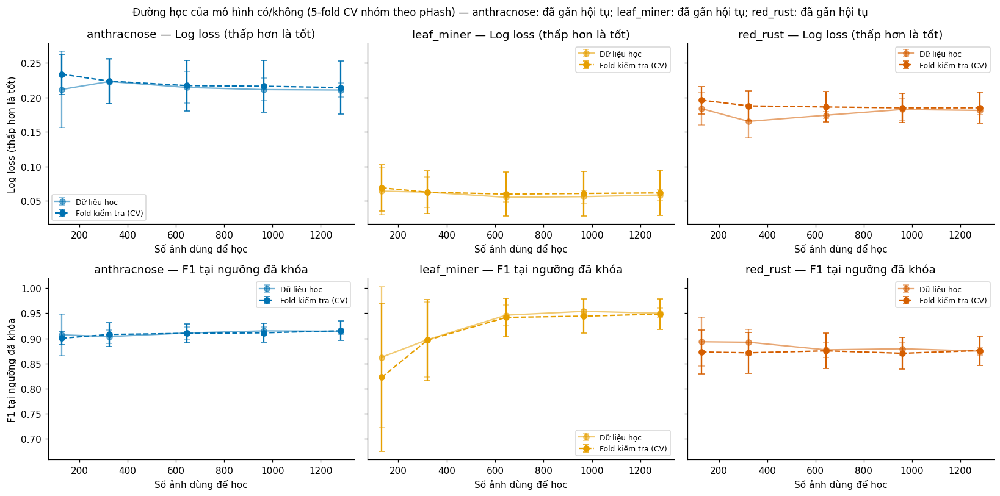

Convergence: {
 "anthracnose": {
  "last_step_val_log_loss_change": 0.001852596407502377,
  "train_val_gap": 0.0035753704486407856,
  "converged": true
 },
 "leaf_miner": {
  "last_step_val_log_loss_change": 0.0007920544017980258,
  "train_val_gap": 0.003042058182550947,
  "converged": true
 },
 "red_rust": {
  "last_step_val_log_loss_change": 9.207171238029277e-05,
  "train_val_gap": 0.003841664169437653,
  "converged": true
 }
}
frozen_config_036.json SHA256 0bcacc838d56b2c97b44733dedfe218cac3fc26e426901a2e1e17b45933f4ce9
presence_models.joblib SHA256 792b27b090a8a8ef089e7264828d963d2b1356a73b7ab9a2dcceabeaaba09043
validation_selection_lock.json SHA256 be4e0486e6fe029f3cd5c60b7c629a789ac8fea051c3d0eb20d2e88b80707d60


In [8]:
# Presence models: grouped CV for C, OOF thresholds, learning curves, then the selection lock.
def presence_estimator(C):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000))

def select_threshold(scores, y):
    """Highest-precision threshold with recall >= RECALL_TARGET (ties -> higher threshold)."""
    scores, y = np.asarray(scores, float), np.asarray(y, int)
    best = None
    for t in np.unique(scores):
        pred = scores >= t
        tp = int((pred & (y == 1)).sum())
        recall = tp / max(1, int(y.sum()))
        if recall < RECALL_TARGET:
            continue
        precision = tp / max(1, int(pred.sum()))
        if best is None or (precision, t) >= (best[1], best[0]):
            best = (float(t), precision, recall)
    if best is None:
        raise RuntimeError("No threshold reaches the recall target")
    return best

def binary_f1(y, pred):
    tp = int((pred & (y == 1)).sum()); fp = int((pred & (y == 0)).sum()); fn = int((~pred & (y == 1)).sum())
    return 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 1.0

groups = POOL.cv_group.to_numpy()
assert len(np.unique(groups)) >= N_FOLDS, "Too few independent pHash groups for grouped CV"
FOLDS = list(GroupKFold(N_FOLDS).split(POOL, groups=groups))
for train, val in FOLDS:
    assert not set(groups[train]) & set(groups[val])
cv_rows, OOF, CHOSEN_C, PRESENCE_MODELS = [], {}, {}, {}
PRESENCE_THRESHOLDS, MAX_CONF_THRESHOLDS, THRESHOLD_ROWS = {}, {}, []
for c in DISEASES:
    X, y = POOL[x_columns(c)].to_numpy(float), POOL[f"gt_{c}"].to_numpy(int)
    assert y.sum() >= N_FOLDS and (1 - y).sum() >= N_FOLDS, f"{c}: too few positives/negatives"
    scores = []
    for C in C_GRID:
        losses = []
        for train, val in FOLDS:
            model = presence_estimator(C).fit(X[train], y[train])
            losses.append(log_loss(y[val], model.predict_proba(X[val])[:, 1], labels=[0, 1]))
        cv_rows.append({"disease": c, "C": C, "cv_log_loss": float(np.mean(losses)), "cv_log_loss_sd": float(np.std(losses, ddof=1))})
        scores.append((float(np.mean(losses)), C))
    CHOSEN_C[c] = min(scores)[1]
    oof = np.zeros(len(y))
    for train, val in FOLDS:
        oof[val] = presence_estimator(CHOSEN_C[c]).fit(X[train], y[train]).predict_proba(X[val])[:, 1]
    OOF[c] = oof
    PRESENCE_MODELS[c] = presence_estimator(CHOSEN_C[c]).fit(X, y)
    t, p, r = select_threshold(oof, y)
    PRESENCE_THRESHOLDS[c] = t
    mt, mp, mr = select_threshold(POOL[f"{c}__max_conf"].to_numpy(float), y)
    MAX_CONF_THRESHOLDS[c] = mt
    THRESHOLD_ROWS += [{"disease": c, "rule": "presence_model", "threshold": t, "val_oof_precision": p, "val_oof_recall": r, "C": CHOSEN_C[c]},
                       {"disease": c, "rule": "max_conf_rule", "threshold": mt, "val_precision": mp, "val_recall": mr}]
pd.DataFrame(cv_rows).to_csv(AGGREGATE / "presence_cv_C.csv", index=False)
THRESHOLD_TABLE = pd.DataFrame(THRESHOLD_ROWS)
THRESHOLD_TABLE.to_csv(AGGREGATE / "validation_thresholds.csv", index=False)
display(THRESHOLD_TABLE)

oof_out = POOL[["evidence_key", "source", "cv_group"] + [f"gt_{c}" for c in DISEASES]].copy()
for c in DISEASES:
    oof_out[f"oof_prob_{c}"] = OOF[c]
oof_out.to_csv(AGGREGATE / "validation_oof_presence_probabilities.csv", index=False)

# Learning curves: train vs held-out log loss and F1 against the number of training images.
lc_rows = []
rng = np.random.default_rng(BOOTSTRAP_SEED)
for c in DISEASES:
    X, y = POOL[x_columns(c)].to_numpy(float), POOL[f"gt_{c}"].to_numpy(int)
    for fold, (train, val) in enumerate(FOLDS):
        train_groups = np.unique(groups[train])
        order = rng.permutation(train_groups)
        for fraction in LEARNING_CURVE_FRACTIONS:
            keep = set(order[:max(1, int(round(fraction * len(order))))])
            sub = train[np.isin(groups[train], list(keep))]
            if y[sub].min() == y[sub].max():
                continue
            model = presence_estimator(CHOSEN_C[c]).fit(X[sub], y[sub])
            for part, idx in (("train", sub), ("validation", val)):
                prob = model.predict_proba(X[idx])[:, 1]
                lc_rows.append({"disease": c, "fold": fold, "fraction": fraction, "train_images": len(sub),
                                "part": part, "log_loss": log_loss(y[idx], prob, labels=[0, 1]),
                                "f1": binary_f1(y[idx], prob >= PRESENCE_THRESHOLDS[c])})
LEARNING = pd.DataFrame(lc_rows)
LEARNING_SUMMARY = (LEARNING.groupby(["disease", "fraction", "part"])
                    .agg(train_images=("train_images", "mean"), log_loss=("log_loss", "mean"),
                         log_loss_sd=("log_loss", "std"), f1=("f1", "mean"), f1_sd=("f1", "std")).reset_index())
convergence = {}
for c in DISEASES:
    v = LEARNING_SUMMARY[(LEARNING_SUMMARY.disease == c) & (LEARNING_SUMMARY.part == "validation")].sort_values("fraction")
    t = LEARNING_SUMMARY[(LEARNING_SUMMARY.disease == c) & (LEARNING_SUMMARY.part == "train")].sort_values("fraction")
    step = abs(v.log_loss.iloc[-1] - v.log_loss.iloc[-2]) if len(v) >= 2 else float("nan")
    gap = float(v.log_loss.iloc[-1] - t.log_loss.iloc[-1])
    convergence[c] = {"last_step_val_log_loss_change": float(step), "train_val_gap": gap,
                      "converged": bool(step < 0.01 and abs(gap) < 0.05)}
fig, axes = plt.subplots(2, len(DISEASES), figsize=(5 * len(DISEASES), 7.5), sharey="row")
for j, c in enumerate(DISEASES):
    for i, (metric, title) in enumerate((("log_loss", "Log loss (thấp hơn là tốt)"), ("f1", "F1 tại ngưỡng đã khóa"))):
        ax = axes[i, j]
        for part, style, name in (("train", "-", "Dữ liệu học"), ("validation", "--", "Fold kiểm tra (CV)")):
            d = LEARNING_SUMMARY[(LEARNING_SUMMARY.disease == c) & (LEARNING_SUMMARY.part == part)].sort_values("train_images")
            ax.errorbar(d.train_images, d[metric], yerr=d[f"{metric}_sd"].fillna(0), fmt="o" + style, capsize=3,
                        color=DISEASE_COLORS[c], alpha=1 if part == "validation" else .55, label=name)
        ax.set_title(f"{c} — {title}")
        ax.set_xlabel("Số ảnh dùng để học")
        if j == 0:
            ax.set_ylabel(title)
        ax.legend(fontsize=8)
verdict = "; ".join(f"{c}: {'đã gần hội tụ' if v['converged'] else 'chưa hội tụ'}" for c, v in convergence.items())
fig.suptitle("Đường học của mô hình có/không (5-fold CV nhóm theo pHash) — " + verdict, fontsize=11)
save_figure(fig, "learning_curves_presence.png", LEARNING_SUMMARY)
print("Convergence:", json.dumps(convergence, indent=1))

# Freeze everything on disk BEFORE YOLO test is read.
FROZEN_CONFIG_036 = {
    "experiment_id": EXPERIMENT_ID, "version": PRESENCE_VERSION, "diseases": DISEASES,
    "presence_features": list(PRESENCE_FEATURES), "presence_detect": PRESENCE_DETECT,
    "classwise_nms_iou": PRESENCE_NMS_IOU, "display_conf": DISPLAY_CONF, "gate_top_boxes": GATE_TOP_BOXES,
    "C": CHOSEN_C, "presence_thresholds": PRESENCE_THRESHOLDS, "max_conf_thresholds": MAX_CONF_THRESHOLDS,
    "rule_definitions": EXPERIMENT_CONFIG["rules"], "recall_target": RECALL_TARGET,
    "gate_negative_labels": list(NEGATIVE_LABELS), "selection_split": EXPERIMENT_CONFIG["selection"]["pool"],
    "fit_pool": POOL.source.value_counts().to_dict(), "yolo_test_used_for_selection": False,
    "holdout_used_for_selection": False, "detector_best_pt_sha256": DETECTOR_WEIGHTS_SHA256,
    "dry_run": DRY_RUN}
FROZEN_PATH = AGGREGATE / "frozen_config_036.json"
MODELS_PATH = AGGREGATE / "presence_models.joblib"
write_json(FROZEN_PATH, FROZEN_CONFIG_036)
joblib.dump(PRESENCE_MODELS, MODELS_PATH)
FROZEN_SHA256, MODELS_SHA256 = file_sha256(FROZEN_PATH), file_sha256(MODELS_PATH)
LOCK = {"experiment_id": EXPERIMENT_ID, "status": "SELECTION_LOCKED", "locked_unix": time.time(),
        "selection_split": "YOLO val + clean DenseNet-Validation negatives (grouped OOF)",
        "selected_thresholds": {"presence_model": PRESENCE_THRESHOLDS, "max_conf_rule": MAX_CONF_THRESHOLDS,
                                "any_box": {"min_boxes": 1, "box_conf": 0.25}, "three_boxes": {"min_boxes": 3, "box_conf": 0.25}},
        "selected_C": CHOSEN_C, "proposed_rule": PROPOSED_RULE, "pass_criteria": PASS_CRITERIA,
        "frozen_config_036_sha256": FROZEN_SHA256, "presence_models_sha256": MODELS_SHA256,
        "yolo_test_read_before_lock": False, "holdout_read_before_lock": False,
        "exp035_models_sha256": {str(k): v for k, v in EXP035_MODEL_SHA256.items()}}
write_json(OUT_DIR / "validation_selection_lock.json", LOCK)
LOCK_SHA256 = file_sha256(OUT_DIR / "validation_selection_lock.json")
print("frozen_config_036.json SHA256", FROZEN_SHA256)
print("presence_models.joblib SHA256", MODELS_SHA256)
print("validation_selection_lock.json SHA256", LOCK_SHA256)

## 7. Chạy trên YOLO Test, ảnh âm DenseNet Test và Holdout (sau khi khóa)

Cổng DenseNet: nếu mô hình kết hợp EXP-035 dự đoán `healthy` hoặc `not_cashew_leaf` thì danh sách bệnh rỗng. Cổng được tính cho ensemble 5 seed (đường triển khai) và cho từng seed.

In [9]:
# After the lock: detector + DenseNet gate on YOLO test, DenseNet-Test negatives and Holdout.
assert file_sha256(FROZEN_PATH) == FROZEN_SHA256 and file_sha256(MODELS_PATH) == MODELS_SHA256
assert file_sha256(OUT_DIR / "validation_selection_lock.json") == LOCK_SHA256
import tensorflow as tf
from tensorflow import keras
_spec = importlib.util.spec_from_file_location("cashew_pipeline_exp035", EXP035_BUNDLE / "cashew_pipeline.py")
EXP035_MODULE = importlib.util.module_from_spec(_spec)
sys.modules[_spec.name] = EXP035_MODULE
_spec.loader.exec_module(EXP035_MODULE)  # registers the EXP-035 custom Keras layer

def dense_probs_one(model, path):
    image = tf.io.decode_image(tf.io.read_file(str(path)), channels=3, expand_animations=False)
    resized = tf.image.resize(tf.cast(image, tf.float32), (256, 256)).numpy()[None, ...]
    return model.predict(resized, verbose=0)[0]

for key_frame, label in ((YOLO_INVENTORY["test"], "yolo_test"), (DN_NEG["test"], "dn_test_neg"),
                         (INVENTORY["holdout"], "holdout")):
    run_detector(key_frame, label)

# DenseNet probabilities per seed. YOLO-test images were never scored by EXP-035, so run the 5 models;
# DenseNet-Test negatives and Holdout reuse the saved EXP-035 per-seed files.
yolo_test = YOLO_INVENTORY["test"]
DENSE = {}
for seed in SEEDS:
    model = keras.models.load_model(EXP035_BUNDLE / f"seed_{seed}" / "deployment_model.keras")
    probs = np.asarray([dense_probs_one(model, p) for p in yolo_test.path])
    del model
    keras.backend.clear_session(); gc.collect()
    frame = pd.DataFrame({"evidence_key": yolo_test.evidence_key.to_numpy()})
    for i, c in enumerate(CLASSES):
        frame[f"prob_{c}"] = probs[:, i]
    saved_test = seed_probabilities(seed, "test")
    saved_hold = seed_probabilities(seed, "holdout")
    DENSE[seed] = pd.concat([frame, saved_test[saved_test.evidence_key.isin(DN_NEG["test"].evidence_key)][["evidence_key"] + PROB_COLUMNS],
                             saved_hold[["evidence_key"] + PROB_COLUMNS]], ignore_index=True).set_index("evidence_key")
    v2 = pd.DataFrame({"experiment_id": EXPERIMENT_ID, "architecture": "DenseNet121 (EXP-035 checkpoint)",
                       "training_mode": "ImageNet_Transfer (EVAL_ONLY)", "dataset_version": "CASHEW_YOLO_MASTER_FINAL_NEG_V04",
                       "dataset_sha256": YOLO_V04_DATASET_SHA256, "dataset_manifest_sha256": None, "split": "yolo_test",
                       "seed": seed, "image_id": frame.evidence_key, "relative_path": [Path(p).relative_to(YOLO_ROOT).as_posix() for p in yolo_test.path],
                       "true_label": None, "predicted_label": [CLASSES[i] for i in probs.argmax(1)],
                       "true_class_idx": None, "predicted_class_idx": probs.argmax(1), "correct": None,
                       "confidence": probs.max(1), **{f"prob_{c}": probs[:, i] for i, c in enumerate(CLASSES)}})
    (OUT_DIR / f"seed_{seed}").mkdir(parents=True, exist_ok=True)
    v2.to_csv(OUT_DIR / f"seed_{seed}" / "yolo_test_predictions.csv", index=False)
DENSE["ensemble"] = pd.DataFrame({c: np.mean([DENSE[s][c].to_numpy() for s in SEEDS], axis=0) for c in PROB_COLUMNS},
                                 index=DENSE[SEEDS[0]].index)

# Evaluation table: one row per scored image.
gt_test = GT[GT.yolo_split == "test"].set_index("evidence_key")
rows = []
for key in yolo_test.evidence_key:
    g = gt_test.loc[key]
    rows.append({"evidence_key": key, "eval_set": "yolo_test", "true_label": None,
                 "negative_group": g.negative_group if g.gt_set_size == 0 else None,
                 "field_real": bool(g.field_real), "overlap": key in OVERLAP["yolo_test"],
                 **{f"gt_{c}": int(g[f"gt_{c}"]) for c in DISEASES},
                 **{f"gt_strict_{c}": int(g[f"gt_strict_{c}"]) for c in DISEASES},
                 **{f"gt_coverage_{c}": float(g[f"gt_coverage_{c}"]) for c in DISEASES}})
for item in DN_NEG["test"].itertuples():
    rows.append({"evidence_key": item.evidence_key, "eval_set": "dn_test_neg", "true_label": item.true_label,
                 "negative_group": item.true_label, "field_real": Path(item.path).name.startswith("real_"),
                 "overlap": item.evidence_key in OVERLAP["dn_test_neg"],
                 **{f"gt_{c}": 0 for c in DISEASES}, **{f"gt_strict_{c}": 0 for c in DISEASES},
                 **{f"gt_coverage_{c}": 0.0 for c in DISEASES}})
for item in INVENTORY["holdout"].itertuples():
    rows.append({"evidence_key": item.evidence_key, "eval_set": "holdout", "true_label": item.true_label,
                 "negative_group": None, "field_real": True, "overlap": None,
                 **{f"gt_{c}": None for c in DISEASES}, **{f"gt_strict_{c}": None for c in DISEASES},
                 **{f"gt_coverage_{c}": None for c in DISEASES}})
EVAL = pd.DataFrame(rows)
unique_keys(EVAL, "evaluation table")
EVAL = checked_join(EVAL, feature_table(EVAL), "evaluation features")
EVAL.loc[(EVAL.eval_set == "yolo_test") & (EVAL.negative_group == "not_cashew_leaf"), "negative_group"] = "not_cashew_leaf_yolo"
PROBS = np.column_stack([PRESENCE_MODELS[c].predict_proba(EVAL[x_columns(c)].to_numpy(float))[:, 1] for c in DISEASES])
for j, c in enumerate(DISEASES):
    EVAL[f"present_prob_{c}"] = PROBS[:, j]

GATES = ["none", "ensemble"] + [f"seed_{s}" for s in SEEDS]
GATE_LABELS = {}
for gate in GATES[1:]:
    source = DENSE["ensemble" if gate == "ensemble" else int(gate.split("_")[1])]
    labels = []
    for key in EVAL.evidence_key:
        raw, h, w = RAW[key]
        labels.append(gate_label(STACKER_035, CONFIG_035, source.loc[key, PROB_COLUMNS].to_numpy(float),
                                 gate_evidence(raw, h, w))[0])
    GATE_LABELS[gate] = np.array(labels)
    EVAL[f"gate_label_{gate}"] = labels

# Gate with freshly computed evidence versus the saved EXP-035 labels (Holdout and DenseNet-Test negatives).
gate_check = EVAL[["evidence_key", "eval_set"]].assign(gate_ensemble=GATE_LABELS["ensemble"])
saved_labels = pd.concat([EXP035_SAVED["holdout"], EXP035_SAVED["test"]])[["evidence_key", "predicted_label"]]
gate_check = gate_check.merge(saved_labels, on="evidence_key", how="inner", validate="one_to_one")
gate_check["same_as_exp035"] = gate_check.gate_ensemble == gate_check.predicted_label
gate_check.to_csv(AGGREGATE / "gate_vs_exp035_saved_labels.csv", index=False)
print("Ensemble gate equals saved EXP-035 label on", int(gate_check.same_as_exp035.sum()), "/", len(gate_check),
      "Holdout + DenseNet-Test-negative images" + ("" if gate_check.same_as_exp035.all() else
      " (WARNING: differences come from re-running the detector; see gate_vs_exp035_saved_labels.csv)"))

def ungated_predictions(frame, probs):
    out = {}
    out["any_box"] = np.column_stack([frame[f"{c}__n_ge_0.25"] >= 1 for c in DISEASES])
    out["three_boxes"] = np.column_stack([frame[f"{c}__n_ge_0.25"] >= 3 for c in DISEASES])
    out["max_conf_rule"] = np.column_stack([frame[f"{c}__max_conf"] >= MAX_CONF_THRESHOLDS[c] for c in DISEASES])
    out["presence_model"] = np.column_stack([probs[:, j] >= PRESENCE_THRESHOLDS[c] for j, c in enumerate(DISEASES)])
    return {k: np.asarray(v, dtype=bool) for k, v in out.items()}

BASE_PRED = ungated_predictions(EVAL, PROBS)
PRED = {}
for gate in GATES:
    keep = np.ones(len(EVAL), bool) if gate == "none" else ~np.isin(GATE_LABELS[gate], NEGATIVE_LABELS)
    for rule in RULES:
        PRED[(gate, rule)] = BASE_PRED[rule] & keep[:, None]

def set_name(row_bool):
    names = [SHORT[c] for c, v in zip(DISEASES, row_bool) if v]
    return "+".join(names) if names else "∅"

long_rows = []
truth = EVAL[[f"gt_{c}" for c in DISEASES]]
for gate in GATES:
    for rule in RULES:
        pred = PRED[(gate, rule)]
        for i, key in enumerate(EVAL.evidence_key):
            long_rows.append({"experiment_id": EXPERIMENT_ID, "split": EVAL.eval_set.iat[i], "gate": gate,
                              "seed": int(gate.split("_")[1]) if gate.startswith("seed_") else None, "rule": rule,
                              "image_id": key, "true_label": EVAL.true_label.iat[i],
                              "true_set": None if EVAL.eval_set.iat[i] == "holdout" else set_name(truth.iloc[i].to_numpy(int) == 1),
                              "predicted_set": set_name(pred[i]), "n_predicted": int(pred[i].sum()),
                              **{f"present_prob_{c}": PROBS[i, j] for j, c in enumerate(DISEASES)}})
PRESENCE_PREDICTIONS = pd.DataFrame(long_rows)
PRESENCE_PREDICTIONS.to_csv(AGGREGATE / "presence_predictions.csv", index=False)
EVAL.drop(columns=[c for c in EVAL.columns if "__x__" in c]).to_csv(AGGREGATE / "evaluation_table.csv", index=False)

# Batch web results (ensemble gate), used by the analyze() consistency gate.
BATCH_RESULT = {}
for key in yolo_test.evidence_key:
    raw, h, w = RAW[key]
    BATCH_RESULT[key] = presence_result(DENSE["ensemble"].loc[key, PROB_COLUMNS].to_numpy(float), raw, h, w,
                                        STACKER_035, CONFIG_035, PRESENCE_MODELS, FROZEN_CONFIG_036)
    j = EVAL.index[EVAL.evidence_key == key][0]
    assert [d["name"] for d in BATCH_RESULT[key]["diseases"]] == [c for c, v in zip(DISEASES, PRED[("ensemble", PROPOSED_RULE)][j]) if v]
print("Scored:", EVAL.eval_set.value_counts().to_dict(), "| gates", GATES)

yolo_test 488 images 41854 raw boxes (conf >= 0.05)
dn_test_neg 274 images 980 raw boxes (conf >= 0.05)
holdout 126 images 4818 raw boxes (conf >= 0.05)
Ensemble gate equals saved EXP-035 label on 400 / 400 Holdout + DenseNet-Test-negative images
Scored: {'yolo_test': 488, 'dn_test_neg': 274, 'holdout': 126} | gates ['none', 'ensemble', 'seed_42', 'seed_123', 'seed_2026', 'seed_3407', 'seed_7777']


## 8. Kết quả: 4 quy tắc trên cùng dữ liệu

`any_box` (≥ 1 box conf ≥ 0.25), `three_boxes` (≥ 3 box), `max_conf_rule` (độ tin cậy cao nhất ≥ ngưỡng Validation, quy tắc dễ hỏng khi lá có hai bệnh) và `presence_model` (đề xuất). Mỗi kết quả đều được báo cáo khi không cổng và khi có cổng DenseNet.

/tmp/ipykernel_1218/2615658170.py:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  "without_overlap": TEST_MASK & ~EVAL.overlap.fillna(False).astype(bool).to_numpy(),


,gate,rule,subset,images,exact_set_match,hamming_loss,micro_f1,macro_f1,samples_f1
0,none,any_box,all,488,0.795082,0.071721,0.920515,0.930186,0.903279
4,none,three_boxes,all,488,0.592213,0.164617,0.779102,0.721059,0.738661
8,none,max_conf_rule,all,488,0.772541,0.077869,0.913110,0.916643,0.893989
12,none,presence_model,all,488,0.766393,0.079235,0.912121,0.916418,0.887295
16,ensemble,any_box,all,488,0.838115,0.056694,0.936006,0.940871,0.946311
20,ensemble,three_boxes,all,488,0.622951,0.154372,0.789572,0.728118,0.769399
24,ensemble,max_conf_rule,all,488,0.815574,0.063525,0.927851,0.928515,0.937022
28,ensemble,presence_model,all,488,0.813525,0.063525,0.928185,0.929117,0.934426


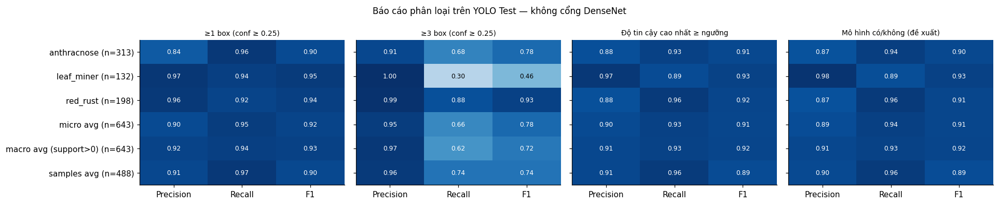

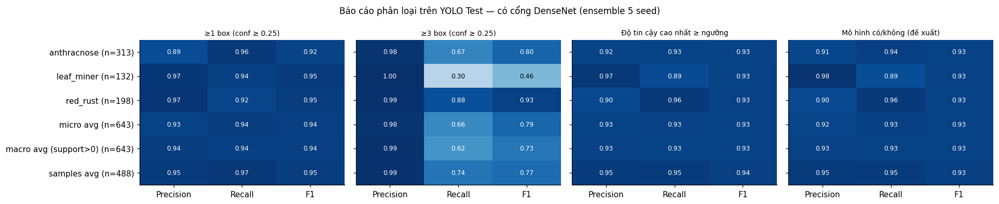

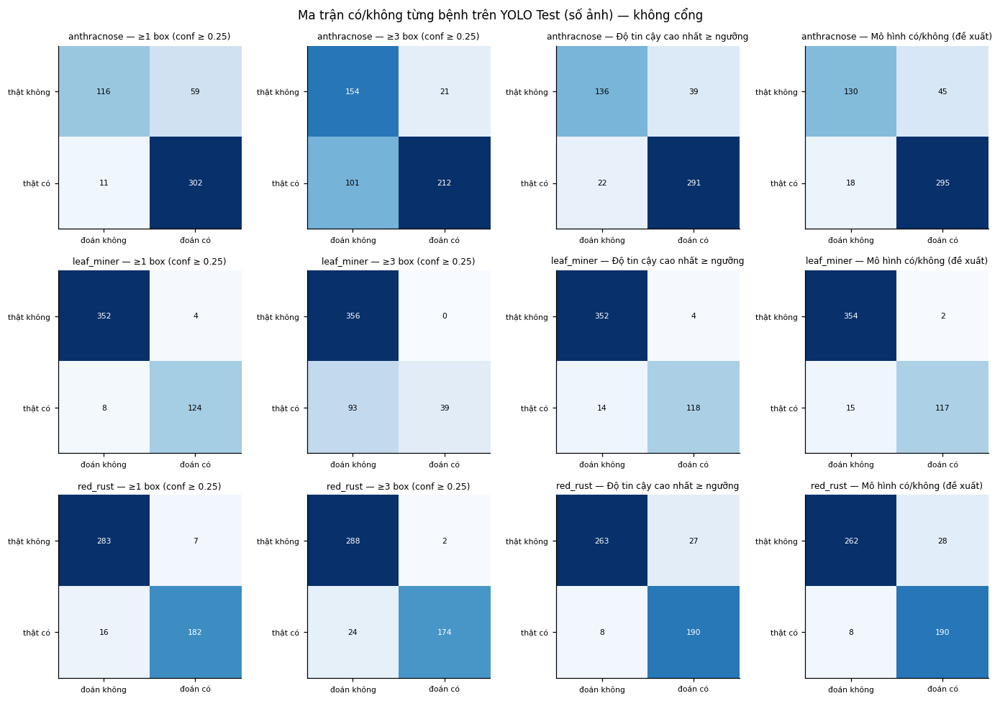

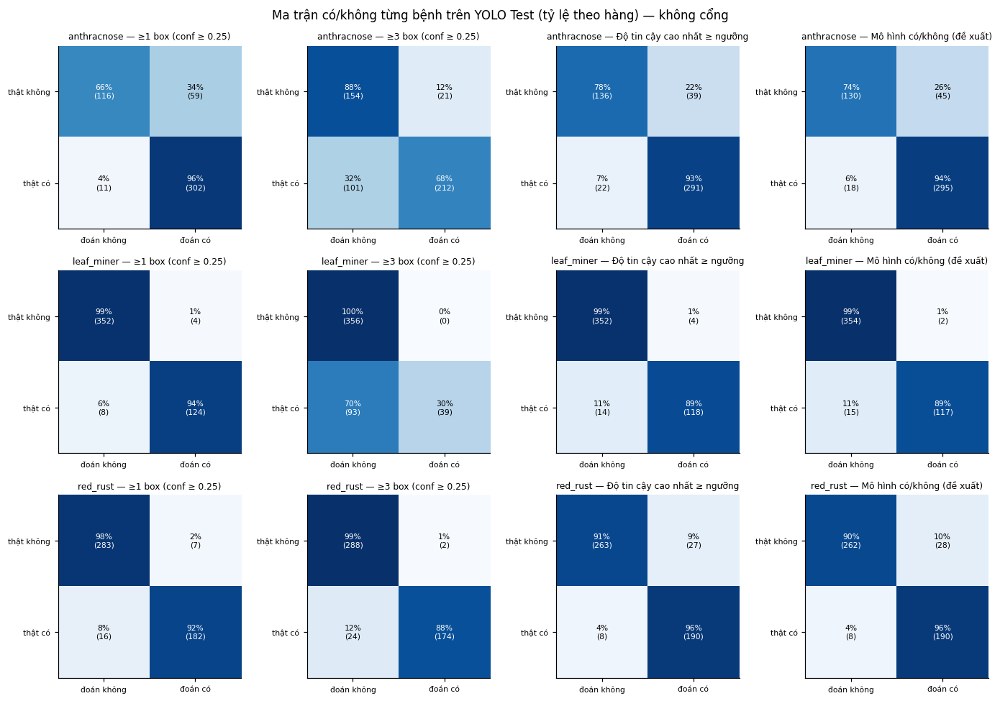

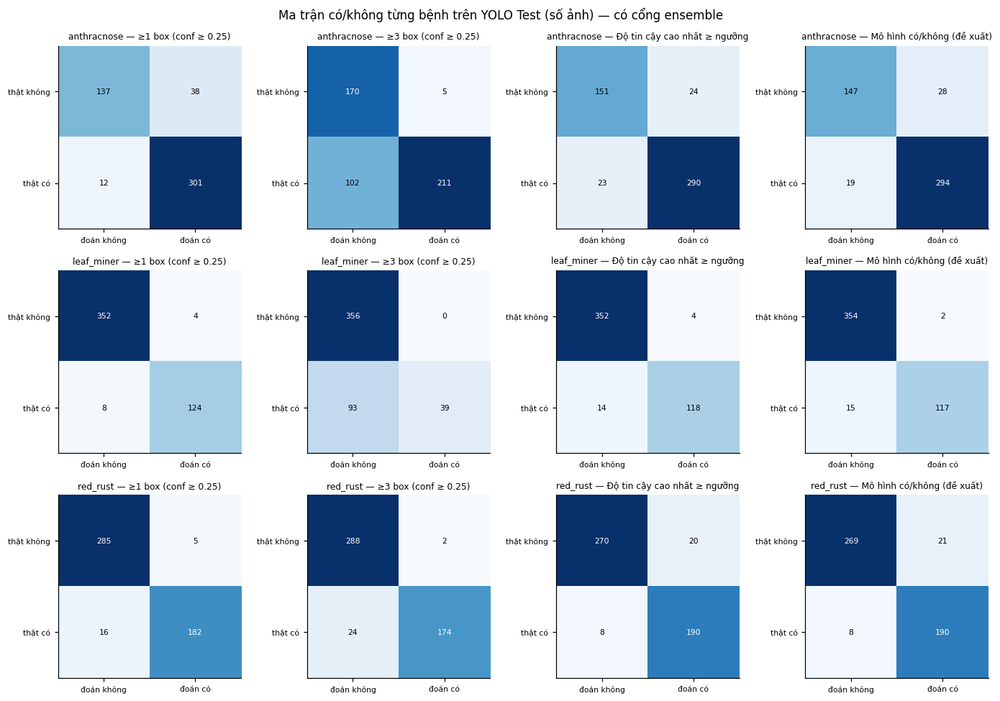

...

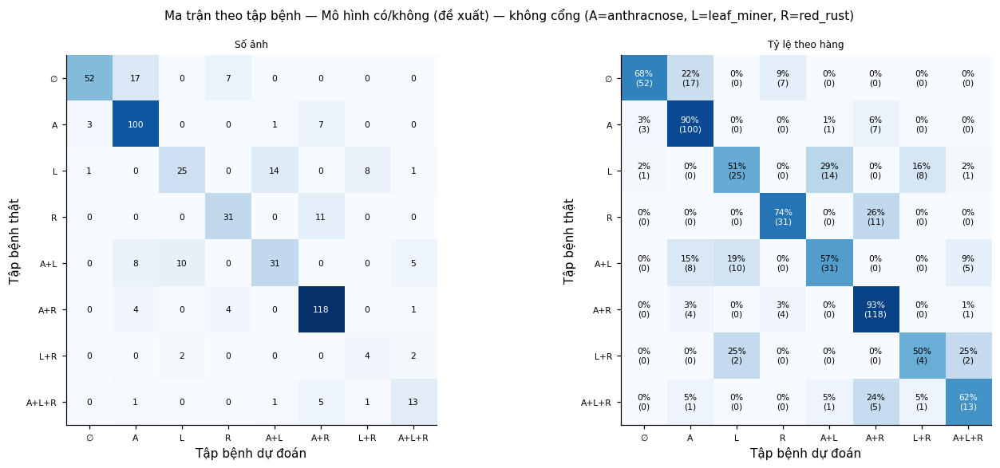

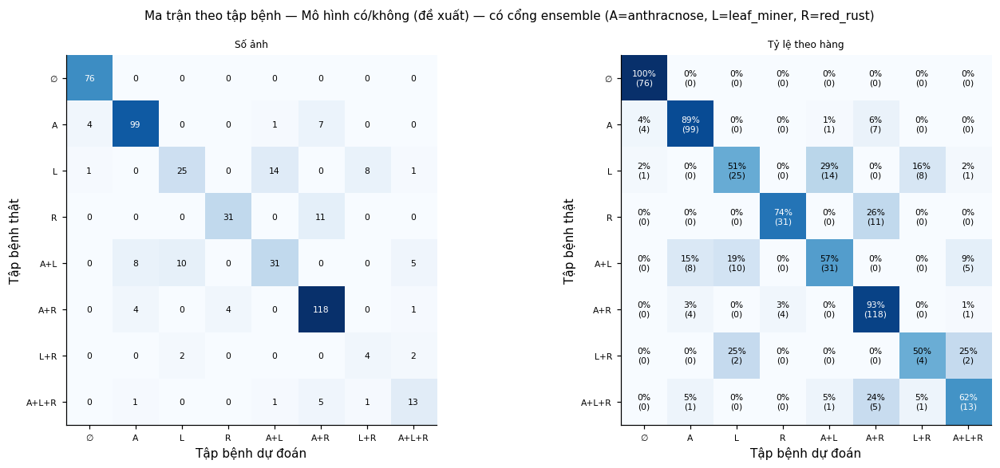

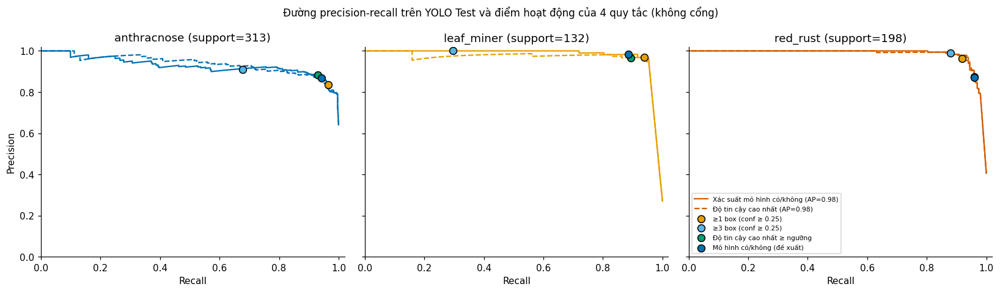

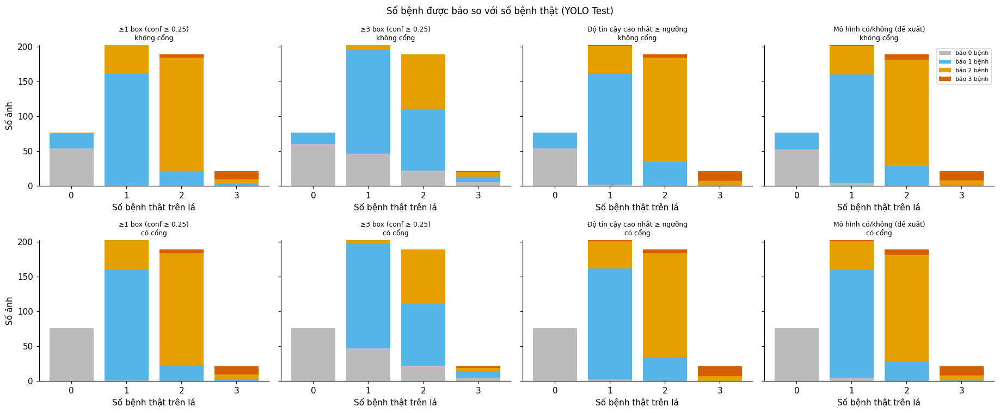

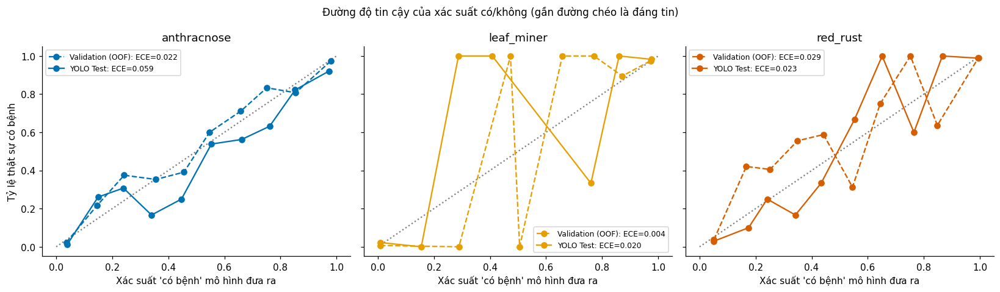

/tmp/ipykernel_1218/2615658170.py:213: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ("without_overlap", ~EVAL.overlap.fillna(False).astype(bool).to_numpy())):
/tmp/ipykernel_1218/2615658170.py:213: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ("without_overlap", ~EVAL.overlap.fillna(False).astype(bool).to_numpy())):
/tmp/ipykernel_1218/2615658170.py:213: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behav

,gate,rule,group,variant,images,false_alarms,false_alarm_rate,wilson_low,wilson_high,sources
0,none,any_box,healthy,all,118,11,0.093220,0.052852,0.159239,dn_test_neg
2,none,any_box,non_cashew_diseased_leaf,all,76,22,0.289474,0.199610,0.399596,yolo_test
4,none,any_box,not_cashew_leaf,all,156,33,0.211538,0.154780,0.282162,dn_test_neg
6,none,three_boxes,healthy,all,118,1,0.008475,0.001498,0.046446,dn_test_neg
8,none,three_boxes,non_cashew_diseased_leaf,all,76,16,0.210526,0.133951,0.314956,yolo_test
10,none,three_boxes,not_cashew_leaf,all,156,25,0.160256,0.110968,0.225875,dn_test_neg
12,none,max_conf_rule,healthy,all,118,8,0.067797,0.034751,0.128095,dn_test_neg
14,none,max_conf_rule,non_cashew_diseased_leaf,all,76,22,0.289474,0.199610,0.399596,yolo_test
16,none,max_conf_rule,not_cashew_leaf,all,156,36,0.230769,0.171604,0.302876,dn_test_neg
18,none,presence_model,healthy,all,118,10,0.084746,0.046683,0.148993,dn_test_neg


In [10]:
# Results on YOLO test: without gate and with the ensemble DenseNet gate. Same data for every rule.
TEST_MASK = (EVAL.eval_set == "yolo_test").to_numpy()
Y_ALL = EVAL[[f"gt_{c}" for c in DISEASES]].to_numpy(dtype=float)

def multilabel_report(Y, P):
    Y, P = np.asarray(Y, int), np.asarray(P, int)
    p, r, f, s = precision_recall_fscore_support(Y, P, labels=[0, 1, 2], average=None, zero_division=0)
    rows = [{"row": c, "precision": p[j], "recall": r[j], "f1": f[j], "support": int(s[j])} for j, c in enumerate(DISEASES)]
    mp, mr, mf, _ = precision_recall_fscore_support(Y, P, labels=[0, 1, 2], average="micro", zero_division=0)
    active = s > 0
    rows.append({"row": "micro avg", "precision": mp, "recall": mr, "f1": mf, "support": int(s.sum())})
    rows.append({"row": "macro avg (support>0)", "precision": p[active].mean(), "recall": r[active].mean(),
                 "f1": f[active].mean(), "support": int(s.sum())})
    sp, sr, sf, _ = precision_recall_fscore_support(Y, P, labels=[0, 1, 2], average="samples", zero_division=1)
    rows.append({"row": "samples avg", "precision": sp, "recall": sr, "f1": sf, "support": len(Y)})
    return pd.DataFrame(rows)

def set_metrics(Y, P):
    Y, P = np.asarray(Y, int), np.asarray(P, int)
    return {"images": len(Y), "exact_set_match": float((Y == P).all(1).mean()), "hamming_loss": float((Y != P).mean())}

SUBSETS = {"all": TEST_MASK,
           "without_overlap": TEST_MASK & ~EVAL.overlap.fillna(False).astype(bool).to_numpy(),
           "field_real": TEST_MASK & EVAL.field_real.astype(bool).to_numpy(),
           "positives_only": TEST_MASK & (Y_ALL.sum(1) > 0)}
REPORTS, SUMMARY_ROWS = [], []
for gate in ("none", "ensemble"):
    for rule in RULES:
        P = PRED[(gate, rule)]
        for subset, mask in SUBSETS.items():
            if not mask.any():
                continue
            rep = multilabel_report(Y_ALL[mask], P[mask]).assign(gate=gate, rule=rule, subset=subset, images=int(mask.sum()))
            REPORTS.append(rep)
            SUMMARY_ROWS.append({"gate": gate, "rule": rule, "subset": subset, **set_metrics(Y_ALL[mask], P[mask]),
                                 "micro_f1": rep.loc[rep.row == "micro avg", "f1"].iat[0],
                                 "macro_f1": rep.loc[rep.row == "macro avg (support>0)", "f1"].iat[0],
                                 "samples_f1": rep.loc[rep.row == "samples avg", "f1"].iat[0]})
CLASSIFICATION_REPORT = pd.concat(REPORTS, ignore_index=True)
CLASSIFICATION_REPORT.to_csv(AGGREGATE / "classification_report_by_rule.csv", index=False)
SET_SUMMARY = pd.DataFrame(SUMMARY_ROWS)
SET_SUMMARY.to_csv(AGGREGATE / "set_metrics_by_rule.csv", index=False)
display(SET_SUMMARY[SET_SUMMARY.subset == "all"])
FIELD_TABLE = SET_SUMMARY[SET_SUMMARY.subset == "field_real"].copy()
FIELD_TABLE.to_csv(AGGREGATE / "field_subset_real_table.csv", index=False)

# (3) Classification-report heatmaps, one panel per rule, same colour scale.
for gate in ("none", "ensemble"):
    fig, axes = plt.subplots(1, len(RULES), figsize=(4.4 * len(RULES), 3.6), sharey=True)
    plotted = []
    for ax, rule in zip(axes, RULES):
        rep = CLASSIFICATION_REPORT[(CLASSIFICATION_REPORT.gate == gate) & (CLASSIFICATION_REPORT.rule == rule) &
                                    (CLASSIFICATION_REPORT.subset == "all")]
        rep = rep[(rep.support > 0)]
        values = rep[["precision", "recall", "f1"]].to_numpy(float)
        ax.imshow(values, vmin=0, vmax=1, cmap="Blues", aspect="auto")
        for i in range(values.shape[0]):
            for j in range(3):
                ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                        color="white" if values[i, j] > .6 else "black")
        ax.set_xticks(range(3), ["Precision", "Recall", "F1"])
        ax.set_yticks(range(len(rep)), [f"{r} (n={s})" for r, s in zip(rep.row, rep.support)])
        ax.set_title(RULE_LABELS[rule], fontsize=9)
        plotted.append(rep.assign(rule=rule, gate=gate))
    gate_vi = "không cổng DenseNet" if gate == "none" else "có cổng DenseNet (ensemble 5 seed)"
    fig.suptitle(f"Báo cáo phân loại trên YOLO Test — {gate_vi}", fontsize=11)
    save_figure(fig, f"classification_report_heatmap_{gate}.png", pd.concat(plotted))

# (4) Per-disease 2x2 matrices for each rule, plus the set-level matrix for the proposed rule.
def two_by_two(y, p):
    return np.array([[int(((y == 0) & (p == 0)).sum()), int(((y == 0) & (p == 1)).sum())],
                     [int(((y == 1) & (p == 0)).sum()), int(((y == 1) & (p == 1)).sum())]])

SET_ORDER = ["∅", "A", "L", "R", "A+L", "A+R", "L+R", "A+L+R"]

def set_matrix(Y, P):
    t = [set_name(r == 1) for r in np.asarray(Y, int)]
    p = [set_name(r) for r in np.asarray(P, bool)]
    m = pd.crosstab(pd.Series(t, name="true"), pd.Series(p, name="pred")).reindex(index=SET_ORDER, columns=SET_ORDER, fill_value=0)
    supported = [k for k in SET_ORDER if m.loc[k].sum() > 0]
    columns = [k for k in SET_ORDER if k in supported or m[k].sum() > 0]
    return m.loc[supported, columns]  # zero-support rows (and unused columns) are omitted

def draw_counts(ax, matrix, normalized, title, xt, yt):
    raw = np.asarray(matrix, float)
    shown = raw / np.maximum(raw.sum(axis=1, keepdims=True), 1) if normalized else raw
    ax.imshow(shown, cmap="Blues", vmin=0, vmax=1 if normalized else max(1, raw.max()))
    for i in range(raw.shape[0]):
        for j in range(raw.shape[1]):
            text = f"{shown[i, j]:.0%}\n({int(raw[i, j])})" if normalized else f"{int(raw[i, j])}"
            ax.text(j, i, text, ha="center", va="center", fontsize=7,
                    color="white" if shown[i, j] > (.6 if normalized else .6 * max(1, raw.max())) else "black")
    ax.set_xticks(range(len(xt)), xt, fontsize=7)
    ax.set_yticks(range(len(yt)), yt, fontsize=7)
    ax.set_title(title, fontsize=8)

CONFUSION_ROWS = []
for gate in ("none", "ensemble"):
    for normalized in (False, True):
        fig, axes = plt.subplots(len(DISEASES), len(RULES), figsize=(3.2 * len(RULES), 3 * len(DISEASES)))
        for i, c in enumerate(DISEASES):
            for j, rule in enumerate(RULES):
                m = two_by_two(Y_ALL[TEST_MASK, i].astype(int), PRED[(gate, rule)][TEST_MASK, i].astype(int))
                draw_counts(axes[i, j], m, normalized, f"{c} — {RULE_LABELS[rule]}", ["đoán không", "đoán có"],
                            ["thật không", "thật có"])
                if not normalized:
                    CONFUSION_ROWS.append({"gate": gate, "disease": c, "rule": rule, "tn": m[0, 0], "fp": m[0, 1],
                                           "fn": m[1, 0], "tp": m[1, 1]})
        kind = "normalized" if normalized else "raw"
        fig.suptitle(f"Ma trận có/không từng bệnh trên YOLO Test ({'tỷ lệ theo hàng' if normalized else 'số ảnh'}) — "
                     f"{'không cổng' if gate == 'none' else 'có cổng ensemble'}", fontsize=11)
        save_figure(fig, f"confusion_per_disease_{kind}_{gate}.png",
                    pd.DataFrame([r for r in CONFUSION_ROWS if r["gate"] == gate]))
CONFUSION_TABLE = pd.DataFrame(CONFUSION_ROWS)
CONFUSION_TABLE.to_csv(AGGREGATE / "confusion_per_disease.csv", index=False)
for gate in ("none", "ensemble"):
    m = set_matrix(Y_ALL[TEST_MASK], PRED[(gate, PROPOSED_RULE)][TEST_MASK])
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
    for ax, normalized in zip(axes, (False, True)):
        draw_counts(ax, m.to_numpy(), normalized, "Số ảnh" if not normalized else "Tỷ lệ theo hàng",
                    list(m.columns), list(m.index))
        ax.set_xlabel("Tập bệnh dự đoán"); ax.set_ylabel("Tập bệnh thật")
    fig.suptitle(f"Ma trận theo tập bệnh — {RULE_LABELS[PROPOSED_RULE]} — "
                 f"{'không cổng' if gate == 'none' else 'có cổng ensemble'} (A=anthracnose, L=leaf_miner, R=red_rust)", fontsize=10)
    save_figure(fig, f"confusion_set_level_{gate}.png", m.reset_index().melt(id_vars="true", var_name="pred", value_name="images"))

# (5) Precision-recall curve per disease, with the four operating points (no gate).
pr_rows = []
fig, axes = plt.subplots(1, len(DISEASES), figsize=(5 * len(DISEASES), 4.4), sharey=True)
for ax, (j, c) in zip(axes, enumerate(DISEASES)):
    y = Y_ALL[TEST_MASK, j].astype(int)
    for scores, style, name in ((PROBS[TEST_MASK, j], "-", "Xác suất mô hình có/không"),
                                (EVAL.loc[TEST_MASK, f"{c}__max_conf"].to_numpy(float), "--", "Độ tin cậy cao nhất")):
        prec, rec, _ = precision_recall_curve(y, scores)
        ax.plot(rec, prec, style, color=DISEASE_COLORS[c], label=f"{name} (AP={average_precision_score(y, scores):.2f})")
        pr_rows += [{"disease": c, "curve": name, "recall": a, "precision": b} for a, b in zip(rec, prec)]
    for rule in RULES:
        m = two_by_two(y, PRED[("none", rule)][TEST_MASK, j].astype(int))
        rp = m[1, 1] / max(1, m[:, 1].sum()); rr = m[1, 1] / max(1, m[1].sum())
        ax.scatter(rr, rp, s=60, color=RULE_COLORS[rule], edgecolor="black", zorder=5, label=RULE_LABELS[rule])
        pr_rows.append({"disease": c, "curve": "operating_point_" + rule, "recall": rr, "precision": rp})
    ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02)
    ax.set_xlabel("Recall"); ax.set_title(f"{c} (support={int(y.sum())})")
axes[0].set_ylabel("Precision")
axes[-1].legend(fontsize=7, loc="lower left")
fig.suptitle("Đường precision-recall trên YOLO Test và điểm hoạt động của 4 quy tắc (không cổng)", fontsize=11)
save_figure(fig, "precision_recall_operating_points.png", pd.DataFrame(pr_rows))

# (7) Number of diseases reported versus the true number.
count_rows = []
for gate in ("none", "ensemble"):
    for rule in RULES:
        true_n = Y_ALL[TEST_MASK].sum(1).astype(int)
        pred_n = PRED[(gate, rule)][TEST_MASK].sum(1)
        for t in sorted(set(true_n)):
            for p in range(4):
                count_rows.append({"gate": gate, "rule": rule, "true_n": t, "pred_n": p,
                                   "images": int(((true_n == t) & (pred_n == p)).sum())})
COUNT_TABLE = pd.DataFrame(count_rows)
fig, axes = plt.subplots(2, len(RULES), figsize=(4.2 * len(RULES), 7), sharey="row")
palette = ["#BBBBBB", "#56B4E9", "#E69F00", "#D55E00"]
for i, gate in enumerate(("none", "ensemble")):
    for ax, rule in zip(axes[i], RULES):
        d = COUNT_TABLE[(COUNT_TABLE.gate == gate) & (COUNT_TABLE.rule == rule)].pivot(index="true_n", columns="pred_n", values="images")
        bottom = np.zeros(len(d))
        for p in range(4):
            ax.bar(d.index.astype(str), d[p], bottom=bottom, color=palette[p], label=f"báo {p} bệnh")
            bottom += d[p].to_numpy()
        ax.set_title(f"{RULE_LABELS[rule]}\n{'không cổng' if gate == 'none' else 'có cổng'}", fontsize=8)
        ax.set_xlabel("Số bệnh thật trên lá")
    axes[i, 0].set_ylabel("Số ảnh")
axes[0, -1].legend(fontsize=7)
fig.suptitle("Số bệnh được báo so với số bệnh thật (YOLO Test)", fontsize=11)
save_figure(fig, "disease_count_true_vs_reported.png", COUNT_TABLE)

# (8) Reliability of presence probabilities (OOF Validation and YOLO test) + ECE.
def reliability(y, p, bins=10):
    edges = np.linspace(0, 1, bins + 1); rows = []; ece = 0.0
    for k in range(bins):
        sel = (p >= edges[k]) & ((p <= edges[k + 1]) if k == bins - 1 else (p < edges[k + 1]))
        if sel.any():
            rows.append({"bin": k, "mean_prob": float(p[sel].mean()), "observed": float(y[sel].mean()), "n": int(sel.sum())})
            ece += sel.mean() * abs(y[sel].mean() - p[sel].mean())
    return pd.DataFrame(rows), float(ece)

rel_rows, ECE = [], {}
fig, axes = plt.subplots(1, len(DISEASES), figsize=(5 * len(DISEASES), 4.4), sharey=True)
for ax, (j, c) in zip(axes, enumerate(DISEASES)):
    ax.plot([0, 1], [0, 1], ":", color="grey")
    for split, y, p, style in (("validation_oof", POOL[f"gt_{c}"].to_numpy(float), OOF[c], "--"),
                               ("yolo_test", Y_ALL[TEST_MASK, j], PROBS[TEST_MASK, j], "-")):
        table, ece = reliability(y, p)
        ECE[(c, split)] = ece
        ax.plot(table.mean_prob, table.observed, style + "o", color=DISEASE_COLORS[c],
                label=f"{'Validation (OOF)' if split == 'validation_oof' else 'YOLO Test'}: ECE={ece:.3f}")
        rel_rows.append(table.assign(disease=c, split=split, ece=ece))
    ax.set_xlabel("Xác suất 'có bệnh' mô hình đưa ra"); ax.set_title(c); ax.legend(fontsize=8)
axes[0].set_ylabel("Tỷ lệ thật sự có bệnh")
fig.suptitle("Đường độ tin cậy của xác suất có/không (gần đường chéo là đáng tin)", fontsize=11)
save_figure(fig, "reliability_presence.png", pd.concat(rel_rows))

# Negative groups: false-alarm rate = share of disease-free images given >= 1 disease.
NEG_GROUP_SOURCES = {"healthy": (EVAL.negative_group == "healthy"),
                     "non_cashew_diseased_leaf": (EVAL.negative_group == "non_cashew_diseased_leaf"),
                     "not_cashew_leaf": (EVAL.eval_set == "dn_test_neg") & (EVAL.negative_group == "not_cashew_leaf"),
                     "not_cashew_leaf_yolo": (EVAL.negative_group == "not_cashew_leaf_yolo")}
fa_rows = []
for gate in GATES:
    for rule in RULES:
        alarm = PRED[(gate, rule)].any(1)
        for group, mask in NEG_GROUP_SOURCES.items():
            for variant, extra in (("all", np.ones(len(EVAL), bool)),
                                   ("without_overlap", ~EVAL.overlap.fillna(False).astype(bool).to_numpy())):
                sel = mask.to_numpy() & extra
                if not sel.any():
                    continue
                k, n = int(alarm[sel].sum()), int(sel.sum())
                lo, hi = wilson_interval(k, n)
                fa_rows.append({"gate": gate, "rule": rule, "group": group, "variant": variant, "images": n,
                                "false_alarms": k, "false_alarm_rate": k / n, "wilson_low": lo, "wilson_high": hi,
                                "sources": ", ".join(sorted(EVAL.loc[sel, "eval_set"].unique()))})
FALSE_ALARMS = pd.DataFrame(fa_rows)
FALSE_ALARMS.to_csv(AGGREGATE / "false_alarm_by_negative_group.csv", index=False)
display(FALSE_ALARMS[(FALSE_ALARMS.gate.isin(["none", "ensemble"])) & (FALSE_ALARMS.variant == "all")])

## 9. Lá nhiễm nhiều bệnh

Trên ảnh có từ 2 bệnh trở lên: bệnh **mạnh** là bệnh có độ tin cậy cao nhất lớn hơn, các bệnh còn lại là bệnh **yếu**. Câu hỏi: bệnh yếu có bị bỏ sót khi bệnh mạnh rất rõ không? Ngược lại: trên lá chỉ có một bệnh, quy tắc có báo thêm bệnh thứ hai không?

Co-infection images: 210 | weaker-disease instances: 231


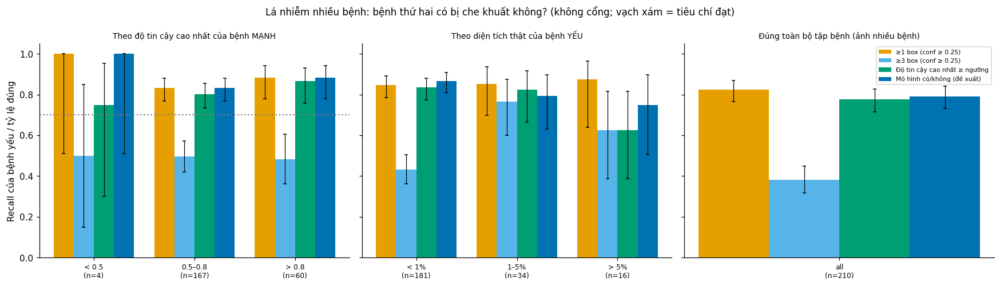

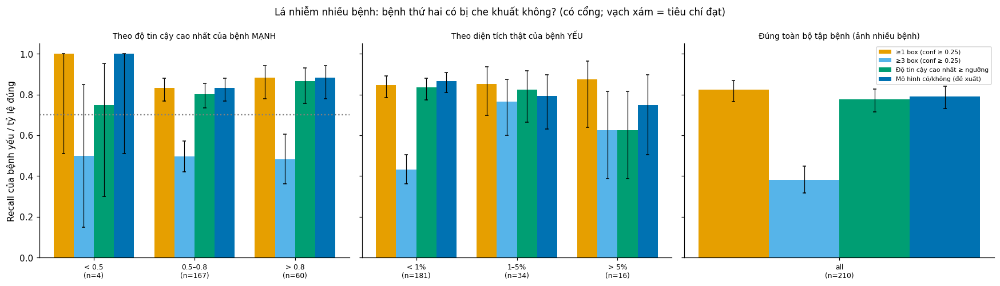

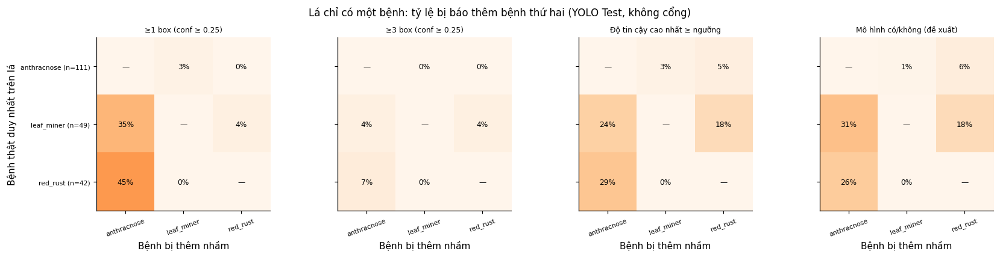

,gate,rule,by,bin,instances,weaker_recall,wilson_low,wilson_high
0,none,any_box,overall,all,231,0.848485,0.796574,0.888995
7,none,any_box,exact_set_match_coinfection,all,210,0.823810,0.766599,0.869386
8,none,three_boxes,overall,all,231,0.493506,0.429669,0.557556
15,none,three_boxes,exact_set_match_coinfection,all,210,0.380952,0.317968,0.448214
16,none,max_conf_rule,overall,all,231,0.818182,0.763374,0.862580
23,none,max_conf_rule,exact_set_match_coinfection,all,210,0.776190,0.715146,0.827312
24,none,presence_model,overall,all,231,0.848485,0.796574,0.888995
31,none,presence_model,exact_set_match_coinfection,all,210,0.790476,0.730463,0.840053
32,ensemble,any_box,overall,all,231,0.848485,0.796574,0.888995
39,ensemble,any_box,exact_set_match_coinfection,all,210,0.823810,0.766599,0.869386


In [11]:
# Co-infection stress test (YOLO test images with >= 2 true diseases).
test_idx = np.flatnonzero(TEST_MASK)
instances = []
for i in test_idx:
    present = [j for j in range(3) if Y_ALL[i, j] == 1]
    if len(present) < 2:
        continue
    conf = {j: float(EVAL[f"{DISEASES[j]}__max_conf"].iat[i]) for j in present}
    strong = max(present, key=lambda j: (conf[j], -j))
    for weak in present:
        if weak == strong:
            continue
        row = {"row_index": i, "evidence_key": EVAL.evidence_key.iat[i], "stronger": DISEASES[strong],
               "weaker": DISEASES[weak], "stronger_max_conf": conf[strong], "weaker_max_conf": conf[weak],
               "weaker_gt_coverage": float(EVAL[f"gt_coverage_{DISEASES[weak]}"].iat[i])}
        for gate in ("none", "ensemble"):
            for rule in RULES:
                row[f"hit__{gate}__{rule}"] = bool(PRED[(gate, rule)][i, weak])
        instances.append(row)
COINFECTION = pd.DataFrame(instances)
COINFECTION.to_csv(AGGREGATE / "coinfection_weaker_instances.csv", index=False)
CO_IMAGES = sorted(set(COINFECTION.row_index)) if len(COINFECTION) else []
print("Co-infection images:", len(CO_IMAGES), "| weaker-disease instances:", len(COINFECTION))

def binned(frame, column, edges, labels):
    return pd.cut(frame[column], bins=list(edges), labels=labels, right=False)

stress_rows = []
if len(COINFECTION):
    COINFECTION["stronger_bin"] = binned(COINFECTION, "stronger_max_conf", STRONGER_CONF_BINS, ["< 0.5", "0.5–0.8", "> 0.8"])
    COINFECTION["weaker_area_bin"] = binned(COINFECTION, "weaker_gt_coverage", WEAKER_AREA_BINS, ["< 1%", "1–5%", "> 5%"])
    for gate in ("none", "ensemble"):
        for rule in RULES:
            hits = COINFECTION[f"hit__{gate}__{rule}"]
            k, n = int(hits.sum()), len(hits)
            stress_rows.append({"gate": gate, "rule": rule, "by": "overall", "bin": "all", "instances": n,
                                "weaker_recall": k / n, "wilson_low": wilson_interval(k, n)[0], "wilson_high": wilson_interval(k, n)[1]})
            for by in ("stronger_bin", "weaker_area_bin"):
                for b, part in COINFECTION.groupby(by, observed=False):
                    if len(part) == 0:
                        continue
                    k, n = int(part[f"hit__{gate}__{rule}"].sum()), len(part)
                    lo, hi = wilson_interval(k, n)
                    stress_rows.append({"gate": gate, "rule": rule, "by": by, "bin": str(b), "instances": n,
                                        "weaker_recall": k / n, "wilson_low": lo, "wilson_high": hi})
            sel = np.array(CO_IMAGES, dtype=int)
            exact = (Y_ALL[sel].astype(int) == PRED[(gate, rule)][sel].astype(int)).all(1)
            lo, hi = wilson_interval(int(exact.sum()), len(sel))
            stress_rows.append({"gate": gate, "rule": rule, "by": "exact_set_match_coinfection", "bin": "all",
                                "instances": len(sel), "weaker_recall": float(exact.mean()), "wilson_low": lo, "wilson_high": hi})
STRESS = pd.DataFrame(stress_rows)
STRESS.to_csv(AGGREGATE / "coinfection_stress.csv", index=False)

if len(STRESS):
    for gate in ("none", "ensemble"):
        fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
        panels = (("stronger_bin", "Theo độ tin cậy cao nhất của bệnh MẠNH"),
                  ("weaker_area_bin", "Theo diện tích thật của bệnh YẾU"),
                  ("exact_set_match_coinfection", "Đúng toàn bộ tập bệnh (ảnh nhiều bệnh)"))
        for ax, (by, title) in zip(axes, panels):
            d = STRESS[(STRESS.gate == gate) & (STRESS.by == by)]
            bins = list(dict.fromkeys(d.bin))
            width = .8 / len(RULES)
            for r, rule in enumerate(RULES):
                part = d[d.rule == rule].set_index("bin").reindex(bins)
                x = np.arange(len(bins)) + (r - (len(RULES) - 1) / 2) * width
                ax.bar(x, part.weaker_recall, width, color=RULE_COLORS[rule], label=RULE_LABELS[rule])
                ax.errorbar(x, part.weaker_recall, yerr=yerr_from(part.weaker_recall, part.wilson_low, part.wilson_high),
                            fmt="none", ecolor="black", capsize=2, lw=.8)
            ax.set_xticks(range(len(bins)), [f"{b}\n(n={int(d[d.bin == b].instances.iloc[0])})" for b in bins], fontsize=8)
            ax.set_ylim(0, 1.05); ax.set_title(title, fontsize=9)
        axes[0].set_ylabel("Recall của bệnh yếu / tỷ lệ đúng")
        axes[0].axhline(PASS_CRITERIA["weaker_disease_recall_min"], ls=":", color="grey")
        axes[-1].legend(fontsize=7)
        fig.suptitle(f"Lá nhiễm nhiều bệnh: bệnh thứ hai có bị che khuất không? ({'không cổng' if gate == 'none' else 'có cổng'}; "
                     "vạch xám = tiêu chí đạt)", fontsize=11)
        save_figure(fig, f"coinfection_stress_{gate}.png", STRESS[STRESS.gate == gate])

# Opposite check: on single-disease images, how often is a second disease added by mistake?
added_rows = []
for gate in ("none", "ensemble"):
    for rule in RULES:
        P = PRED[(gate, rule)]
        for t, true_c in enumerate(DISEASES):
            sel = test_idx[(Y_ALL[test_idx].sum(1) == 1) & (Y_ALL[test_idx, t] == 1)]
            for a, added in enumerate(DISEASES):
                if a == t or not len(sel):
                    continue
                k, n = int(P[sel, a].sum()), len(sel)
                lo, hi = wilson_interval(k, n)
                added_rows.append({"gate": gate, "rule": rule, "true_disease": true_c, "added_disease": added,
                                   "images": n, "added": k, "rate": k / n, "wilson_low": lo, "wilson_high": hi})
ADDED = pd.DataFrame(added_rows)
ADDED.to_csv(AGGREGATE / "single_disease_added_second.csv", index=False)
if len(ADDED):
    fig, axes = plt.subplots(1, len(RULES), figsize=(4 * len(RULES), 3.8), sharey=True)
    for ax, rule in zip(axes, RULES):
        d = ADDED[(ADDED.gate == "none") & (ADDED.rule == rule)]
        m = d.pivot(index="true_disease", columns="added_disease", values="rate").reindex(index=DISEASES, columns=DISEASES)
        n = d.groupby("true_disease").images.first().reindex(DISEASES)
        ax.imshow(m.fillna(0).to_numpy(), vmin=0, vmax=1, cmap="Oranges")
        for i in range(3):
            for j in range(3):
                ax.text(j, i, "—" if i == j else f"{m.iat[i, j]:.0%}", ha="center", va="center", fontsize=8)
        ax.set_xticks(range(3), DISEASES, fontsize=7, rotation=20)
        ax.set_yticks(range(3), [f"{c} (n={int(v) if pd.notna(v) else 0})" for c, v in zip(DISEASES, n)], fontsize=7)
        ax.set_xlabel("Bệnh bị thêm nhầm"); ax.set_title(RULE_LABELS[rule], fontsize=8)
    axes[0].set_ylabel("Bệnh thật duy nhất trên lá")
    fig.suptitle("Lá chỉ có một bệnh: tỷ lệ bị báo thêm bệnh thứ hai (YOLO Test, không cổng)", fontsize=11)
    save_figure(fig, "single_disease_added_second.png", ADDED[ADDED.gate == "none"])
display(STRESS[STRESS.by.isin(["overall", "exact_set_match_coinfection"])])

## 10. Theo từng seed của cổng DenseNet

Mô hình có/không chỉ dùng bằng chứng detector nên không phụ thuộc seed; chỉ cổng DenseNet thay đổi theo seed. Xem từng seed trước, sau đó mới tóm tắt trung bình ± SD mẫu và CI95 (biến động giữa các seed trên cùng một split cố định).

,seed,images,exact_set_match,hamming_loss,micro_f1,macro_f1,samples_f1,f1_anthracnose,f1_leaf_miner,f1_red_rust,recall_anthracnose,recall_leaf_miner,recall_red_rust,false_alarm_healthy,false_alarm_non_cashew_diseased_leaf,false_alarm_not_cashew_leaf,gate_rejected_yolo_test_images
0,42,488,0.813525,0.063525,0.928185,0.929117,0.934426,0.925984,0.932271,0.929095,0.939297,0.886364,0.959596,0.033898,0.0,0.0,77
1,123,488,0.813525,0.063525,0.928185,0.929117,0.934426,0.925984,0.932271,0.929095,0.939297,0.886364,0.959596,0.025424,0.0,0.0,77
2,2026,488,0.815574,0.062842,0.929012,0.929680,0.936475,0.927673,0.932271,0.929095,0.942492,0.886364,0.959596,0.033898,0.0,0.0,76
3,3407,488,0.813525,0.063525,0.928185,0.929117,0.934426,0.925984,0.932271,0.929095,0.939297,0.886364,0.959596,0.042373,0.0,0.0,77
4,7777,488,0.811475,0.064208,0.927357,0.928552,0.932377,0.924290,0.932271,0.929095,0.936102,0.886364,0.959596,0.025424,0.0,0.0,79


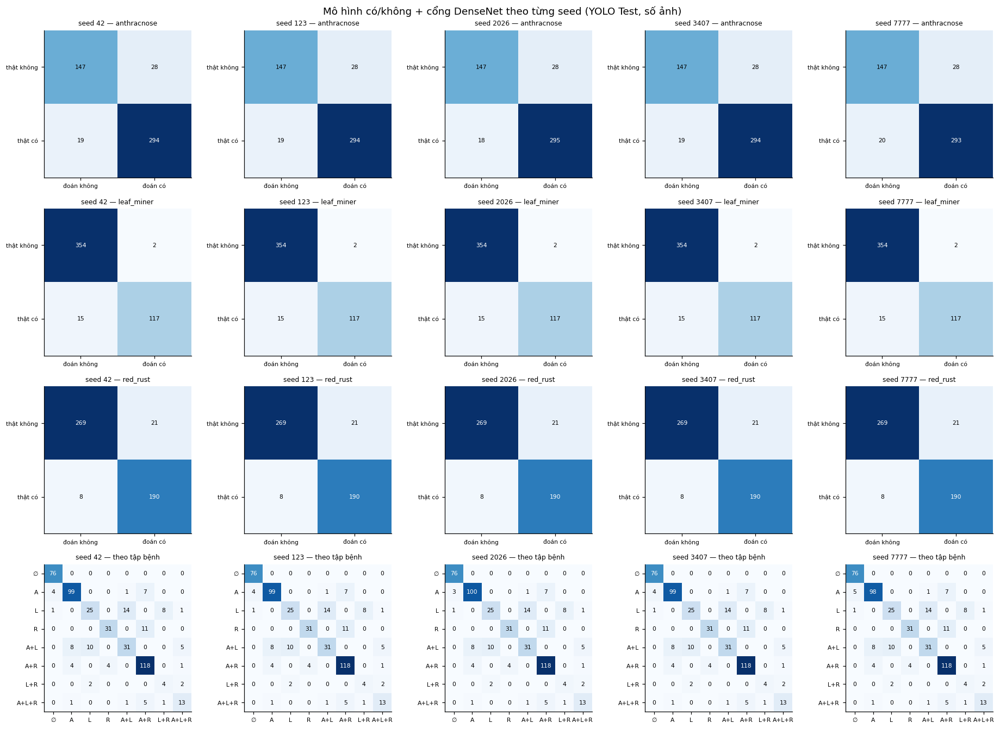

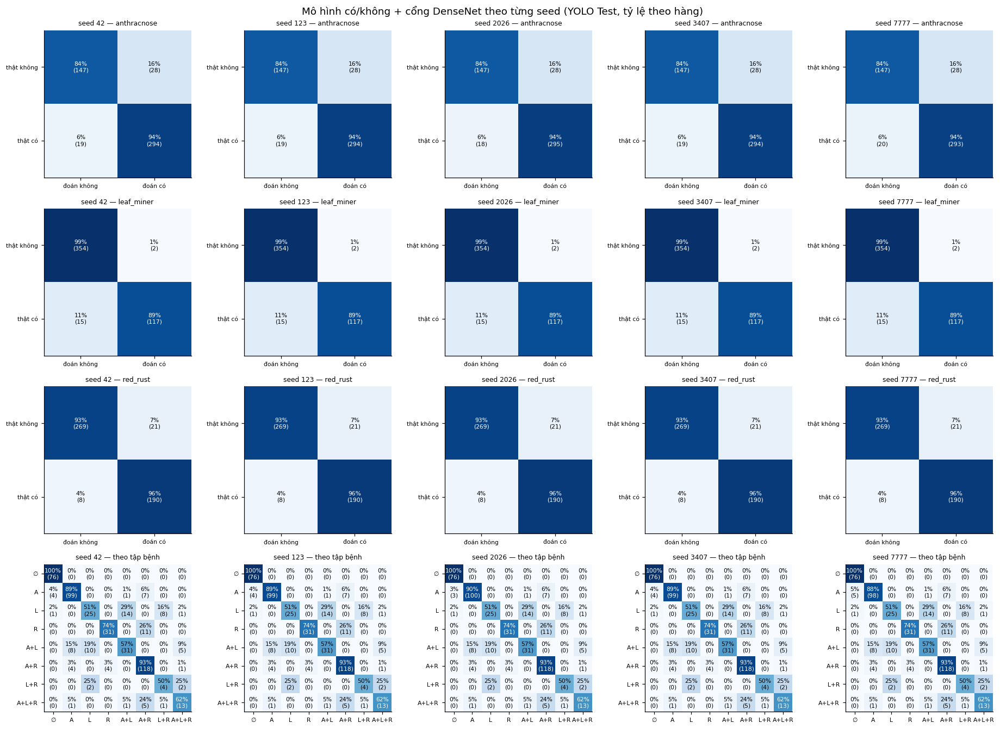

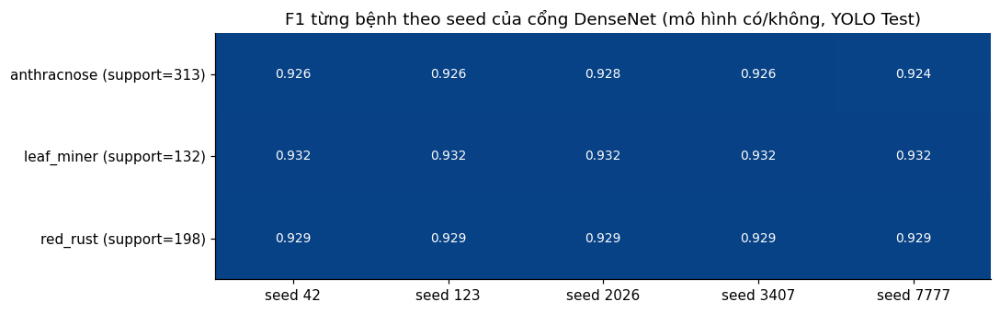

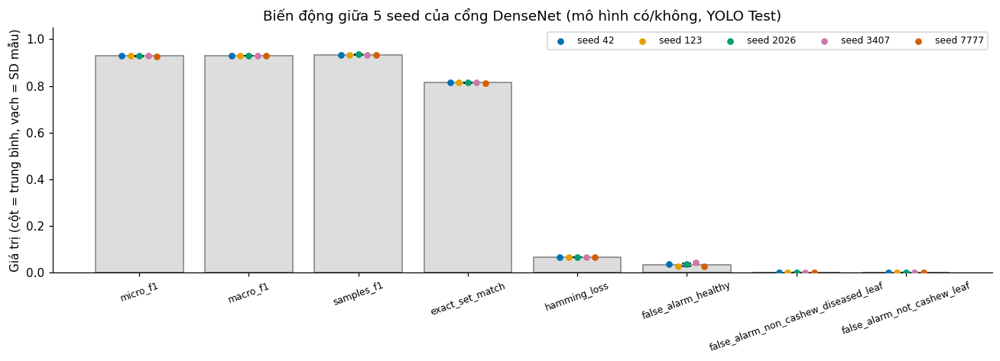

,metric,n_seeds,mean,sd_ddof1,ci95_low,ci95_high,assumption
0,micro_f1,5,0.928185,0.000585,0.927458,0.928912,variation across DenseNet gate seeds on a fixe...
1,macro_f1,5,0.929116,0.000399,0.928621,0.929611,variation across DenseNet gate seeds on a fixe...
2,samples_f1,5,0.934426,0.001449,0.932627,0.936225,variation across DenseNet gate seeds on a fixe...
3,exact_set_match,5,0.813525,0.001449,0.811725,0.815324,variation across DenseNet gate seeds on a fixe...
4,hamming_loss,5,0.063525,0.000483,0.062925,0.064124,variation across DenseNet gate seeds on a fixe...
5,false_alarm_healthy,5,0.032203,0.007090,0.023400,0.041007,variation across DenseNet gate seeds on a fixe...
6,false_alarm_non_cashew_diseased_leaf,5,0.000000,0.000000,0.000000,0.000000,variation across DenseNet gate seeds on a fixe...
7,false_alarm_not_cashew_leaf,5,0.000000,0.000000,0.000000,0.000000,variation across DenseNet gate seeds on a fixe...


In [12]:
# Gated results per DenseNet seed (variation first), then the across-seed summary.
# The gate-free result above has no seed (SD not applicable).
seed_rows, seed_reports = [], []
for seed in SEEDS:
    gate = f"seed_{seed}"
    P = PRED[(gate, PROPOSED_RULE)]
    rep = multilabel_report(Y_ALL[TEST_MASK], P[TEST_MASK]).assign(seed=seed)
    rep.to_csv(OUT_DIR / f"seed_{seed}" / "presence_classification_report_yolo_test.csv", index=False)
    seed_reports.append(rep)
    fa = FALSE_ALARMS[(FALSE_ALARMS.gate == gate) & (FALSE_ALARMS.rule == PROPOSED_RULE) & (FALSE_ALARMS.variant == "all")]
    row = {"seed": seed, **set_metrics(Y_ALL[TEST_MASK], P[TEST_MASK]),
           "micro_f1": rep.loc[rep.row == "micro avg", "f1"].iat[0],
           "macro_f1": rep.loc[rep.row == "macro avg (support>0)", "f1"].iat[0],
           "samples_f1": rep.loc[rep.row == "samples avg", "f1"].iat[0],
           **{f"f1_{c}": rep.loc[rep.row == c, "f1"].iat[0] for c in DISEASES},
           **{f"recall_{c}": rep.loc[rep.row == c, "recall"].iat[0] for c in DISEASES},
           **{f"false_alarm_{g}": float(fa.loc[fa.group == g, "false_alarm_rate"].iat[0]) if (fa.group == g).any() else None
              for g in ("healthy", "non_cashew_diseased_leaf", "not_cashew_leaf")},
           "gate_rejected_yolo_test_images": int(np.isin(GATE_LABELS[gate][TEST_MASK], NEGATIVE_LABELS).sum())}
    seed_rows.append(row)
SEED_TABLE = pd.DataFrame(seed_rows)
SEED_TABLE.to_csv(AGGREGATE / "presence_gated_by_seed.csv", index=False)
pd.concat(seed_reports).to_csv(AGGREGATE / "presence_classification_report_by_seed.csv", index=False)
display(SEED_TABLE)

for normalized in (False, True):
    fig, axes = plt.subplots(len(DISEASES) + 1, len(SEEDS), figsize=(3.4 * len(SEEDS), 3.1 * (len(DISEASES) + 1)))
    plotted = []
    for col, seed in enumerate(SEEDS):
        P = PRED[(f"seed_{seed}", PROPOSED_RULE)]
        for i, c in enumerate(DISEASES):
            m = two_by_two(Y_ALL[TEST_MASK, i].astype(int), P[TEST_MASK, i].astype(int))
            draw_counts(axes[i, col], m, normalized, f"seed {seed} — {c}", ["đoán không", "đoán có"], ["thật không", "thật có"])
            plotted.append({"seed": seed, "disease": c, "tn": m[0, 0], "fp": m[0, 1], "fn": m[1, 0], "tp": m[1, 1]})
        sm = set_matrix(Y_ALL[TEST_MASK], P[TEST_MASK])
        draw_counts(axes[-1, col], sm.to_numpy(), normalized, f"seed {seed} — theo tập bệnh", list(sm.columns), list(sm.index))
    kind = "normalized" if normalized else "raw"
    fig.suptitle(f"Mô hình có/không + cổng DenseNet theo từng seed (YOLO Test, {'tỷ lệ theo hàng' if normalized else 'số ảnh'})",
                 fontsize=12)
    save_figure(fig, f"panels/presence_confusion_{kind}_1x5.png", pd.DataFrame(plotted))

f1 = pd.concat(seed_reports)
f1 = f1[f1.row.isin(DISEASES) & (f1.support > 0)]
heat = f1.pivot(index="row", columns="seed", values="f1").reindex([c for c in DISEASES if c in set(f1.row)])
support = f1.groupby("row").support.first()
fig, ax = plt.subplots(figsize=(1.6 * len(SEEDS) + 2, 3.2))
ax.imshow(heat.to_numpy(float), vmin=0, vmax=1, cmap="Blues", aspect="auto")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.iat[i, j]:.3f}", ha="center", va="center", fontsize=9,
                color="white" if heat.iat[i, j] > .6 else "black")
ax.set_xticks(range(len(SEEDS)), [f"seed {s}" for s in SEEDS])
ax.set_yticks(range(len(heat)), [f"{c} (support={int(support[c])})" for c in heat.index])
ax.set_title("F1 từng bệnh theo seed của cổng DenseNet (mô hình có/không, YOLO Test)")
save_figure(fig, "per_class_f1_heatmap_presence.png", f1[["seed", "row", "precision", "recall", "f1", "support"]])

SEED_METRICS = ["micro_f1", "macro_f1", "samples_f1", "exact_set_match", "hamming_loss",
                "false_alarm_healthy", "false_alarm_non_cashew_diseased_leaf", "false_alarm_not_cashew_leaf"]
t_crit = float(stats.t.ppf(0.975, len(SEEDS) - 1))
ci_rows = []
for metric in SEED_METRICS:
    values = pd.to_numeric(SEED_TABLE[metric], errors="coerce").dropna().to_numpy(float)
    if len(values) < 2:
        continue
    mean, sd = values.mean(), values.std(ddof=1)
    half = t_crit * sd / math.sqrt(len(values))
    ci_rows.append({"metric": metric, "n_seeds": len(values), "mean": mean, "sd_ddof1": sd,
                    "ci95_low": mean - half, "ci95_high": mean + half,
                    "assumption": "variation across DenseNet gate seeds on a fixed split; t(0.975, 4) x SD / sqrt(5)"})
SEED_CI = pd.DataFrame(ci_rows)
SEED_CI.to_csv(AGGREGATE / "seed_ci95_presence.csv", index=False)
fig, ax = plt.subplots(figsize=(12, 4.4))
dots = []
for x, metric in enumerate(SEED_CI.metric):
    row = SEED_CI[SEED_CI.metric == metric].iloc[0]
    ax.bar(x, row["mean"], color="#DDDDDD", edgecolor="grey")
    ax.errorbar(x, row["mean"], yerr=row["sd_ddof1"], fmt="none", ecolor="black", capsize=4)
    for k, seed in enumerate(SEEDS):
        v = SEED_TABLE.loc[SEED_TABLE.seed == seed, metric].iat[0]
        if v is not None and pd.notna(v):
            ax.scatter(x + (k - 2) * .08, v, color=SEED_COLORS[seed], s=22, zorder=5, label=f"seed {seed}" if x == 0 else None)
            dots.append({"metric": metric, "seed": seed, "value": v})
ax.set_xticks(range(len(SEED_CI)), SEED_CI.metric, rotation=20, fontsize=8)
ax.set_ylim(0, 1.05); ax.set_ylabel("Giá trị (cột = trung bình, vạch = SD mẫu)")
ax.legend(fontsize=8, ncol=5)
ax.set_title("Biến động giữa 5 seed của cổng DenseNet (mô hình có/không, YOLO Test)")
save_figure(fig, "seed_metric_errorbars_presence.png", pd.DataFrame(dots).merge(SEED_CI, on="metric"))
display(SEED_CI)

## 11. So sánh thống kê và báo nhầm

So sánh ghép cặp `presence_model` trừ từng quy tắc khác trên **cùng** ảnh: bootstrap 10 000 lần (khoảng 95%) và McNemar chính xác. Báo nhầm trên 3 nhóm ảnh không bệnh, mỗi nhóm có khoảng Wilson riêng.

,gate,baseline,metric,delta,ci95_low,ci95_high,mcnemar_b_proposed_only,mcnemar_c_baseline_only,mcnemar_exact_p,bootstrap_resamples
0,none,any_box,exact_set_match,-0.028689,-0.057377,0.000000,20.0,34.0,7.590473e-02,10000
1,none,any_box,f1_anthracnose,0.007380,-0.005973,0.021475,15.0,8.0,2.100396e-01,10000
2,none,any_box,f1_leaf_miner,-0.021575,-0.047041,0.000813,2.0,7.0,1.796875e-01,10000
3,none,any_box,f1_red_rust,-0.027107,-0.053478,-0.002150,8.0,21.0,2.411954e-02,10000
4,none,any_box,weaker_disease_recall,0.000000,-0.033981,0.033836,NaN,NaN,NaN,10000
5,none,three_boxes,exact_set_match,0.174180,0.127049,0.219314,119.0,34.0,2.962980e-12,10000
6,none,three_boxes,f1_anthracnose,0.126965,0.090945,0.164596,83.0,24.0,8.577709e-09,10000
7,none,three_boxes,f1_leaf_miner,0.476131,0.388717,0.570317,78.0,2.0,5.361785e-21,10000
8,none,three_boxes,f1_red_rust,-0.017020,-0.049466,0.014564,16.0,26.0,1.641494e-01,10000
9,none,three_boxes,weaker_disease_recall,0.354978,0.292180,0.418702,NaN,NaN,NaN,10000


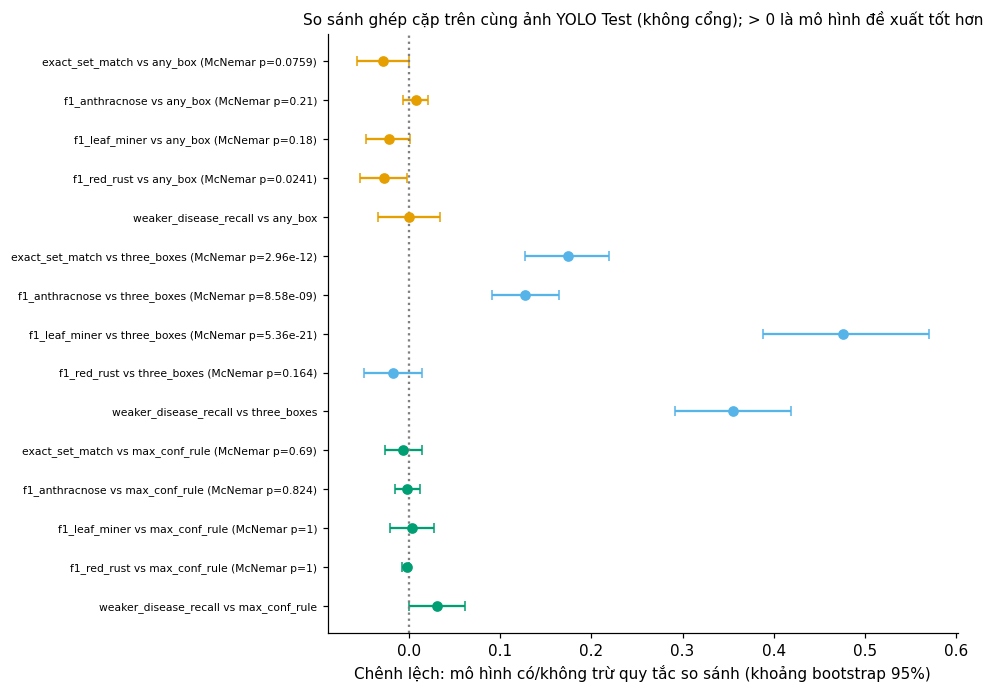

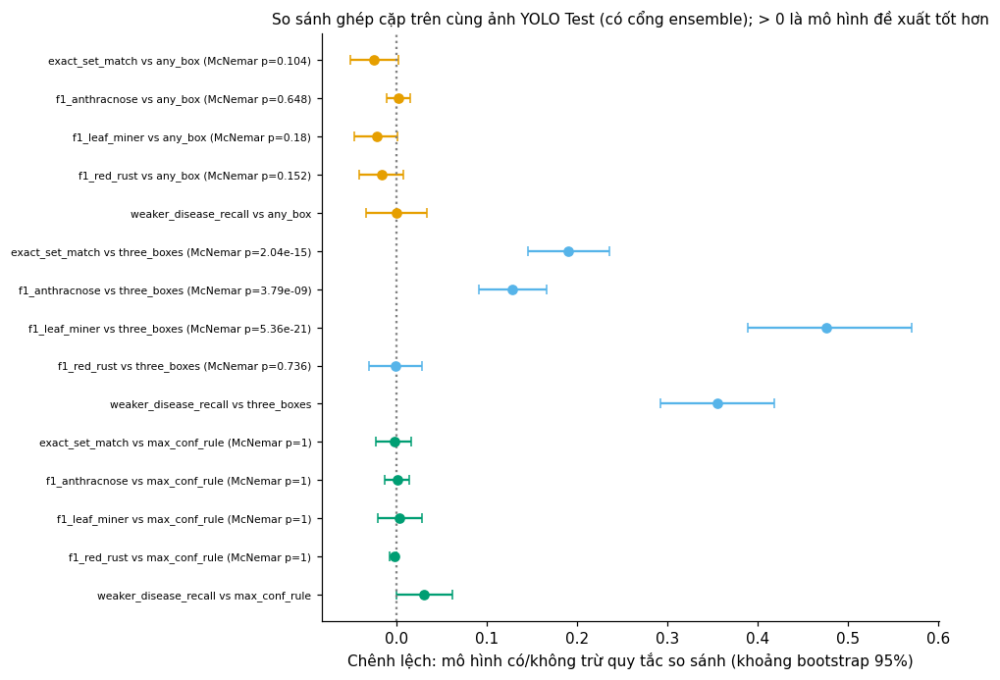

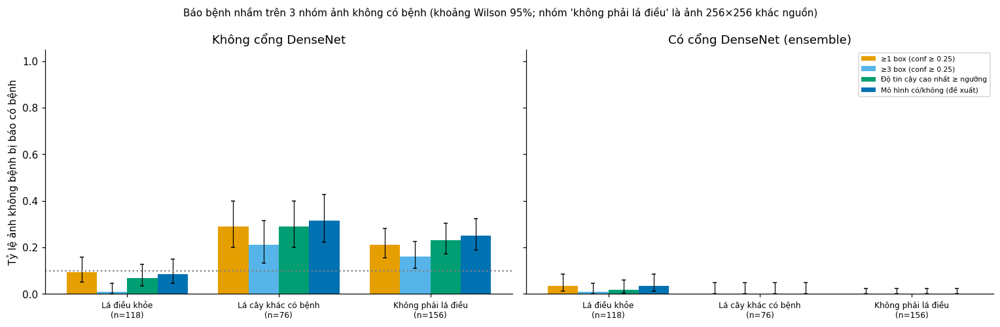

PosixPath('/content/training_results/current_dataset/EXP-036/figures/false_alarm_negative_groups.png')

In [13]:
# Paired comparison presence_model minus each baseline on the same YOLO-test images.
rng = np.random.default_rng(BOOTSTRAP_SEED)
n_test = len(test_idx)
BOOT_IDX = rng.integers(0, n_test, (BOOTSTRAP_RESAMPLES, n_test))

def mcnemar_exact(a_correct, b_correct):
    b = int((a_correct & ~b_correct).sum()); c = int((~a_correct & b_correct).sum())
    p = 1.0 if b + c == 0 else float(stats.binomtest(min(b, c), b + c, 0.5).pvalue)
    return b, c, p

def boot_f1(y, p, idx):
    tp = (y & p).astype(np.int32); fp = (~y & p).astype(np.int32); fn = (y & ~p).astype(np.int32)
    TP, FP, FN = tp[idx].sum(1), fp[idx].sum(1), fn[idx].sum(1)
    denom = 2 * TP + FP + FN
    return np.where(denom > 0, 2 * TP / np.maximum(denom, 1), np.nan)

# Weaker-disease instances per test image (for the co-infection comparison).
pos_of = {i: k for k, i in enumerate(test_idx)}
weak_count = np.zeros(n_test)
weak_hits = {}
for gate in ("none", "ensemble"):
    for rule in RULES:
        weak_hits[(gate, rule)] = np.zeros(n_test)
for row in COINFECTION.itertuples() if len(COINFECTION) else []:
    k = pos_of[row.row_index]
    weak_count[k] += 1
    for gate in ("none", "ensemble"):
        for rule in RULES:
            weak_hits[(gate, rule)][k] += getattr(row, f"hit__{gate}__{rule}")

comparison_rows = []
for gate in ("none", "ensemble"):
    Yt = Y_ALL[test_idx].astype(bool)
    Pp = PRED[(gate, PROPOSED_RULE)][test_idx]
    exact_p = (Yt == Pp).all(1)
    for base in [r for r in RULES if r != PROPOSED_RULE]:
        Pb = PRED[(gate, base)][test_idx]
        exact_b = (Yt == Pb).all(1)
        diff = exact_p.astype(float) - exact_b.astype(float)
        dist = diff[BOOT_IDX].mean(1)
        b, c, p = mcnemar_exact(exact_p, exact_b)
        comparison_rows.append({"gate": gate, "baseline": base, "metric": "exact_set_match", "delta": float(diff.mean()),
                                "ci95_low": float(np.quantile(dist, .025)), "ci95_high": float(np.quantile(dist, .975)),
                                "mcnemar_b_proposed_only": b, "mcnemar_c_baseline_only": c, "mcnemar_exact_p": p})
        for j, cname in enumerate(DISEASES):
            y = Yt[:, j]
            fp_, fb_ = boot_f1(y, Pp[:, j], BOOT_IDX), boot_f1(y, Pb[:, j], BOOT_IDX)
            full = boot_f1(y, Pp[:, j], np.arange(n_test)[None, :])[0] - boot_f1(y, Pb[:, j], np.arange(n_test)[None, :])[0]
            d = fp_ - fb_
            b, c, p = mcnemar_exact(Pp[:, j] == y, Pb[:, j] == y)
            comparison_rows.append({"gate": gate, "baseline": base, "metric": f"f1_{cname}", "delta": float(full),
                                    "ci95_low": float(np.nanquantile(d, .025)), "ci95_high": float(np.nanquantile(d, .975)),
                                    "mcnemar_b_proposed_only": b, "mcnemar_c_baseline_only": c, "mcnemar_exact_p": p})
        if weak_count.sum() > 0:
            hp, hb = weak_hits[(gate, PROPOSED_RULE)], weak_hits[(gate, base)]
            num = (hp - hb)[BOOT_IDX].sum(1); den = weak_count[BOOT_IDX].sum(1)
            dist = np.where(den > 0, num / np.maximum(den, 1), np.nan)
            comparison_rows.append({"gate": gate, "baseline": base, "metric": "weaker_disease_recall",
                                    "delta": float((hp - hb).sum() / weak_count.sum()),
                                    "ci95_low": float(np.nanquantile(dist, .025)), "ci95_high": float(np.nanquantile(dist, .975)),
                                    "mcnemar_b_proposed_only": None, "mcnemar_c_baseline_only": None, "mcnemar_exact_p": None})
COMPARISON = pd.DataFrame(comparison_rows)
COMPARISON["bootstrap_resamples"] = BOOTSTRAP_RESAMPLES
COMPARISON.to_csv(AGGREGATE / "paired_comparison_presence_vs_baselines.csv", index=False)
display(COMPARISON)

for gate in ("none", "ensemble"):
    d = COMPARISON[COMPARISON.gate == gate].reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(9, .32 * len(d) + 1.6))
    y = np.arange(len(d))[::-1]
    for k, row in d.iterrows():
        ax.errorbar(row.delta, y[k], xerr=yerr_from([row.delta], [row.ci95_low], [row.ci95_high]), fmt="o",
                    color=RULE_COLORS[row.baseline], capsize=3)
    ax.axvline(0, color="grey", ls=":")
    labels = [f"{r.metric} vs {r.baseline}" + (f" (McNemar p={r.mcnemar_exact_p:.3g})" if pd.notna(r.mcnemar_exact_p) else "")
              for r in d.itertuples()]
    ax.set_yticks(y, labels, fontsize=7)
    ax.set_xlabel("Chênh lệch: mô hình có/không trừ quy tắc so sánh (khoảng bootstrap 95%)")
    ax.set_title(f"So sánh ghép cặp trên cùng ảnh YOLO Test ({'không cổng' if gate == 'none' else 'có cổng ensemble'}); "
                 "> 0 là mô hình đề xuất tốt hơn", fontsize=10)
    save_figure(fig, f"forest_presence_vs_baselines_{gate}.png", d)

# (10) False alarms on the three negative groups (Wilson 95%), never pooled.
fa = FALSE_ALARMS[FALSE_ALARMS.gate.isin(["none", "ensemble"]) & (FALSE_ALARMS.variant == "all")]
groups_present = [g for g in NEG_GROUP_SOURCES if (fa.group == g).any()]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, gate in zip(axes, ("none", "ensemble")):
    d = fa[fa.gate == gate]
    width = .8 / len(RULES)
    for r, rule in enumerate(RULES):
        part = d[d.rule == rule].set_index("group").reindex(groups_present)
        x = np.arange(len(groups_present)) + (r - (len(RULES) - 1) / 2) * width
        ax.bar(x, part.false_alarm_rate, width, color=RULE_COLORS[rule], label=RULE_LABELS[rule])
        ax.errorbar(x, part.false_alarm_rate, yerr=yerr_from(part.false_alarm_rate, part.wilson_low, part.wilson_high),
                    fmt="none", ecolor="black", capsize=2, lw=.8)
    ax.set_xticks(range(len(groups_present)),
                  [f"{GROUP_LABELS[g]}\n(n={int(d[d.group == g].images.iloc[0])})" for g in groups_present], fontsize=8)
    ax.set_title("Không cổng DenseNet" if gate == "none" else "Có cổng DenseNet (ensemble)")
    ax.set_ylim(0, 1.05)
axes[0].axhline(PASS_CRITERIA["false_alarm_healthy_max"], ls=":", color="grey")
axes[0].set_ylabel("Tỷ lệ ảnh không bệnh bị báo có bệnh")
axes[-1].legend(fontsize=7)
fig.suptitle("Báo bệnh nhầm trên 3 nhóm ảnh không có bệnh (khoảng Wilson 95%; nhóm 'không phải lá điều' là ảnh 256×256 khác nguồn)",
             fontsize=10)
save_figure(fig, "false_alarm_negative_groups.png", fa)

## 12. Ảnh minh họa, Holdout và bối cảnh

6 ảnh YOLO Test cố định (cách đều theo thứ tự tên, không chọn tay); ảnh Holdout cho người có chuyên môn xem; Holdout chỉ là kiểm tra mô tả. Đường huấn luyện DenseNet của EXP-035 được chép lại; bảng V03 và V04 chỉ để tham khảo.

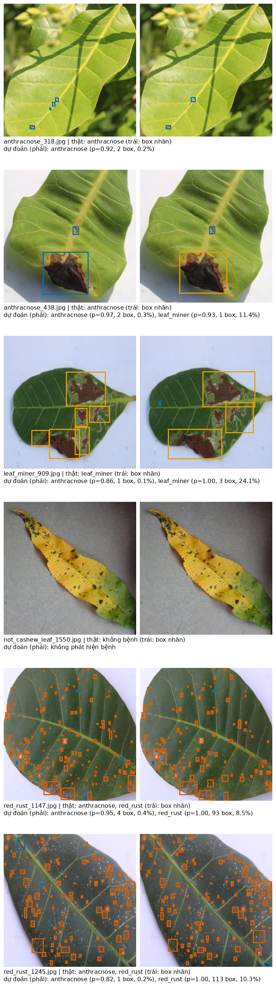

,true_label,images,label_in_list,mean_list_length,lists_with_2plus,note
0,anthracnose,46,0.934783,1.347826,19,"descriptive audit, not a blind benchmark (Hold..."
1,healthy,19,1.000000,0.000000,0,"descriptive audit, not a blind benchmark (Hold..."
2,leaf_miner,36,0.944444,1.777778,23,"descriptive audit, not a blind benchmark (Hold..."
3,red_rust,25,1.000000,1.840000,21,"descriptive audit, not a blind benchmark (Hold..."
4,all,126,0.960317,1.365079,63,"descriptive audit, not a blind benchmark (Hold..."


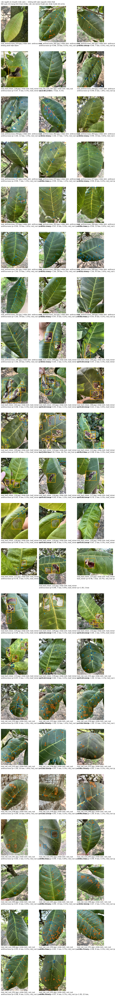

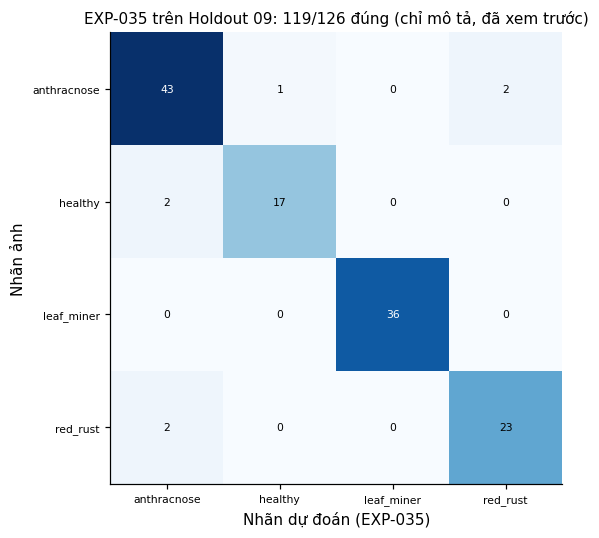

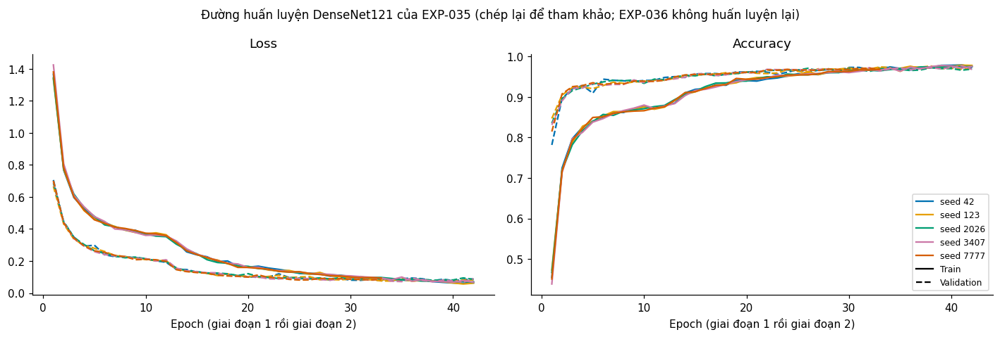

Copied EXP-035 PNGs: ['00_densenet_component_training_curves.png']
v03_context_yolo_test 488 images 46701 raw boxes (conf >= 0.05)
V03 context: ok


,detector,subset,images,images_with_box_conf020,images_with_box_conf025,boxes_per_image_conf025_mean,boxes_per_image_conf025_median,status
0,EXP-Y26S-NEG-V04-001,all,488,437,434,32.092213,9.5,ok
1,EXP-Y26S-NEG-V04-001,positives,412,412,412,37.611650,16.0,ok
2,EXP-Y26S-NEG-V04-001,negatives_76,76,25,22,2.171053,0.0,ok
3,EXP-Y26S-NEG-V04-001,negatives_non_cashew_diseased_leaf,76,25,22,2.171053,0.0,ok
4,EXP-Y26S-NEG-V03-001,all,488,470,465,34.375000,13.0,ok
5,EXP-Y26S-NEG-V03-001,positives,412,412,412,39.536408,19.5,ok
6,EXP-Y26S-NEG-V03-001,negatives_76,76,58,53,6.394737,3.0,ok
7,EXP-Y26S-NEG-V03-001,negatives_non_cashew_diseased_leaf,76,58,53,6.394737,3.0,ok


Sanity EXP-Y26S-NEG-V04-001: 25/76 negatives with a box at conf >= 0.2 (reference 25/76) -> OK
Sanity EXP-Y26S-NEG-V03-001: 58/76 negatives with a box at conf >= 0.2 (reference 58/76) -> OK


In [14]:
# Qualitative panels, Holdout descriptive audit, EXP-035 context figures, V03/V04 evidence context.
TILE = 360

def load_tile(path):
    with Image.open(path) as handle:
        rgb = np.asarray(handle.convert("RGB"))  # same orientation as the detector/tf decode (no EXIF transpose)
    h, w = rgb.shape[:2]
    scale = TILE / max(h, w)
    tile = np.asarray(Image.fromarray(rgb).resize((max(1, round(w * scale)), max(1, round(h * scale)))))
    return tile, scale

def scaled_result(result, scale):
    out = json.loads(json.dumps(result))
    for d in out["diseases"]:
        for b in d["boxes"]:
            b["xyxy"] = [v * scale for v in b["xyxy"]]
    return out

def checked_draw(tile, result):
    """draw_analysis + assert that box pixels exist whenever boxes should be drawn."""
    image = draw_analysis(tile, result)
    pixels = np.asarray(image)
    for d in result["diseases"]:
        if d["boxes"]:
            color = np.array(DRAW_COLORS[d["name"]], dtype=np.uint8)
            before = int(np.all(np.asarray(tile) == color, axis=2).sum())
            after = int(np.all(pixels == color, axis=2).sum())
            assert after > before, f"no box pixels drawn for {d['name']}"
    return image

def gt_result(key, scale):
    return {"diseases": [{"name": c, "boxes": [{"xyxy": [v * scale for v in b], "conf": 1.0}
                                               for cls, b in GT_BOXES.get(key, []) if cls == c]}
                         for c in DISEASES if any(cls == c for cls, _ in GT_BOXES.get(key, []))]}

def caption(draw, xy, lines):
    y = xy[1]
    for line in lines:
        assert not missing_glyphs(line), line
        draw.text((xy[0], y), line, fill="black", font=PANEL_FONT)
        y += 20

def result_for(key, gate="ensemble"):
    raw, h, w = RAW[key]
    probs = DENSE[gate].loc[key, PROB_COLUMNS].to_numpy(float)
    return presence_result(probs, raw, h, w, STACKER_035, CONFIG_035, PRESENCE_MODELS, FROZEN_CONFIG_036)

def disease_list(result):
    if not result["diseases"]:
        return result["message_vi"]
    return ", ".join(f"{d['name']} (p={d['present_prob']:.2f}, {d['n_lesions']} box, {d['coverage_percent']:.1f}%)"
                     for d in result["diseases"])

# (11) Six fixed YOLO-test images: evenly spaced in sorted key order (no cherry picking).
sorted_test = sorted(yolo_test.evidence_key)
FIXED_TEST = [sorted_test[int(round(k))] for k in np.linspace(0, len(sorted_test) - 1, N_FIXED_TEST_PANEL)]
panel_rows = []
canvas = Image.new("RGB", (2 * TILE + 30, len(FIXED_TEST) * (TILE + 90) + 10), "white")
draw = ImageDraw.Draw(canvas)
for r, key in enumerate(FIXED_TEST):
    tile, scale = load_tile(yolo_test.set_index("evidence_key").loc[key, "path"])
    result = result_for(key)
    truth = [c for c in DISEASES if gt_test.loc[key, f"gt_{c}"] == 1]
    top = 10 + r * (TILE + 90)
    canvas.paste(checked_draw(tile, gt_result(key, scale)), (10, top))
    canvas.paste(checked_draw(tile, scaled_result(result, scale)), (20 + TILE, top))
    caption(draw, (10, top + tile.shape[0] + 4), [f"{Path(key).name} | thật: {', '.join(truth) or 'không bệnh'} (trái: box nhãn)",
                                                 f"dự đoán (phải): {disease_list(result)}"[:110]])
    panel_rows.append({"evidence_key": key, "true_set": ", ".join(truth), "predicted": disease_list(result),
                       "image_label": result["image_label"]})
canvas.save(FIGURES / "test_examples_fixed6.png", dpi=(200, 200))
pd.DataFrame(panel_rows).to_csv(FIGURES / "test_examples_fixed6.csv", index=False)
display(canvas)

# Holdout descriptive audit (no box labels): ensemble gate + presence_model.
hold = EVAL[EVAL.eval_set == "holdout"].copy()
hold_results = {key: result_for(key) for key in hold.evidence_key}
hold["predicted_list"] = [", ".join(d["name"] for d in hold_results[k]["diseases"]) for k in hold.evidence_key]
hold["list_length"] = [len(hold_results[k]["diseases"]) for k in hold.evidence_key]
hold["image_label"] = [hold_results[k]["image_label"] for k in hold.evidence_key]
hold["true_label_in_list"] = [(t in [d["name"] for d in hold_results[k]["diseases"]]) if t in DISEASES
                              else hold_results[k]["diseases"] == [] for k, t in zip(hold.evidence_key, hold.true_label)]
HOLDOUT_AUDIT = (hold.groupby("true_label").agg(images=("evidence_key", "size"), label_in_list=("true_label_in_list", "mean"),
                                                mean_list_length=("list_length", "mean"),
                                                lists_with_2plus=("list_length", lambda v: int((v >= 2).sum())))
                 .reset_index())
HOLDOUT_AUDIT.loc[len(HOLDOUT_AUDIT)] = ["all", len(hold), hold.true_label_in_list.mean(), hold.list_length.mean(),
                                         int((hold.list_length >= 2).sum())]
HOLDOUT_AUDIT["note"] = "descriptive audit, not a blind benchmark (Holdout 09 seen in EXP-032/035; no box labels)"
HOLDOUT_AUDIT.to_csv(AGGREGATE / "holdout_presence_descriptive_audit.csv", index=False)
hold[["evidence_key", "true_label", "image_label", "predicted_list", "list_length", "true_label_in_list"] +
     [f"present_prob_{c}" for c in DISEASES]].to_csv(AGGREGATE / "holdout_presence_predictions.csv", index=False)
display(HOLDOUT_AUDIT)

# (12) Holdout images for expert review: the fixed five + every image with >= 2 reported diseases.
review = [k for k in sorted(hold.evidence_key) if Path(k).stem in FIXED_HOLDOUT_REVIEW]
missing_review = sorted(set(FIXED_HOLDOUT_REVIEW) - {Path(k).stem for k in review})
if missing_review:
    print("WARNING: fixed Holdout review images not found:", missing_review)
review += [k for k in sorted(hold.evidence_key) if hold_results[k]["diseases"] and len(hold_results[k]["diseases"]) >= 2
           and k not in review]
cols = 3
rows_n = max(1, math.ceil(len(review) / cols))
canvas = Image.new("RGB", (cols * (TILE + 20) + 10, rows_n * (TILE + 90) + 60), "white")
draw = ImageDraw.Draw(canvas)
caption(draw, (10, 10), ["cần người có chuyên môn xem — không kết luận nguyên nhân thật",
                         "Kết quả chỉ mang tính tham khảo; cần cán bộ kỹ thuật xác nhận trước khi xử lý."])
review_rows = []
for n, key in enumerate(review):
    tile, scale = load_tile(INVENTORY["holdout"].set_index("evidence_key").loc[key, "path"])
    result = hold_results[key]
    x, y = 10 + (n % cols) * (TILE + 20), 60 + (n // cols) * (TILE + 90)
    canvas.paste(checked_draw(tile, scaled_result(result, scale)), (x, y))
    caption(draw, (x, y + tile.shape[0] + 4), [f"{Path(key).name} | nhãn ảnh: {hold.set_index('evidence_key').loc[key, 'true_label']}",
                                               disease_list(result)[:60]])
    review_rows.append({"evidence_key": key, "true_label": hold.set_index("evidence_key").loc[key, "true_label"],
                        "predicted": disease_list(result), "image_label": result["image_label"]})
canvas.save(FIGURES / "holdout_expert_review.png", dpi=(200, 200))
pd.DataFrame(review_rows).to_csv(FIGURES / "holdout_expert_review.csv", index=False)
display(canvas)

# EXP-035 single-label Holdout report, copied: macro-F1 over classes with support > 0, no empty rows.
saved_hold = EXP035_SAVED["holdout"]
present = [c for c in CLASSES if (saved_hold.true_label == c).any()]
p, r, f, s = precision_recall_fscore_support(saved_hold.true_label, saved_hold.predicted_label, labels=present, zero_division=0)
EXP035_HOLDOUT_REPORT = pd.DataFrame({"class": present, "precision": p, "recall": r, "f1": f, "support": s})
EXP035_HOLDOUT_REPORT.loc[len(EXP035_HOLDOUT_REPORT)] = ["macro avg (support>0)", p.mean(), r.mean(), f.mean(), int(s.sum())]
EXP035_HOLDOUT_REPORT.to_csv(AGGREGATE / "exp035_holdout_classification_report.csv", index=False)
pred_cols = present + [c for c in CLASSES if c not in present and (saved_hold.predicted_label == c).any()]
cm = pd.crosstab(saved_hold.true_label, saved_hold.predicted_label).reindex(index=present, columns=pred_cols, fill_value=0)
fig, ax = plt.subplots(figsize=(6.4, 5))
draw_counts(ax, cm.to_numpy(), False, "", list(cm.columns), list(cm.index))
ax.set_xlabel("Nhãn dự đoán (EXP-035)"); ax.set_ylabel("Nhãn ảnh")
ax.set_title(f"EXP-035 trên Holdout 09: {int(np.trace(cm.to_numpy()))}/{len(saved_hold)} đúng (chỉ mô tả, đã xem trước)", fontsize=10)
save_figure(fig, "exp035_holdout_confusion.png", cm.reset_index().melt(id_vars="true_label", var_name="predicted", value_name="images"))

# (2) EXP-035 DenseNet training curves, redrawn with each legend entry once; original PNGs copied.
copied = []
for png in sorted(EXP035_ROOT.rglob("*.png")):
    if "training" in png.name.lower() or "learning" in png.name.lower() or png.name.startswith("00_densenet"):
        target = FIGURES / "exp035_copied" / png.name
        target.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(png, target)
        copied.append(target.name)
history_rows = []
for seed in SEEDS:
    meta = json.loads((EXP035_ROOT / f"seed_{seed}" / "seed_summary.json").read_text(encoding="utf-8"))
    epoch = 0
    for stage in meta["stages"]:
        hist = stage["history"]
        for e in range(len(hist["loss"])):
            epoch += 1
            history_rows.append({"seed": seed, "stage": stage["stage"], "epoch": epoch, "loss": hist["loss"][e],
                                 "val_loss": hist["val_loss"][e], "accuracy": hist.get("accuracy", [np.nan] * 999)[e],
                                 "val_accuracy": hist.get("val_accuracy", [np.nan] * 999)[e]})
HISTORY_035 = pd.DataFrame(history_rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
from matplotlib.lines import Line2D
for ax, (train_col, val_col, title) in zip(axes, (("loss", "val_loss", "Loss"), ("accuracy", "val_accuracy", "Accuracy"))):
    for seed in SEEDS:
        d = HISTORY_035[HISTORY_035.seed == seed]
        ax.plot(d.epoch, d[train_col], "-", color=SEED_COLORS[seed])
        ax.plot(d.epoch, d[val_col], "--", color=SEED_COLORS[seed])
    ax.set_xlabel("Epoch (giai đoạn 1 rồi giai đoạn 2)"); ax.set_title(title)
handles = ([Line2D([], [], color=SEED_COLORS[s], label=f"seed {s}") for s in SEEDS] +
           [Line2D([], [], color="black", ls="-", label="Train"), Line2D([], [], color="black", ls="--", label="Validation")])
axes[1].legend(handles=handles, fontsize=8)
fig.suptitle("Đường huấn luyện DenseNet121 của EXP-035 (chép lại để tham khảo; EXP-036 không huấn luyện lại)", fontsize=11)
save_figure(fig, "densenet_training_curves_exp035.png", HISTORY_035)
print("Copied EXP-035 PNGs:", copied)

# Context only: V03 versus V04 evidence on the same YOLO-test images.
def fetch_v03_weights():
    if V03_CONTEXT.get("override"):
        weights = Path(V03_CONTEXT["override"]).expanduser()
    else:
        import urllib.request
        archive = STAGE_ROOT / "archives" / V03_CONTEXT["zip_name"]
        archive.parent.mkdir(parents=True, exist_ok=True)
        if not archive.is_file() or archive.stat().st_size != V03_CONTEXT["zip_bytes"]:
            request = urllib.request.Request(V03_CONTEXT["url"], headers={"User-Agent": "exp036-notebook"})
            with urllib.request.urlopen(request, timeout=180) as response, archive.with_suffix(".part").open("wb") as out:
                shutil.copyfileobj(response, out, 8 << 20)
            archive.with_suffix(".part").replace(archive)
        if archive.stat().st_size != V03_CONTEXT["zip_bytes"] or file_sha256(archive) != V03_CONTEXT["zip_sha256"]:
            raise ValueError("V03 FULL ZIP bytes/SHA256 mismatch")
        weights = STAGE_ROOT / "detector" / "neg_v03_best.pt"
        weights.parent.mkdir(parents=True, exist_ok=True)
        weights.write_bytes(zip_member(archive, "train/weights/best.pt"))
    if file_sha256(weights) != V03_CONTEXT["best_sha256"]:
        raise ValueError("V03 best.pt SHA256 mismatch")
    return weights

V03_STATUS = "not run"
context_raw = {"EXP-Y26S-NEG-V04-001": {k: RAW[k] for k in yolo_test.evidence_key}}
if RUN_V03_CONTEXT:
    try:
        if DRY_RUN:
            v03_model, V03_STATUS = None, "DRY_RUN stub detector (not V03)"
        else:
            v03_model = YOLO(str(fetch_v03_weights()))
            V03_STATUS = "ok"
        store = {}
        run_detector(yolo_test, "v03_context_yolo_test", model=v03_model, store=store)
        context_raw["EXP-Y26S-NEG-V03-001"] = store
    except Exception as error:  # Context table only; never blocks the experiment.
        V03_STATUS = f"FAILED: {error!r}"
print("V03 context:", V03_STATUS)
ctx_rows = []
for name, store in context_raw.items():
    for subset, keys in (("all", list(yolo_test.evidence_key)),
                         ("positives", [k for k in yolo_test.evidence_key if gt_test.loc[k, "gt_set_size"] > 0]),
                         ("negatives_76", [k for k in yolo_test.evidence_key if gt_test.loc[k, "gt_set_size"] == 0]),
                         *[(f"negatives_{g}", [k for k in yolo_test.evidence_key if gt_test.loc[k, "gt_set_size"] == 0
                                              and gt_test.loc[k, "negative_group"] == g])
                           for g in sorted(gt_test[gt_test.gt_set_size == 0].negative_group.dropna().unique())]):
        if not keys:
            continue
        n20 = [sum(b["conf"] >= .20 for b in store[k][0]) for k in keys]
        n25 = [sum(b["conf"] >= .25 for b in store[k][0]) for k in keys]
        ctx_rows.append({"detector": name, "subset": subset, "images": len(keys),
                         "images_with_box_conf020": int(sum(v > 0 for v in n20)),
                         "images_with_box_conf025": int(sum(v > 0 for v in n25)),
                         "boxes_per_image_conf025_mean": float(np.mean(n25)),
                         "boxes_per_image_conf025_median": float(np.median(n25)), "status": V03_STATUS if "V03" in name else "ok"})
V03_V04_CONTEXT = pd.DataFrame(ctx_rows)
V03_V04_CONTEXT.to_csv(AGGREGATE / "v03_v04_evidence_context.csv", index=False)
display(V03_V04_CONTEXT)
for name, expected in EXPECTED_NEGATIVES_WITH_BOX_CONF020.items():
    row = V03_V04_CONTEXT[(V03_V04_CONTEXT.detector == name) & (V03_V04_CONTEXT.subset == "negatives_76")]
    if len(row):
        found = int(row.images_with_box_conf020.iat[0])
        print(f"Sanity {name}: {found}/{int(row.images.iat[0])} negatives with a box at conf >= 0.2 "
              f"(reference {expected}/76) -> {'OK' if found == expected else 'DIFFERENT (check)'}")

## 13. Tiêu chí đạt (khai báo trước khi chạy)

PASS: điểm ước lượng và cận khoảng tin cậy đều đạt; BORDERLINE: điểm ước lượng đạt nhưng cận không đạt; FAIL: điểm ước lượng không đạt.

In [15]:
# Pass criteria of the proposed rule (declared in the config cell before Test).
def light(point_ok, bound_ok):
    return "PASS" if point_ok and bound_ok else ("BORDERLINE" if point_ok else "FAIL")

criteria_rows = []
for gate in ("none", "ensemble"):
    cm = CONFUSION_TABLE[(CONFUSION_TABLE.gate == gate) & (CONFUSION_TABLE.rule == PROPOSED_RULE)].set_index("disease")
    for c in DISEASES:
        tp, fp, fn = int(cm.loc[c, "tp"]), int(cm.loc[c, "fp"]), int(cm.loc[c, "fn"])
        for name, k, n, limit in (("recall", tp, tp + fn, PASS_CRITERIA["per_disease_recall_min"]),
                                  ("precision", tp, tp + fp, PASS_CRITERIA["per_disease_precision_min"])):
            value = k / n if n else float("nan")
            lo, hi = wilson_interval(k, n)
            criteria_rows.append({"gate": gate, "criterion": f"{name} {c} >= {limit}", "value": value,
                                  "wilson_low": lo, "wilson_high": hi, "n": n,
                                  "result": "FAIL" if not n else light(value >= limit, lo >= limit)})
    row = STRESS[(STRESS.gate == gate) & (STRESS.rule == PROPOSED_RULE) & (STRESS.by == "overall")] if len(STRESS) else pd.DataFrame()
    if len(row):
        v, lo, hi, n = row.weaker_recall.iat[0], row.wilson_low.iat[0], row.wilson_high.iat[0], int(row.instances.iat[0])
        limit = PASS_CRITERIA["weaker_disease_recall_min"]
        criteria_rows.append({"gate": gate, "criterion": f"weaker-disease recall (co-infection) >= {limit}", "value": v,
                              "wilson_low": lo, "wilson_high": hi, "n": n, "result": light(v >= limit, lo >= limit)})
    for group, key in (("healthy", "false_alarm_healthy_max"), ("non_cashew_diseased_leaf", "false_alarm_non_cashew_diseased_leaf_max")):
        row = FALSE_ALARMS[(FALSE_ALARMS.gate == gate) & (FALSE_ALARMS.rule == PROPOSED_RULE) &
                           (FALSE_ALARMS.group == group) & (FALSE_ALARMS.variant == "all")]
        limit = PASS_CRITERIA[key]
        if len(row):
            v, lo, hi, n = row.false_alarm_rate.iat[0], row.wilson_low.iat[0], row.wilson_high.iat[0], int(row.images.iat[0])
            criteria_rows.append({"gate": gate, "criterion": f"false alarm {group} <= {limit}", "value": v,
                                  "wilson_low": lo, "wilson_high": hi, "n": n, "result": light(v <= limit, hi <= limit)})
    row = COMPARISON[(COMPARISON.gate == gate) & (COMPARISON.baseline == "max_conf_rule") &
                     (COMPARISON.metric == "weaker_disease_recall")]
    if len(row):
        d, lo, hi = row.delta.iat[0], row.ci95_low.iat[0], row.ci95_high.iat[0]
        bound = PASS_CRITERIA["presence_beats_max_conf_weaker_recall_lower_bound_gt"]
        criteria_rows.append({"gate": gate, "criterion": "presence_model - max_conf_rule weaker recall, bootstrap 95% low > 0",
                              "value": d, "wilson_low": lo, "wilson_high": hi, "n": int(weak_count.sum()),
                              "result": light(d > bound, lo > bound)})
CRITERIA = pd.DataFrame(criteria_rows).rename(columns={"wilson_low": "ci_low", "wilson_high": "ci_high"})
CRITERIA["interval"] = np.where(CRITERIA.criterion.str.contains("bootstrap"), "bootstrap 95%", "Wilson 95%")
CRITERIA.to_csv(AGGREGATE / "pass_criteria.csv", index=False)
for gate in ("none", "ensemble"):
    print(f"\n=== Pass criteria, {'no gate' if gate == 'none' else 'ensemble DenseNet gate (deployed path)'} ===")
    for r in CRITERIA[CRITERIA.gate == gate].itertuples():
        print(f"{r.result:<10} {r.criterion:<62} value={r.value:.3f} [{r.ci_low:.3f}; {r.ci_high:.3f}] n={r.n}")
print("\nKnown weak spot (reported, not tuned): V04 leaf_miner AP50 on Test = 0.514.")


=== Pass criteria, no gate ===
PASS       recall anthracnose >= 0.85                                     value=0.942 [0.911; 0.963] n=313
PASS       precision anthracnose >= 0.8                                   value=0.868 [0.827; 0.900] n=340
BORDERLINE recall leaf_miner >= 0.85                                      value=0.886 [0.821; 0.930] n=132
PASS       precision leaf_miner >= 0.8                                    value=0.983 [0.941; 0.995] n=119
PASS       recall red_rust >= 0.85                                        value=0.960 [0.922; 0.979] n=198
PASS       precision red_rust >= 0.8                                      value=0.872 [0.821; 0.910] n=218
PASS       weaker-disease recall (co-infection) >= 0.7                    value=0.848 [0.797; 0.889] n=231
BORDERLINE false alarm healthy <= 0.1                                     value=0.085 [0.047; 0.149] n=118
FAIL       false alarm non_cashew_diseased_leaf <= 0.2                    value=0.316 [0.222; 0.427] n=76
BORDER

## 14. Gói cho trang web

`cashew_pipeline.py` có thêm `analyze(image) -> dict` (JSON cho trang web). Kiểm tra cứng: `analyze` trên 20 ảnh cố định phải cho đúng kết quả của bước chạy hàng loạt. `disease_info.json` để trống cho chuyên gia điền; trang web phải hiện dòng: *Kết quả chỉ mang tính tham khảo; cần cán bộ kỹ thuật xác nhận trước khi xử lý.*

In [16]:
# Web-page package: cashew_pipeline.py with analyze(image) -> dict, disease_info.json, consistency gate.
BUNDLE = OUT_DIR / "pipeline_bundle"
if BUNDLE.exists():
    shutil.rmtree(BUNDLE)
shutil.copytree(EXP035_BUNDLE, BUNDLE)
module_source = ((EXP035_BUNDLE / "cashew_pipeline.py").read_text(encoding="utf-8").rstrip() + "\n\n\n" + PRESENCE_CORE_SOURCE)
(OUT_DIR / "cashew_pipeline.py").write_text(module_source, encoding="utf-8")
(BUNDLE / "cashew_pipeline.py").write_text(module_source, encoding="utf-8")
shutil.copy2(FROZEN_PATH, BUNDLE / "frozen_config_036.json")
shutil.copy2(MODELS_PATH, BUNDLE / "presence_models.joblib")
DISEASE_INFO = {c: {"name": c, "signs_vi": DISEASE_INFO_PLACEHOLDER, "management_vi": DISEASE_INFO_PLACEHOLDER}
                for c in DISEASES}
DISEASE_INFO["_page_notice_vi"] = DISCLAIMER_VI
for path in (OUT_DIR / "disease_info.json", BUNDLE / "disease_info.json"):
    path.write_text(json.dumps(DISEASE_INFO, ensure_ascii=False, indent=2), encoding="utf-8")
assert file_sha256(BUNDLE / "best.pt") == DETECTOR_WEIGHTS_SHA256
for seed in SEEDS:
    assert file_sha256(BUNDLE / f"seed_{seed}" / "deployment_model.keras") == EXP035_MODEL_SHA256[seed]

_spec = importlib.util.spec_from_file_location("cashew_pipeline_exp036", BUNDLE / "cashew_pipeline.py")
PIPELINE_MODULE = importlib.util.module_from_spec(_spec)
sys.modules[_spec.name] = PIPELINE_MODULE
_spec.loader.exec_module(PIPELINE_MODULE)
assert callable(PIPELINE_MODULE.analyze) and hasattr(PIPELINE_MODULE.CashewPipeline, "analyze")
pipeline = PIPELINE_MODULE.CashewPipeline(BUNDLE)

def same_result(a, b, atol=1e-4):
    if a["image_label"] != b["image_label"] or a["abstain"] != b["abstain"]:
        return False
    if [d["name"] for d in a["diseases"]] != [d["name"] for d in b["diseases"]]:
        return False
    for x, y in zip(a["diseases"], b["diseases"]):
        if x["n_lesions"] != y["n_lesions"] or abs(x["present_prob"] - y["present_prob"]) > atol:
            return False
        if abs(x["coverage_percent"] - y["coverage_percent"]) > 1e-2:
            return False
        for bx, by in zip(x["boxes"], y["boxes"]):
            if abs(bx["conf"] - by["conf"]) > atol or not np.allclose(bx["xyxy"], by["xyxy"], atol=1e-2):
                return False
    return a["severity_order"] == b["severity_order"]

consistency_keys = [sorted_test[int(round(k))] for k in np.linspace(0, len(sorted_test) - 1, min(N_CONSISTENCY_IMAGES, len(sorted_test)))]
consistency_rows = []
for key in consistency_keys:
    single = PIPELINE_MODULE.analyze(yolo_test.set_index("evidence_key").loc[key, "path"], bundle_dir=BUNDLE)
    ok = same_result(single, BATCH_RESULT[key])
    consistency_rows.append({"evidence_key": key, "equal": ok, "single": json.dumps(single, ensure_ascii=False)[:2000],
                             "batch": json.dumps(BATCH_RESULT[key], ensure_ascii=False)[:2000]})
    if not ok:
        raise AssertionError(f"analyze() differs from batch for {key}:\nsingle={single}\nbatch={BATCH_RESULT[key]}")
json.dumps(single)  # JSON-serialisable
for required in ("image_label", "abstain", "diseases", "severity_order", "version", "message_vi"):
    assert required in single
# Robustness: array input, grayscale input, blank image (gate decides; list may be empty).
first_path = yolo_test.set_index("evidence_key").loc[consistency_keys[0], "path"]
with Image.open(first_path) as handle:
    array_rgb = np.asarray(handle.convert("RGB"))
array_result = pipeline.analyze(array_rgb)
gray_result = pipeline.analyze(np.asarray(Image.fromarray(array_rgb).convert("L")))
blank_result = pipeline.analyze(np.full((64, 64, 3), 128, dtype=np.uint8))
for result in (array_result, gray_result, blank_result):
    assert result["version"] == PRESENCE_VERSION and isinstance(result["diseases"], list)
    if not result["diseases"]:
        assert result["message_vi"] in (MESSAGE_NO_DISEASE, MESSAGE_EXPERT)
drawn = []
for key in consistency_keys:
    result = BATCH_RESULT[key]
    if any(d["boxes"] for d in result["diseases"]):
        tile, scale = load_tile(yolo_test.set_index("evidence_key").loc[key, "path"])
        checked_draw(tile, scaled_result(result, scale))
        drawn.append(key)
CONSISTENCY_036 = {"status": "PASS", "images": len(consistency_keys), "keys": consistency_keys,
                   "probability_atol": 1e-4, "box_atol_px": 1e-2, "array_input": True, "grayscale_input": True,
                   "blank_input_message": blank_result["message_vi"], "panels_with_box_pixels_checked": len(drawn),
                   "dry_run_stub_detector": DRY_RUN}
write_json(AGGREGATE / "pipeline_consistency_036.json", CONSISTENCY_036)
pd.DataFrame([{"path": p.relative_to(BUNDLE).as_posix(), "bytes": p.stat().st_size, "sha256": file_sha256(p)}
              for p in sorted(BUNDLE.rglob("*")) if p.is_file() and p.name != "artifact_sha256.csv"]
             ).to_csv(BUNDLE / "artifact_sha256.csv", index=False)
pd.DataFrame(consistency_rows).to_csv(AGGREGATE / "pipeline_consistency_036.csv", index=False)
example = BATCH_RESULT[consistency_keys[0]]
(AGGREGATE / "analyze_example.json").write_text(json.dumps(example, ensure_ascii=False, indent=2), encoding="utf-8")
print("analyze() consistency PASS on", len(consistency_keys), "fixed images; example:")
print(json.dumps(example, ensure_ascii=False)[:800])

analyze() consistency PASS on 20 fixed images; example:
{"image_label": "anthracnose", "abstain": false, "diseases": [{"name": "anthracnose", "present_prob": 0.922634, "n_lesions": 2, "coverage_percent": 0.2397, "max_confidence": 0.587971, "boxes": [{"xyxy": [125.6372, 585.7137, 149.8796, 604.9022], "conf": 0.587971}, {"xyxy": [246.0291, 451.132, 268.5798, 474.0453], "conf": 0.455535}]}], "severity_order": ["anthracnose"], "version": "EXP-036", "message_vi": "phát hiện 1 bệnh", "disclaimer_vi": "Kết quả chỉ mang tính tham khảo; cần cán bộ kỹ thuật xác nhận trước khi xử lý."}


## 15. Xuất kết quả

Tạo `KET_LUAN_NGAN.md`, README chuẩn V2, `analysis_manifest.json`, `audit_required_artifacts.json`; đóng gói `EXP-036_ANALYSIS.zip` (không có model nặng) và `EXP-036_FULL.zip`, mở lại để kiểm tra, rồi upload và xác minh trên Drive.

In [17]:
# EXP-036 short conclusion, README (V2), manifests, ZIPs (opened and checked), verified Drive upload.
# --- Reused verbatim from EXP-035 cell 'EXP-035 DenseNet121 training, five seeds': drive_client, drive_find, upload_immutable ---
def drive_client():
    import google.auth
    from googleapiclient.discovery import build
    if Path("/content").is_dir():
        from google.colab import auth
        auth.authenticate_user()
    credentials,_=google.auth.default(scopes=["https://www.googleapis.com/auth/drive"])
    return build("drive","v3",credentials=credentials,cache_discovery=False)

def drive_find(service,name):
    query=f"name = '{name}' and '{DRIVE_TARGET_FOLDER_ID}' in parents and trashed = false"
    found=service.files().list(q=query,fields="nextPageToken,files(id,name,size,md5Checksum)",
                               pageSize=100,supportsAllDrives=True,includeItemsFromAllDrives=True).execute()
    if found.get("nextPageToken") or len(found.get("files",[]))>1:
        raise RuntimeError(f"Ambiguous Drive artifact: {name}")
    matches = found.get("files") or []
    return matches[0] if matches else None

def upload_immutable(service,path):
    from googleapiclient.http import MediaFileUpload
    previous=drive_find(service,path.name)
    digest=file_md5(path)
    if previous:
        if int(previous.get("size",-1))!=path.stat().st_size or previous.get("md5Checksum")!=digest:
            raise RuntimeError(f"Refusing to overwrite existing Drive artifact {path.name}")
        print("Drive artifact already verified",previous["id"])
        return previous["id"]
    media=MediaFileUpload(str(path),mimetype="application/zip",resumable=True,chunksize=8<<20)
    request=service.files().create(body={"name":path.name,"parents":[DRIVE_TARGET_FOLDER_ID]},
                                 media_body=media,fields="id",supportsAllDrives=True)
    result=None
    while result is None:
        _,result=request.next_chunk(num_retries=3)
    remote=service.files().get(fileId=result["id"],fields="id,size,md5Checksum,parents",
                               supportsAllDrives=True).execute()
    assert int(remote["size"])==path.stat().st_size and remote["md5Checksum"]==digest
    assert DRIVE_TARGET_FOLDER_ID in remote["parents"]
    print("Verified upload",path.name,result["id"])
    return result["id"]
# --- end of reused EXP-035 code ---
# --- Reused verbatim from EXP-035 cell 'EXP-035 final audit, immutable FULL/ANALYSIS ZIPs': make_archive ---
def make_archive(files, suffix):
    import tempfile
    destination = OUT_DIR.parent / f"{OUT_DIR.name}_{suffix}.zip"
    with tempfile.NamedTemporaryFile(dir=OUT_DIR.parent, suffix=".zip.part", delete=False) as handle:
        temporary = Path(handle.name)
    try:
        with zipfile.ZipFile(temporary, "w", zipfile.ZIP_DEFLATED,
                             compresslevel=6, allowZip64=True) as archive:
            for path in files:
                member = f"{OUT_DIR.name}/{path.relative_to(OUT_DIR).as_posix()}"
                info = zipfile.ZipInfo(member, date_time=(1980, 1, 1, 0, 0, 0))
                info.compress_type = zipfile.ZIP_DEFLATED
                with path.open("rb") as source, archive.open(info, "w") as target:
                    shutil.copyfileobj(source, target, length=8 << 20)
        with zipfile.ZipFile(temporary) as archive:
            if archive.testzip() is not None:
                raise RuntimeError(f"{suffix} ZIP CRC verification failed")
            names = set(archive.namelist())
            assert len(names) == len(files)
            assert all(f"{OUT_DIR.name}/{p.relative_to(OUT_DIR).as_posix()}" in names for p in files)
        if destination.exists():
            if file_sha256(destination) != file_sha256(temporary):
                raise RuntimeError(f"Existing {suffix} ZIP differs; do not overwrite: {destination}")
        else:
            temporary.replace(destination)
    finally:
        temporary.unlink(missing_ok=True)
    print(suffix, "ZIP", destination, "bytes", destination.stat().st_size,
          "SHA256", file_sha256(destination))
    return destination
# --- end of reused EXP-035 code ---

def fmt(v, digits=3):
    return "null" if v is None or (isinstance(v, float) and not np.isfinite(v)) else f"{v:.{digits}f}"

def summary_value(gate, rule, column, subset="all"):
    row = SET_SUMMARY[(SET_SUMMARY.gate == gate) & (SET_SUMMARY.rule == rule) & (SET_SUMMARY.subset == subset)]
    return float(row[column].iat[0]) if len(row) else None

def fa_value(gate, group):
    row = FALSE_ALARMS[(FALSE_ALARMS.gate == gate) & (FALSE_ALARMS.rule == PROPOSED_RULE) &
                       (FALSE_ALARMS.group == group) & (FALSE_ALARMS.variant == "all")]
    return (int(row.false_alarms.iat[0]), int(row.images.iat[0]), float(row.false_alarm_rate.iat[0])) if len(row) else None

icons = {"PASS": "🟢 PASS", "BORDERLINE": "🟡 BORDERLINE", "FAIL": "🔴 FAIL"}
lines = ["# Kết luận ngắn — EXP-036", "",
         f"*Tự điền từ số đo{' — DRY RUN, số liệu tổng hợp, không phải kết quả' if DRY_RUN else ''}.*", "",
         "## Mô hình có/không (đề xuất) trên YOLO Test", ""]
for gate in ("none", "ensemble"):
    lines.append(f"- **{'Không cổng' if gate == 'none' else 'Có cổng DenseNet (ensemble, đường triển khai)'}:** "
                 f"exact-set match {fmt(summary_value(gate, PROPOSED_RULE, 'exact_set_match'))}, "
                 f"macro F1 {fmt(summary_value(gate, PROPOSED_RULE, 'macro_f1'))}, "
                 f"Hamming loss {fmt(summary_value(gate, PROPOSED_RULE, 'hamming_loss'))}; "
                 f"quy tắc độ tin cậy cao nhất: exact-set {fmt(summary_value(gate, 'max_conf_rule', 'exact_set_match'))}.")
weak = STRESS[(STRESS.by == "overall") & (STRESS.gate == "ensemble")].set_index("rule") if len(STRESS) else pd.DataFrame()
if len(weak):
    lines.append(f"- **Bệnh thứ hai trên lá nhiễm nhiều bệnh** ({int(weak.instances.iloc[0])} trường hợp): recall "
                 f"{fmt(weak.loc[PROPOSED_RULE, 'weaker_recall'])} với mô hình đề xuất so với "
                 f"{fmt(weak.loc['max_conf_rule', 'weaker_recall'])} với quy tắc độ tin cậy cao nhất.")
for group in ("healthy", "non_cashew_diseased_leaf", "not_cashew_leaf"):
    v = fa_value("ensemble", group)
    if v:
        lines.append(f"- Báo nhầm trên nhóm **{GROUP_LABELS[group]}**: {v[0]}/{v[1]} = {fmt(v[2])} (có cổng).")
if len(SEED_CI):
    r = SEED_CI[SEED_CI.metric == "macro_f1"]
    if len(r):
        lines.append(f"- Theo 5 seed của cổng: macro F1 = {fmt(r['mean'].iat[0])} ± {fmt(r['sd_ddof1'].iat[0])} (SD mẫu).")
lines += ["", "## Đèn tín hiệu (tiêu chí khai báo trước, có cổng ensemble)", ""]
for r in CRITERIA[CRITERIA.gate == "ensemble"].itertuples():
    lines.append(f"- {icons[r.result]} — {r.criterion}: {fmt(r.value)} [{fmt(r.ci_low)}; {fmt(r.ci_high)}], n={r.n}")
lines += ["", "## Giới hạn chính", "",
          "- Nhãn 'có bệnh' suy ra từ box YOLO (≥ 1 box), không phải nhãn chẩn đoán độc lập; bản chặt hơn (≥ 3 box) có trong `gt_set_size_distribution.csv`.",
          f"- Nhóm ảnh thực địa `real_` trong YOLO Test nhỏ ({int(EVAL[TEST_MASK & EVAL.field_real.astype(bool).to_numpy()].shape[0])} ảnh); xem `field_subset_real_table.csv`.",
          "- Ảnh âm đến từ nguồn khác nhau (lá khỏe, lá cây khác có bệnh, ảnh không phải lá điều 256×256), nên báo cáo tách nhóm, không gộp.",
          "- Detector chỉ có 1 seed (EXP-Y26S-NEG-V04-001); ngưỡng chọn trên YOLO val, là tập Ultralytics đã dùng để chọn best.pt nên hơi lạc quan.",
          "- Holdout 09 đã được xem ở EXP-032/035 và không có box: chỉ là kiểm tra mô tả, không phải blind benchmark.",
          "- leaf_miner là điểm yếu đã biết (AP50 Test của V04 = 0.514); không chỉnh ngưỡng để che."]
CONCLUSION_MD = "\n".join(lines) + "\n"
(OUT_DIR / "KET_LUAN_NGAN.md").write_text(CONCLUSION_MD, encoding="utf-8")

readme = f"""# {EXPERIMENT_ID} — DenseNet121 gate + YOLO26s NEG_V04 multi-label presence — EVAL_ONLY

- Research question: does an independent per-disease presence decision from aggregated detector evidence find the second disease on co-infected leaves better than a max-confidence rule, without false alarms on healthy leaves?
- Parent experiment / factor: {PARENT_EXPERIMENT_ID} (frozen single-label model); new factor = multi-label presence output.
- Dataset: YOLO {YOLO_V04_DATASET_ARCHIVE_NAME} sha256 {YOLO_V04_DATASET_SHA256}; Split (13) sha256 {DATASET_ARCHIVE_SHA256}; Holdout 09 (126 images).
- Train/Val/Test (YOLO): 3739/1076/488; ground truth = classes with >= {MIN_GT_BOXES} box.
- Class order: DenseNet {CLASSES}; detector {DETECTOR_CLASSES}.
- Seeds: {SEEDS} (DenseNet gate only; no retraining).
- Detector: {DETECTOR_RUN_ID} best.pt sha256 {DETECTOR_WEIGHTS_SHA256}; call {PRESENCE_DETECT}; class-wise NMS IoU {PRESENCE_NMS_IOU}.
- Selection rule (Validation only): grouped 5-fold CV (pHash clusters), C by log loss, thresholds at recall >= {RECALL_TARGET}.
- Status: {'DRY_RUN (synthetic, not a result)' if DRY_RUN else 'SELECTION_LOCKED + TEST_COMPLETE (YOLO test, presence models scored once) + HISTORICAL_HOLDOUT_EVAL'}.
- Selection lock: validation_selection_lock.json sha256 {LOCK_SHA256}; frozen_config_036.json sha256 {FROZEN_SHA256}.
- Output schema version: 2.

{CONCLUSION_MD}
## Files
- `aggregate/classification_report_by_rule.csv`, `set_metrics_by_rule.csv`, `false_alarm_by_negative_group.csv`, `coinfection_stress.csv`,
  `paired_comparison_presence_vs_baselines.csv`, `presence_gated_by_seed.csv`, `seed_ci95_presence.csv`, `pass_criteria.csv`.
- `cashew_pipeline.py`: `analyze(image) -> dict` (web JSON); `pipeline_bundle/` holds models, best.pt, stacker, presence models.
- `disease_info.json`: placeholders "{DISEASE_INFO_PLACEHOLDER}" (to be filled by an expert).
"""
(OUT_DIR / "README.md").write_text(readme, encoding="utf-8")

# Required artifacts with status; never write 0 for something not run.
REQUIRED = ["README.md", "KET_LUAN_NGAN.md", "experiment_config.json", "dataset_audit.json",
            "validation_selection_lock.json", "cashew_pipeline.py", "disease_info.json",
            "aggregate/frozen_config_036.json", "aggregate/presence_models.joblib", "aggregate/exp035_reference_reproduction.csv",
            "aggregate/gt_set_size_distribution.csv", "aggregate/overlap_audit.csv", "aggregate/validation_thresholds.csv",
            "aggregate/presence_cv_C.csv", "aggregate/presence_predictions.csv", "aggregate/classification_report_by_rule.csv",
            "aggregate/set_metrics_by_rule.csv", "aggregate/confusion_per_disease.csv", "aggregate/false_alarm_by_negative_group.csv",
            "aggregate/coinfection_stress.csv", "aggregate/single_disease_added_second.csv",
            "aggregate/paired_comparison_presence_vs_baselines.csv", "aggregate/presence_gated_by_seed.csv",
            "aggregate/seed_ci95_presence.csv", "aggregate/field_subset_real_table.csv",
            "aggregate/holdout_presence_descriptive_audit.csv", "aggregate/exp035_holdout_classification_report.csv",
            "aggregate/v03_v04_evidence_context.csv", "aggregate/pass_criteria.csv",
            "aggregate/pipeline_consistency_036.json", "pipeline_bundle/cashew_pipeline.py",
            "figures/learning_curves_presence.png", "figures/densenet_training_curves_exp035.png",
            "figures/classification_report_heatmap_none.png", "figures/classification_report_heatmap_ensemble.png",
            "figures/confusion_per_disease_raw_none.png", "figures/confusion_set_level_none.png",
            "figures/precision_recall_operating_points.png", "figures/coinfection_stress_none.png",
            "figures/disease_count_true_vs_reported.png", "figures/reliability_presence.png",
            "figures/forest_presence_vs_baselines_none.png", "figures/false_alarm_negative_groups.png",
            "figures/test_examples_fixed6.png", "figures/holdout_expert_review.png",
            "figures/panels/presence_confusion_raw_1x5.png", "figures/panels/presence_confusion_normalized_1x5.png",
            "figures/per_class_f1_heatmap_presence.png", "figures/seed_metric_errorbars_presence.png",
            *[f"seed_{s}/yolo_test_predictions.csv" for s in SEEDS]]
manifest_rows, missing = [], []
for rel in REQUIRED:
    path = OUT_DIR / rel
    if path.is_file():
        rows = int(len(pd.read_csv(path))) if path.suffix == ".csv" else None
        manifest_rows.append({"path": rel, "status": "PRESENT", "bytes": path.stat().st_size, "sha256": file_sha256(path), "rows": rows})
    else:
        manifest_rows.append({"path": rel, "status": "MISSING", "bytes": None, "sha256": None, "rows": None})
        missing.append(rel)
manifest_rows += [{"path": "benchmark/inference_latency.csv", "status": "NOT_APPLICABLE", "bytes": None, "sha256": None, "rows": None},
                  {"path": "seed_*/checkpoints (retraining)", "status": "NOT_APPLICABLE", "bytes": None, "sha256": None, "rows": None}]
if V03_STATUS != "ok":
    manifest_rows.append({"path": "V03 context detector run", "status": "PENDING" if not DRY_RUN else "NOT_APPLICABLE",
                          "bytes": None, "sha256": None, "rows": None, "note": V03_STATUS})
write_json(OUT_DIR / "analysis_manifest.json", manifest_rows)
AUDIT_REQUIRED = {"experiment_id": EXPERIMENT_ID, "missing_required": missing, "passed": not missing,
                  "exp035_reference_reproduced": True, "selection_locked_before_test": True,
                  "pipeline_consistency": CONSISTENCY_036["status"], "dry_run": DRY_RUN,
                  "checklist": {
                      "dataset_sha256_and_split_sizes": True, "class_order_from_runtime": True,
                      "duplicate_group_audit": True, "no_augmentation_on_eval": True,
                      "five_seed_outputs": all((OUT_DIR / f"seed_{s}" / "yolo_test_predictions.csv").is_file() for s in SEEDS),
                      "per_seed_reports_and_panels": (PANELS / "presence_confusion_raw_1x5.png").is_file(),
                      "selection_on_validation_only_with_lock": True, "test_after_lock": True,
                      "holdout_descriptive_only": True, "readme_with_limitations": True,
                      "inference_benchmark": "NOT_APPLICABLE (no new model; see EXP-035)"}}
write_json(OUT_DIR / "audit_required_artifacts.json", AUDIT_REQUIRED)
if missing:
    raise RuntimeError(f"Missing required artifacts: {missing}")

heavy = {p for p in OUT_DIR.rglob("*") if p.is_file() and (p.suffix in (".keras", ".pt"))}
analysis_files = sorted(p for p in OUT_DIR.rglob("*") if p.is_file() and p not in heavy)
full_files = sorted(p for p in OUT_DIR.rglob("*") if p.is_file())
analysis_zip = make_archive(analysis_files, "ANALYSIS")
full_zip = make_archive(full_files, "FULL")
assert analysis_zip.name == ("EXP-036_ANALYSIS.zip" if not DRY_RUN else "EXP-036-DRYRUN_ANALYSIS.zip")

def check_zip(path, expect_heavy):
    with zipfile.ZipFile(path) as archive:
        assert archive.testzip() is None
        names = archive.namelist()
        prefix = OUT_DIR.name + "/"
        for rel in ("cashew_pipeline.py", "aggregate/pipeline_consistency_036.json", "validation_selection_lock.json",
                    "aggregate/frozen_config_036.json", "README.md"):
            assert prefix + rel in names, rel
        pngs = [n for n in names if n.endswith(".png")]
        for name in pngs:
            with Image.open(io.BytesIO(archive.read(name))) as image:
                assert image.size[0] > 10 and image.size[1] > 10, name
        lock = json.loads(archive.read(prefix + "validation_selection_lock.json"))
        assert lock["selected_thresholds"]["presence_model"] and lock["frozen_config_036_sha256"] == FROZEN_SHA256
        preds = pd.read_csv(io.BytesIO(archive.read(prefix + "aggregate/presence_predictions.csv")))
        assert len(preds) == len(EVAL) * len(GATES) * len(RULES)
        has_heavy = any(n.endswith((".keras", ".pt")) for n in names)
        assert has_heavy == expect_heavy, (path.name, has_heavy)
        for seed in SEEDS:
            seed_csv = pd.read_csv(io.BytesIO(archive.read(prefix + f"seed_{seed}/yolo_test_predictions.csv")))
            assert len(seed_csv) == len(yolo_test) and all(f"prob_{c}" in seed_csv for c in CLASSES)
    print("Checked", path.name, len(names), "members,", len(pngs), "PNGs, SHA256", file_sha256(path), "bytes", path.stat().st_size)

check_zip(analysis_zip, expect_heavy=False)
check_zip(full_zip, expect_heavy=True)
if UPLOAD_RESULT_ZIPS_TO_DRIVE:
    upload_service = drive_client()
    for path in (analysis_zip, full_zip):
        file_id = upload_immutable(upload_service, path)
        remote = upload_service.files().get(fileId=file_id, fields="id,name,size,md5Checksum,parents,webViewLink",
                                            supportsAllDrives=True).execute()
        if (remote["name"] != path.name or int(remote["size"]) != path.stat().st_size or
                remote.get("md5Checksum") != file_md5(path) or DRIVE_TARGET_FOLDER_ID not in remote.get("parents", [])):
            raise RuntimeError(f"Drive verification failed: {path.name}")
        print("Drive verified:", path.name, "file ID", file_id, "size", remote["size"])
else:
    print("Drive upload disabled; ZIPs remain local only")

ANALYSIS ZIP /content/training_results/current_dataset/EXP-036_ANALYSIS.zip bytes 26913927 SHA256 4f1f28e73e4742bf3ecf92d3ae9a5936ad3010594877a4ab5e5224e22d5d4371
FULL ZIP /content/training_results/current_dataset/EXP-036_FULL.zip bytes 247011173 SHA256 bbd2719735ae3a5b9605b5bc4b80f56ab7bb41d56d17f12c930d5e3929e0fc86
Checked EXP-036_ANALYSIS.zip 127 members, 27 PNGs, SHA256 4f1f28e73e4742bf3ecf92d3ae9a5936ad3010594877a4ab5e5224e22d5d4371 bytes 26913927
Checked EXP-036_FULL.zip 133 members, 27 PNGs, SHA256 bbd2719735ae3a5b9605b5bc4b80f56ab7bb41d56d17f12c930d5e3929e0fc86 bytes 247011173


Verified upload EXP-036_ANALYSIS.zip 135n2eA7Nq3MivTKl5mn1KZVxJn9CXjlb
Drive verified: EXP-036_ANALYSIS.zip file ID 135n2eA7Nq3MivTKl5mn1KZVxJn9CXjlb size 26913927
Verified upload EXP-036_FULL.zip 1GgmeAOFZFQjCgZrlQR_TUf_0cZHz0tLz
Drive verified: EXP-036_FULL.zip file ID 1GgmeAOFZFQjCgZrlQR_TUf_0cZHz0tLz size 247011173


## Kết luận ngắn

Phần dưới được **tự điền** từ các số đã tính (file `KET_LUAN_NGAN.md`): kết quả chính, đèn tín hiệu của từng tiêu chí và các giới hạn chính (nhãn suy ra từ box, nhóm ảnh thực địa nhỏ, ảnh âm từ nhiều nguồn, detector 1 seed, Holdout đã xem). Cuối cùng là checklist hoàn thành chuẩn V2.

In [18]:
# Display the auto-filled short conclusion and the V2 completion checklist (ticked from the audit file).
display(Markdown((OUT_DIR / "KET_LUAN_NGAN.md").read_text(encoding="utf-8")))
audit = json.loads((OUT_DIR / "audit_required_artifacts.json").read_text(encoding="utf-8"))
c = audit["checklist"]
def tick(value):
    return "x" if value is True else " "
CHECKLIST = f"""## STANDARD TRAINING NOTEBOOK V2 — COMPLETION CHECKLIST

### Dataset & reproducibility
- [x] Experiment ID {EXPERIMENT_ID}, parent {PARENT_EXPERIMENT_ID}, mode EVAL_ONLY, five gate seeds
- [{tick(c['dataset_sha256_and_split_sizes'])}] Dataset ZIP SHA256, split sizes, class order from runtime
- [{tick(c['duplicate_group_audit'])}] Pixel/pHash duplicate audit, source/real_ provenance limitations
- [{tick(c['no_augmentation_on_eval'])}] No augmentation on Val/Test/Holdout

### Training / Validation (required)
- [ ] Five *independent* training seeds — NOT_APPLICABLE (no retraining; EXP-035 checkpoints, SHA256 verified)
- [{tick(c['five_seed_outputs'])}] Per-seed DenseNet probabilities on YOLO test with full 5-class probabilities
- [x] Accuracy/Loss 2x5 panel — copied from EXP-035 (figures/exp035_copied, densenet_training_curves_exp035.png)
- [{tick(c['per_seed_reports_and_panels'])}] Per-seed presence confusion panels 1x5, per-class F1 heatmap, mean ± sample SD
- [x] Error analysis: co-infection stress, added second disease, false alarms per negative group
- [{tick(c['selection_on_validation_only_with_lock'])}] Selection on Validation only, lock JSON written before YOLO test

### Gated Test / Holdout
- [{tick(c['test_after_lock'])}] YOLO test scored after the lock, no reselection
- [{tick(c['holdout_descriptive_only'])}] Holdout 09 = historical, descriptive only; class support explicit
- [x] No tuning, seed/model switching based on Test/Holdout

### Reporting / export
- [ ] Inference benchmark — {c['inference_benchmark']}
- [{tick(c['readme_with_limitations'])}] README with limitations and no unsupported claims
- [{tick(audit['passed'])}] ANALYSIS.zip + FULL.zip opened and checked; analysis_manifest.json and audit_required_artifacts.json
- [{tick(audit['pipeline_consistency'] == 'PASS')}] analyze() consistency gate (20 fixed images)
- [ ] Registry updated with status/provenance (manual step)
"""
display(Markdown(CHECKLIST))
if DRY_RUN:
    print("DRY RUN ONLY: synthetic fixture + stub detector; these numbers are not experimental results.")

# Kết luận ngắn — EXP-036

*Tự điền từ số đo.*

## Mô hình có/không (đề xuất) trên YOLO Test

- **Không cổng:** exact-set match 0.766, macro F1 0.916, Hamming loss 0.079; quy tắc độ tin cậy cao nhất: exact-set 0.773.
- **Có cổng DenseNet (ensemble, đường triển khai):** exact-set match 0.814, macro F1 0.929, Hamming loss 0.064; quy tắc độ tin cậy cao nhất: exact-set 0.816.
- **Bệnh thứ hai trên lá nhiễm nhiều bệnh** (231 trường hợp): recall 0.848 với mô hình đề xuất so với 0.818 với quy tắc độ tin cậy cao nhất.
- Báo nhầm trên nhóm **Lá điều khỏe**: 4/118 = 0.034 (có cổng).
- Báo nhầm trên nhóm **Lá cây khác có bệnh**: 0/76 = 0.000 (có cổng).
- Báo nhầm trên nhóm **Không phải lá điều**: 0/156 = 0.000 (có cổng).
- Theo 5 seed của cổng: macro F1 = 0.929 ± 0.000 (SD mẫu).

## Đèn tín hiệu (tiêu chí khai báo trước, có cổng ensemble)

- 🟢 PASS — recall anthracnose >= 0.85: 0.939 [0.907; 0.961], n=313
- 🟢 PASS — precision anthracnose >= 0.8: 0.913 [0.877; 0.939], n=322
- 🟡 BORDERLINE — recall leaf_miner >= 0.85: 0.886 [0.821; 0.930], n=132
- 🟢 PASS — precision leaf_miner >= 0.8: 0.983 [0.941; 0.995], n=119
- 🟢 PASS — recall red_rust >= 0.85: 0.960 [0.922; 0.979], n=198
- 🟢 PASS — precision red_rust >= 0.8: 0.900 [0.853; 0.934], n=211
- 🟢 PASS — weaker-disease recall (co-infection) >= 0.7: 0.848 [0.797; 0.889], n=231
- 🟢 PASS — false alarm healthy <= 0.1: 0.034 [0.013; 0.084], n=118
- 🟢 PASS — false alarm non_cashew_diseased_leaf <= 0.2: 0.000 [0.000; 0.048], n=76
- 🟡 BORDERLINE — presence_model - max_conf_rule weaker recall, bootstrap 95% low > 0: 0.030 [0.000; 0.062], n=231

## Giới hạn chính

- Nhãn 'có bệnh' suy ra từ box YOLO (≥ 1 box), không phải nhãn chẩn đoán độc lập; bản chặt hơn (≥ 3 box) có trong `gt_set_size_distribution.csv`.
- Nhóm ảnh thực địa `real_` trong YOLO Test nhỏ (21 ảnh); xem `field_subset_real_table.csv`.
- Ảnh âm đến từ nguồn khác nhau (lá khỏe, lá cây khác có bệnh, ảnh không phải lá điều 256×256), nên báo cáo tách nhóm, không gộp.
- Detector chỉ có 1 seed (EXP-Y26S-NEG-V04-001); ngưỡng chọn trên YOLO val, là tập Ultralytics đã dùng để chọn best.pt nên hơi lạc quan.
- Holdout 09 đã được xem ở EXP-032/035 và không có box: chỉ là kiểm tra mô tả, không phải blind benchmark.
- leaf_miner là điểm yếu đã biết (AP50 Test của V04 = 0.514); không chỉnh ngưỡng để che.


## STANDARD TRAINING NOTEBOOK V2 — COMPLETION CHECKLIST

### Dataset & reproducibility
- [x] Experiment ID EXP-036, parent EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04, mode EVAL_ONLY, five gate seeds
- [x] Dataset ZIP SHA256, split sizes, class order from runtime
- [x] Pixel/pHash duplicate audit, source/real_ provenance limitations
- [x] No augmentation on Val/Test/Holdout

### Training / Validation (required)
- [ ] Five *independent* training seeds — NOT_APPLICABLE (no retraining; EXP-035 checkpoints, SHA256 verified)
- [x] Per-seed DenseNet probabilities on YOLO test with full 5-class probabilities
- [x] Accuracy/Loss 2x5 panel — copied from EXP-035 (figures/exp035_copied, densenet_training_curves_exp035.png)
- [x] Per-seed presence confusion panels 1x5, per-class F1 heatmap, mean ± sample SD
- [x] Error analysis: co-infection stress, added second disease, false alarms per negative group
- [x] Selection on Validation only, lock JSON written before YOLO test

### Gated Test / Holdout
- [x] YOLO test scored after the lock, no reselection
- [x] Holdout 09 = historical, descriptive only; class support explicit
- [x] No tuning, seed/model switching based on Test/Holdout

### Reporting / export
- [ ] Inference benchmark — NOT_APPLICABLE (no new model; see EXP-035)
- [x] README with limitations and no unsupported claims
- [x] ANALYSIS.zip + FULL.zip opened and checked; analysis_manifest.json and audit_required_artifacts.json
- [x] analyze() consistency gate (20 fixed images)
- [ ] Registry updated with status/provenance (manual step)
